In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Urología.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 5:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D", "option_E"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D", "E"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]), len(answer_positions["C"]),
                          len(answer_positions["D"]), len(answer_positions["E"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D", "E"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
            else:
                correct_answers.append("DK")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 9 questions
Page 1, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=115.9, y1=102.1
Page 1, Q1, A: Yellow pixels: 0
Page 1, Q1, A: Total non-white pixels: 226
Page 1, Q1, A: Yellow percentage: 0.0%


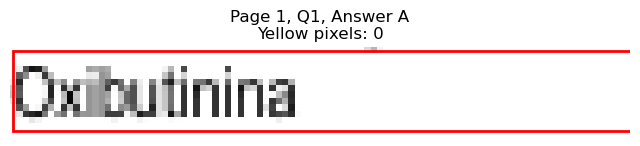

Page 1, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=120.0, y1=114.7
Page 1, Q1, B: Yellow pixels: 0
Page 1, Q1, B: Total non-white pixels: 360
Page 1, Q1, B: Yellow percentage: 0.0%


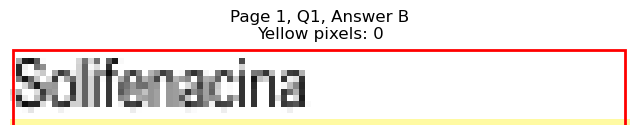

Page 1, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=121.9, y1=127.3
Page 1, Q1, C: Yellow pixels: 1035
Page 1, Q1, C: Total non-white pixels: 1456
Page 1, Q1, C: Yellow percentage: 71.1%


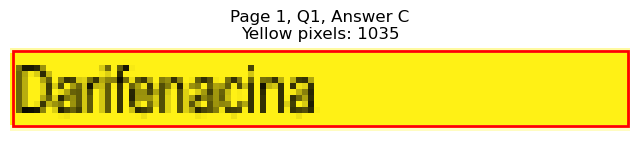

Page 1, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=369.2, y1=102.1
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 201
Page 1, Q1, D: Yellow percentage: 0.0%


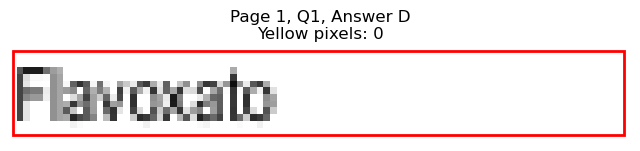

Page 1, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=374.7, y1=114.7
Page 1, Q1, E: Yellow pixels: 0
Page 1, Q1, E: Total non-white pixels: 245
Page 1, Q1, E: Yellow percentage: 0.0%


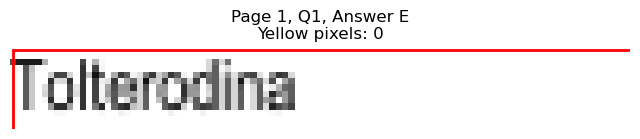


Page 1, Q1 - Selected Answer: C (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=118.5, y1=190.4
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 261
Page 1, Q2, A: Yellow percentage: 0.0%


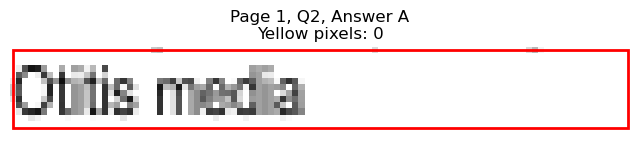

Page 1, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=114.5, y1=203.0
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 241
Page 1, Q2, B: Yellow percentage: 0.0%


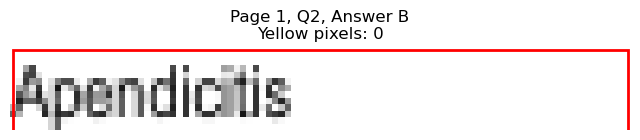

Page 1, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=112.9, y1=215.6
Page 1, Q2, C: Yellow pixels: 0
Page 1, Q2, C: Total non-white pixels: 228
Page 1, Q2, C: Yellow percentage: 0.0%


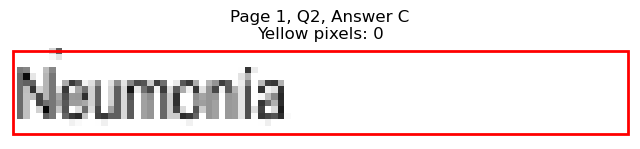

Page 1, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=369.2, y1=190.4
Page 1, Q2, D: Yellow pixels: 93
Page 1, Q2, D: Total non-white pixels: 330
Page 1, Q2, D: Yellow percentage: 28.2%


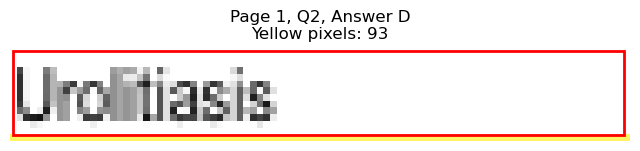

Page 1, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=398.3, y1=203.0
Page 1, Q2, E: Yellow pixels: 1334
Page 1, Q2, E: Total non-white pixels: 1586
Page 1, Q2, E: Yellow percentage: 84.1%


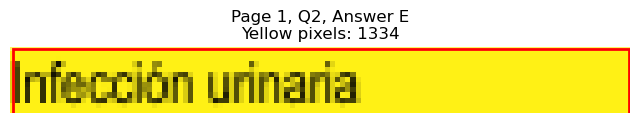


Page 1, Q2 - Selected Answer: E (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=263.4, y1=253.5
Page 1, Q3, A: Yellow pixels: 246
Page 1, Q3, A: Total non-white pixels: 1172
Page 1, Q3, A: Yellow percentage: 21.0%


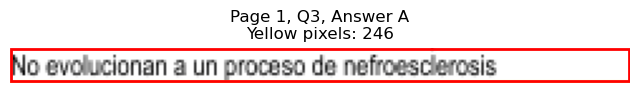

Page 1, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=270.9, y1=266.1
Page 1, Q3, B: Yellow pixels: 2522
Page 1, Q3, B: Total non-white pixels: 3542
Page 1, Q3, B: Yellow percentage: 71.2%


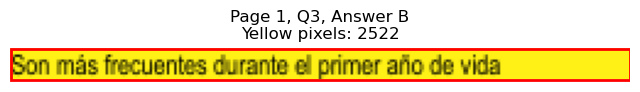

Page 1, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=267.4, y1=278.7
Page 1, Q3, C: Yellow pixels: 0
Page 1, Q3, C: Total non-white pixels: 1187
Page 1, Q3, C: Yellow percentage: 0.0%


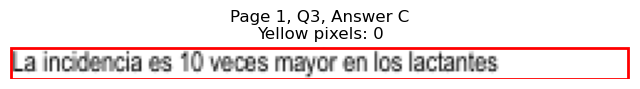

Page 1, Q3 - D: Detected box: x0=68.8, y0=278.8, x1=434.9, y1=291.5
Page 1, Q3, D: Yellow pixels: 0
Page 1, Q3, D: Total non-white pixels: 1728
Page 1, Q3, D: Yellow percentage: 0.0%


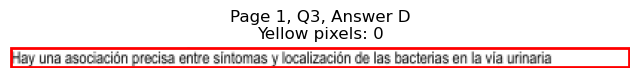

Page 1, Q3 - E: Detected box: x0=68.3, y0=291.4, x1=401.8, y1=304.1
Page 1, Q3, E: Yellow pixels: 0
Page 1, Q3, E: Total non-white pixels: 1679
Page 1, Q3, E: Yellow percentage: 0.0%


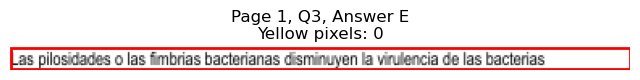


Page 1, Q3 - Selected Answer: B (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=133.5, y1=341.9
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 359
Page 1, Q4, A: Yellow percentage: 0.0%


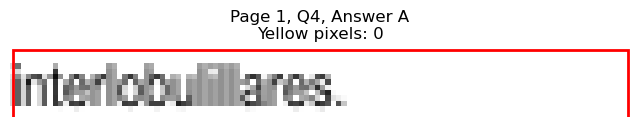

Page 1, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=127.5, y1=354.6
Page 1, Q4, B: Yellow pixels: 0
Page 1, Q4, B: Total non-white pixels: 307
Page 1, Q4, B: Yellow percentage: 0.0%


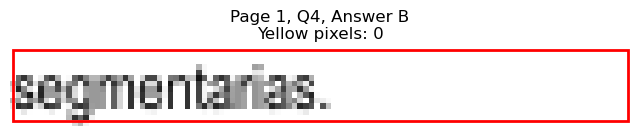

Page 1, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=111.4, y1=367.2
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 216
Page 1, Q4, C: Yellow percentage: 0.0%


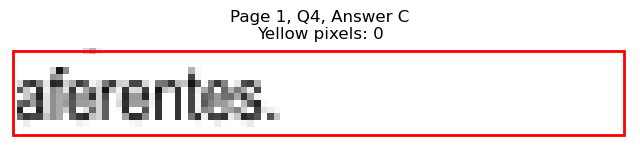

Page 1, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=370.1, y1=341.9
Page 1, Q4, D: Yellow pixels: 0
Page 1, Q4, D: Total non-white pixels: 211
Page 1, Q4, D: Yellow percentage: 0.0%


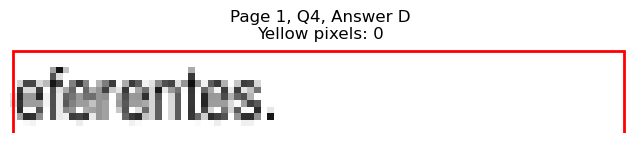

Page 1, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=366.7, y1=354.6
Page 1, Q4, E: Yellow pixels: 1022
Page 1, Q4, E: Total non-white pixels: 1260
Page 1, Q4, E: Yellow percentage: 81.1%


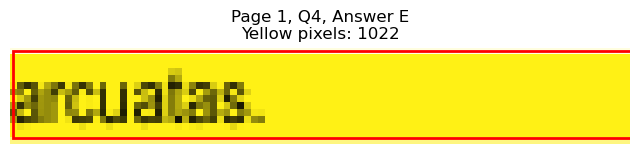


Page 1, Q4 - Selected Answer: E (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=155.5, y1=405.0
Page 1, Q5, A: Yellow pixels: 1504
Page 1, Q5, A: Total non-white pixels: 1794
Page 1, Q5, A: Yellow percentage: 83.8%


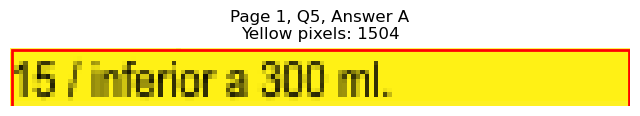

Page 1, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=160.6, y1=417.6
Page 1, Q5, B: Yellow pixels: 143
Page 1, Q5, B: Total non-white pixels: 523
Page 1, Q5, B: Yellow percentage: 27.3%


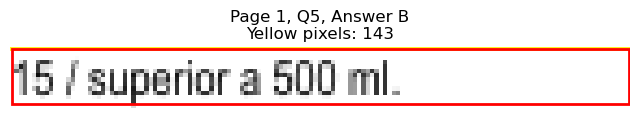

Page 1, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=156.0, y1=430.3
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 367
Page 1, Q5, C: Yellow percentage: 0.0%


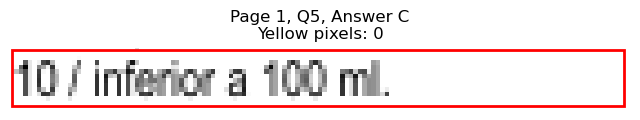

Page 1, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=419.8, y1=405.0
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 414
Page 1, Q5, D: Yellow percentage: 0.0%


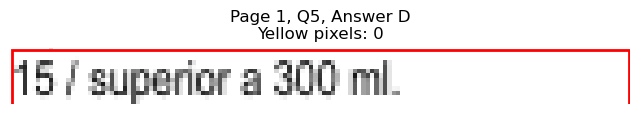

Page 1, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=419.3, y1=417.6
Page 1, Q5, E: Yellow pixels: 0
Page 1, Q5, E: Total non-white pixels: 415
Page 1, Q5, E: Yellow percentage: 0.0%


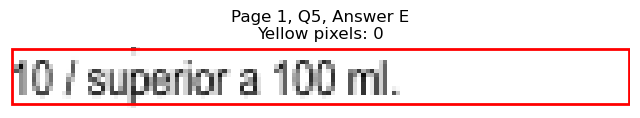


Page 1, Q5 - Selected Answer: A (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=143.1, y1=468.1
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 342
Page 1, Q6, A: Yellow percentage: 0.0%


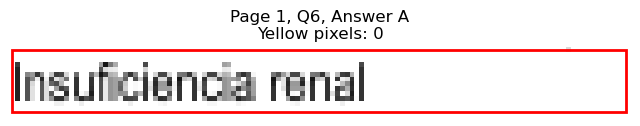

Page 1, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=124.0, y1=480.7
Page 1, Q6, B: Yellow pixels: 0
Page 1, Q6, B: Total non-white pixels: 274
Page 1, Q6, B: Yellow percentage: 0.0%


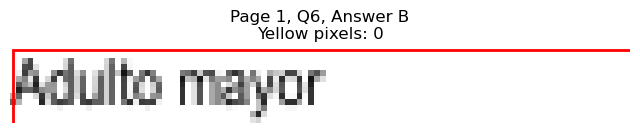

Page 1, Q6 - C: Detected box: x0=68.8, y0=480.8, x1=124.9, y1=493.4
Page 1, Q6, C: Yellow pixels: 1071
Page 1, Q6, C: Total non-white pixels: 1498
Page 1, Q6, C: Yellow percentage: 71.5%


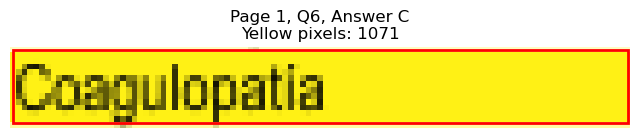

Page 1, Q6 - D: Detected box: x0=327.5, y0=455.5, x1=398.2, y1=468.1
Page 1, Q6, D: Yellow pixels: 0
Page 1, Q6, D: Total non-white pixels: 358
Page 1, Q6, D: Yellow percentage: 0.0%


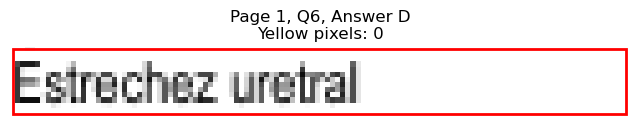

Page 1, Q6 - E: Detected box: x0=327.0, y0=468.1, x1=387.3, y1=480.7
Page 1, Q6, E: Yellow pixels: 0
Page 1, Q6, E: Total non-white pixels: 317
Page 1, Q6, E: Yellow percentage: 0.0%


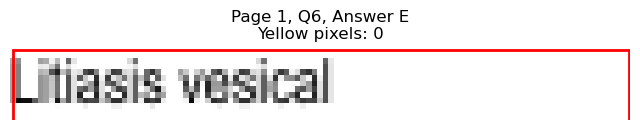


Page 1, Q6 - Selected Answer: C (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=68.3, y0=518.6, x1=125.4, y1=531.2
Page 1, Q7, A: Yellow pixels: 1166
Page 1, Q7, A: Total non-white pixels: 1512
Page 1, Q7, A: Yellow percentage: 77.1%


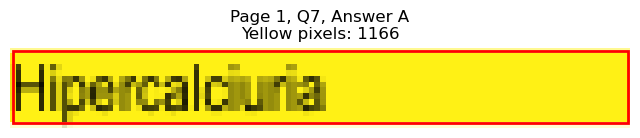

Page 1, Q7 - B: Detected box: x0=68.3, y0=531.2, x1=124.0, y1=543.8
Page 1, Q7, B: Yellow pixels: 0
Page 1, Q7, B: Total non-white pixels: 376
Page 1, Q7, B: Yellow percentage: 0.0%


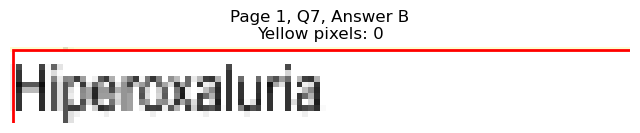

Page 1, Q7 - C: Detected box: x0=68.8, y0=543.8, x1=128.4, y1=556.4
Page 1, Q7, C: Yellow pixels: 0
Page 1, Q7, C: Total non-white pixels: 329
Page 1, Q7, C: Yellow percentage: 0.0%


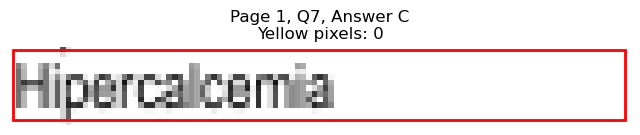

Page 1, Q7 - D: Detected box: x0=327.5, y0=518.6, x1=390.7, y1=531.2
Page 1, Q7, D: Yellow pixels: 0
Page 1, Q7, D: Total non-white pixels: 335
Page 1, Q7, D: Yellow percentage: 0.0%


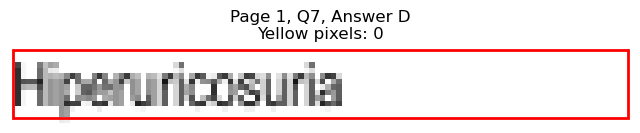

Page 1, Q7 - E: Detected box: x0=327.0, y0=531.2, x1=385.7, y1=543.8
Page 1, Q7, E: Yellow pixels: 0
Page 1, Q7, E: Total non-white pixels: 305
Page 1, Q7, E: Yellow percentage: 0.0%


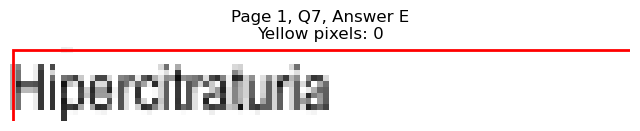


Page 1, Q7 - Selected Answer: A (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=68.3, y0=581.7, x1=119.4, y1=594.4
Page 1, Q8, A: Yellow pixels: 1052
Page 1, Q8, A: Total non-white pixels: 1428
Page 1, Q8, A: Yellow percentage: 73.7%


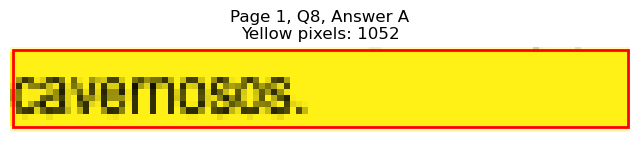

Page 1, Q8 - B: Detected box: x0=68.3, y0=594.3, x1=126.5, y1=607.0
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 412
Page 1, Q8, B: Yellow percentage: 0.0%


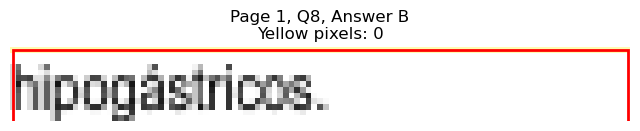

Page 1, Q8 - C: Detected box: x0=68.8, y0=606.9, x1=113.4, y1=619.6
Page 1, Q8, C: Yellow pixels: 0
Page 1, Q8, C: Total non-white pixels: 239
Page 1, Q8, C: Yellow percentage: 0.0%


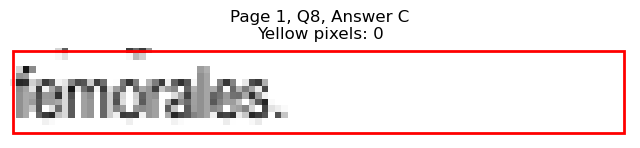

Page 1, Q8 - D: Detected box: x0=327.5, y0=581.7, x1=369.7, y1=594.4
Page 1, Q8, D: Yellow pixels: 0
Page 1, Q8, D: Total non-white pixels: 219
Page 1, Q8, D: Yellow percentage: 0.0%


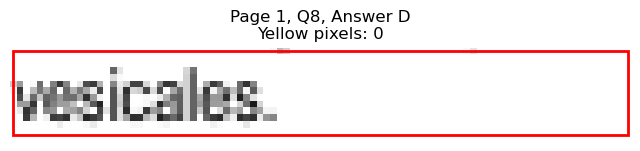

Page 1, Q8 - E: Detected box: x0=327.0, y0=594.3, x1=383.7, y1=607.0
Page 1, Q8, E: Yellow pixels: 0
Page 1, Q8, E: Total non-white pixels: 317
Page 1, Q8, E: Yellow percentage: 0.0%


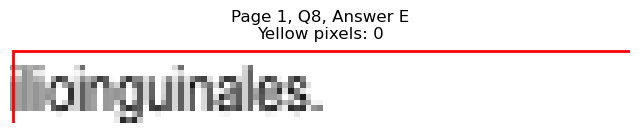


Page 1, Q8 - Selected Answer: A (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=68.3, y0=644.9, x1=307.6, y1=657.5
Page 1, Q9, A: Yellow pixels: 2872
Page 1, Q9, A: Total non-white pixels: 4060
Page 1, Q9, A: Yellow percentage: 70.7%


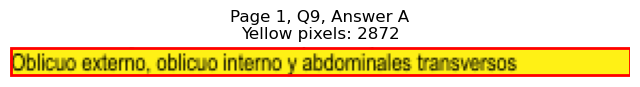

Page 1, Q9 - B: Detected box: x0=68.3, y0=657.5, x1=284.4, y1=670.1
Page 1, Q9, B: Yellow pixels: 267
Page 1, Q9, B: Total non-white pixels: 1264
Page 1, Q9, B: Yellow percentage: 21.1%


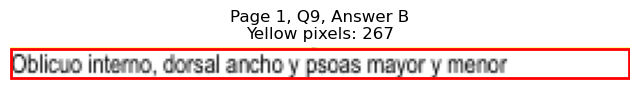

Page 1, Q9 - C: Detected box: x0=68.8, y0=670.1, x1=290.4, y1=682.7
Page 1, Q9, C: Yellow pixels: 0
Page 1, Q9, C: Total non-white pixels: 1075
Page 1, Q9, C: Yellow percentage: 0.0%


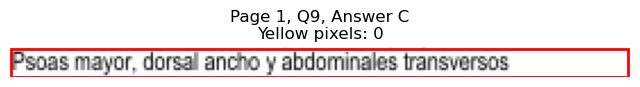

Page 1, Q9 - D: Detected box: x0=68.8, y0=682.7, x1=284.6, y1=695.3
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 1028
Page 1, Q9, D: Yellow percentage: 0.0%


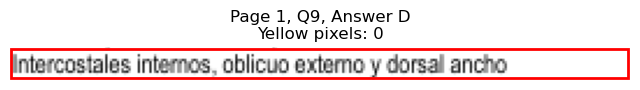

Page 1, Q9 - E: Detected box: x0=68.3, y0=695.4, x1=297.5, y1=708.0
Page 1, Q9, E: Yellow pixels: 0
Page 1, Q9, E: Total non-white pixels: 1111
Page 1, Q9, E: Yellow percentage: 0.0%


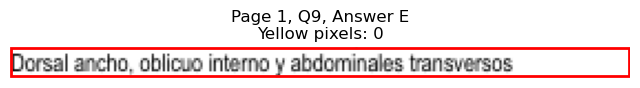


Page 1, Q9 - Selected Answer: A (based on yellow pixel count)





Page 2: Found 10 questions
Page 2, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=156.6, y1=127.3
Page 2, Q1, A: Yellow pixels: 0
Page 2, Q1, A: Total non-white pixels: 442
Page 2, Q1, A: Yellow percentage: 0.0%


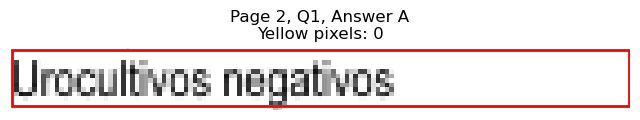

Page 2, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=154.8, y1=139.9
Page 2, Q1, B: Yellow pixels: 0
Page 2, Q1, B: Total non-white pixels: 392
Page 2, Q1, B: Yellow percentage: 0.0%


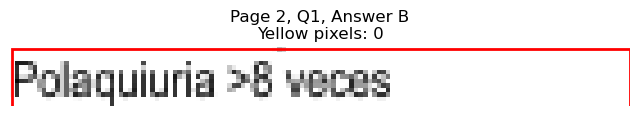

Page 2, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=151.3, y1=152.6
Page 2, Q1, C: Yellow pixels: 0
Page 2, Q1, C: Total non-white pixels: 399
Page 2, Q1, C: Yellow percentage: 0.0%


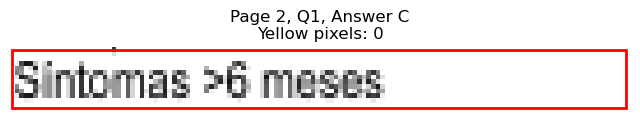

Page 2, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=411.3, y1=127.3
Page 2, Q1, D: Yellow pixels: 1329
Page 2, Q1, D: Total non-white pixels: 1890
Page 2, Q1, D: Yellow percentage: 70.3%


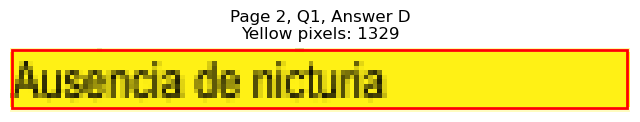

Page 2, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=434.5, y1=139.9
Page 2, Q1, E: Yellow pixels: 0
Page 2, Q1, E: Total non-white pixels: 709
Page 2, Q1, E: Yellow percentage: 0.0%


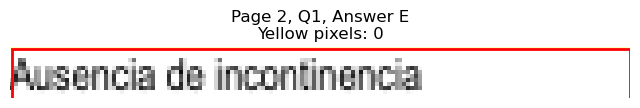


Page 2, Q1 - Selected Answer: D (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=177.6, y1=190.4
Page 2, Q2, A: Yellow pixels: 1505
Page 2, Q2, A: Total non-white pixels: 2240
Page 2, Q2, A: Yellow percentage: 67.2%


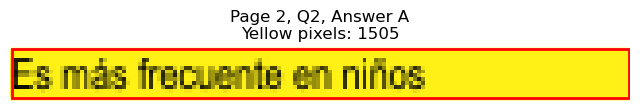

Page 2, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=124.9, y1=203.0
Page 2, Q2, B: Yellow pixels: 0
Page 2, Q2, B: Total non-white pixels: 389
Page 2, Q2, B: Yellow percentage: 0.0%


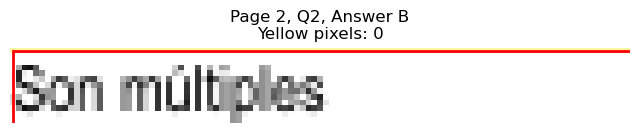

Page 2, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=188.4, y1=215.6
Page 2, Q2, C: Yellow pixels: 0
Page 2, Q2, C: Total non-white pixels: 550
Page 2, Q2, C: Yellow percentage: 0.0%


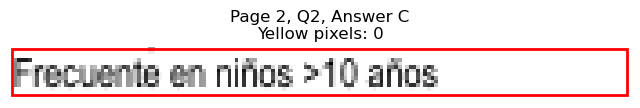

Page 2, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=444.4, y1=190.4
Page 2, Q2, D: Yellow pixels: 0
Page 2, Q2, D: Total non-white pixels: 554
Page 2, Q2, D: Yellow percentage: 0.0%


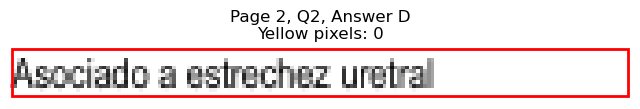

Page 2, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=454.0, y1=203.0
Page 2, Q2, E: Yellow pixels: 0
Page 2, Q2, E: Total non-white pixels: 636
Page 2, Q2, E: Yellow percentage: 0.0%


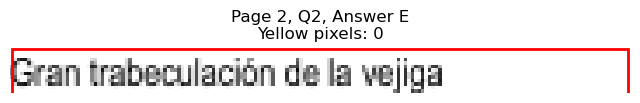


Page 2, Q2 - Selected Answer: A (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=112.0, y1=266.1
Page 2, Q3, A: Yellow pixels: 1056
Page 2, Q3, A: Total non-white pixels: 1316
Page 2, Q3, A: Yellow percentage: 80.2%


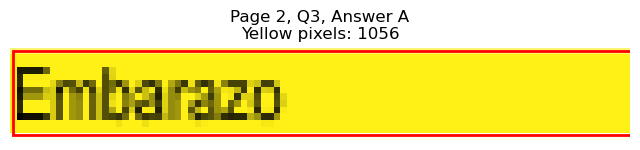

Page 2, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=124.9, y1=278.7
Page 2, Q3, B: Yellow pixels: 0
Page 2, Q3, B: Total non-white pixels: 405
Page 2, Q3, B: Yellow percentage: 0.0%


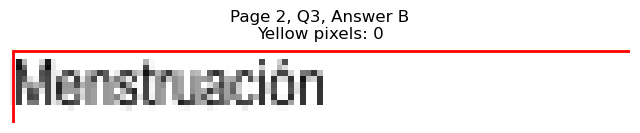

Page 2, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=126.5, y1=291.5
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 290
Page 2, Q3, C: Yellow percentage: 0.0%


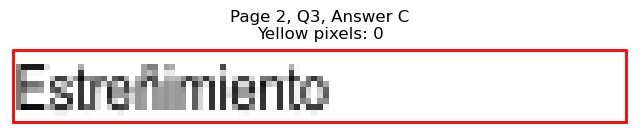

Page 2, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=379.3, y1=266.1
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 276
Page 2, Q3, D: Yellow percentage: 0.0%


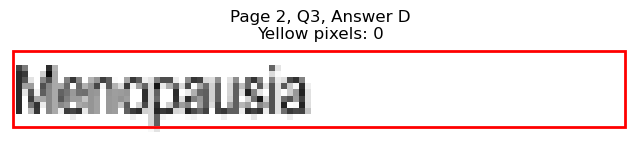

Page 2, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=402.3, y1=278.7
Page 2, Q3, E: Yellow pixels: 0
Page 2, Q3, E: Total non-white pixels: 387
Page 2, Q3, E: Yellow percentage: 0.0%


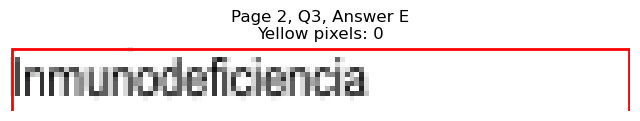


Page 2, Q3 - Selected Answer: A (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=139.6, y1=341.9
Page 2, Q4, A: Yellow pixels: 0
Page 2, Q4, A: Total non-white pixels: 356
Page 2, Q4, A: Yellow percentage: 0.0%


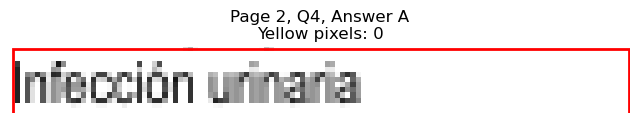

Page 2, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=147.5, y1=354.6
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 426
Page 2, Q4, B: Yellow percentage: 0.0%


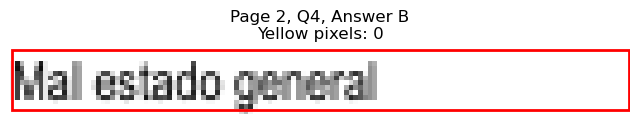

Page 2, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=134.1, y1=367.2
Page 2, Q4, C: Yellow pixels: 0
Page 2, Q4, C: Total non-white pixels: 321
Page 2, Q4, C: Yellow percentage: 0.0%


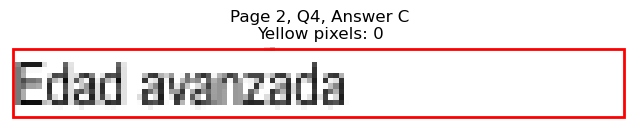

Page 2, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=423.3, y1=341.9
Page 2, Q4, D: Yellow pixels: 1513
Page 2, Q4, D: Total non-white pixels: 1911
Page 2, Q4, D: Yellow percentage: 79.2%


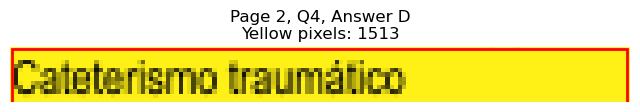

Page 2, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=390.8, y1=354.6
Page 2, Q4, E: Yellow pixels: 114
Page 2, Q4, E: Total non-white pixels: 466
Page 2, Q4, E: Yellow percentage: 24.5%


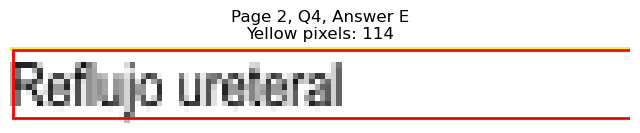


Page 2, Q4 - Selected Answer: D (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=127.5, y1=430.3
Page 2, Q5, A: Yellow pixels: 0
Page 2, Q5, A: Total non-white pixels: 298
Page 2, Q5, A: Yellow percentage: 0.0%


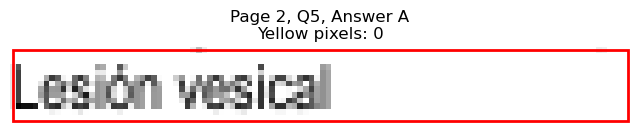

Page 2, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=141.0, y1=442.9
Page 2, Q5, B: Yellow pixels: 0
Page 2, Q5, B: Total non-white pixels: 355
Page 2, Q5, B: Yellow percentage: 0.0%


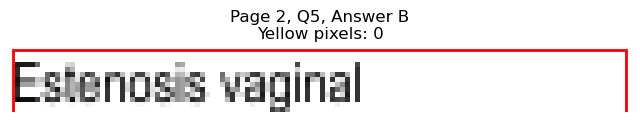

Page 2, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=158.1, y1=455.5
Page 2, Q5, C: Yellow pixels: 0
Page 2, Q5, C: Total non-white pixels: 440
Page 2, Q5, C: Yellow percentage: 0.0%


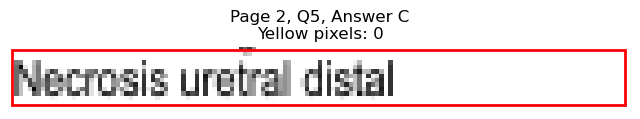

Page 2, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=397.3, y1=430.3
Page 2, Q5, D: Yellow pixels: 121
Page 2, Q5, D: Total non-white pixels: 474
Page 2, Q5, D: Yellow percentage: 25.5%


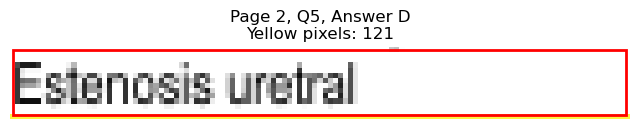

Page 2, Q5 - E: Detected box: x0=327.0, y0=430.2, x1=441.9, y1=442.9
Page 2, Q5, E: Yellow pixels: 1707
Page 2, Q5, E: Total non-white pixels: 2145
Page 2, Q5, E: Yellow percentage: 79.6%


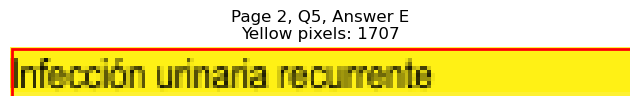


Page 2, Q5 - Selected Answer: E (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=169.1, y1=493.4
Page 2, Q6, A: Yellow pixels: 152
Page 2, Q6, A: Total non-white pixels: 687
Page 2, Q6, A: Yellow percentage: 22.1%


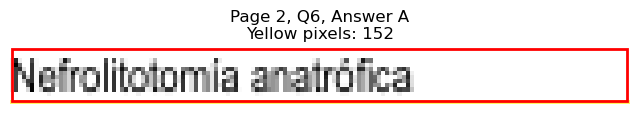

Page 2, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=174.6, y1=506.0
Page 2, Q6, B: Yellow pixels: 1600
Page 2, Q6, B: Total non-white pixels: 2043
Page 2, Q6, B: Yellow percentage: 78.3%


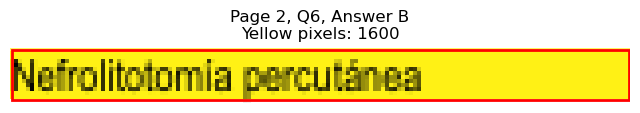

Page 2, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=178.6, y1=518.6
Page 2, Q6, C: Yellow pixels: 159
Page 2, Q6, C: Total non-white pixels: 725
Page 2, Q6, C: Yellow percentage: 21.9%


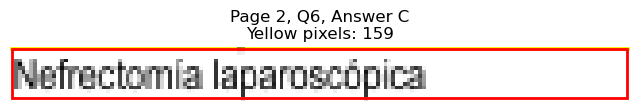

Page 2, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=379.1, y1=493.4
Page 2, Q6, D: Yellow pixels: 0
Page 2, Q6, D: Total non-white pixels: 251
Page 2, Q6, D: Yellow percentage: 0.0%


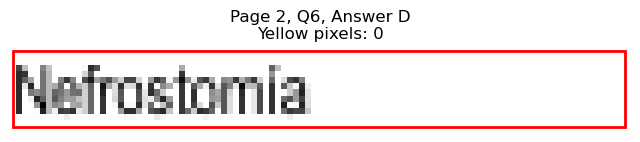

Page 2, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=383.7, y1=506.0
Page 2, Q6, E: Yellow pixels: 0
Page 2, Q6, E: Total non-white pixels: 313
Page 2, Q6, E: Yellow percentage: 0.0%


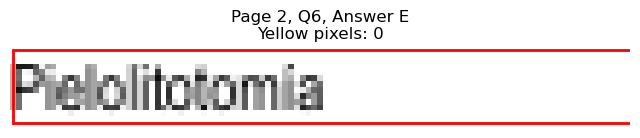


Page 2, Q6 - Selected Answer: B (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=80.9, y1=556.4
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 57
Page 2, Q7, A: Yellow percentage: 0.0%


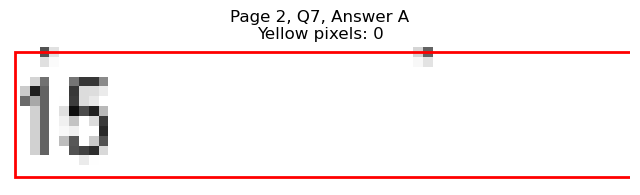

Page 2, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=80.9, y1=569.2
Page 2, Q7, B: Yellow pixels: 0
Page 2, Q7, B: Total non-white pixels: 51
Page 2, Q7, B: Yellow percentage: 0.0%


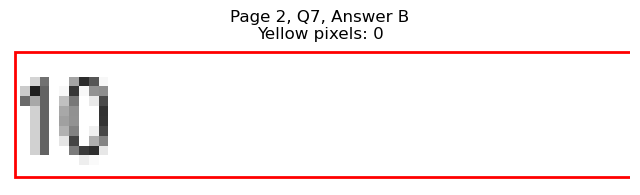

Page 2, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=81.4, y1=581.8
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 45
Page 2, Q7, C: Yellow percentage: 0.0%


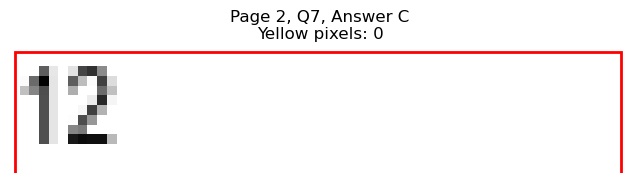

Page 2, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=340.1, y1=556.4
Page 2, Q7, D: Yellow pixels: 793
Page 2, Q7, D: Total non-white pixels: 896
Page 2, Q7, D: Yellow percentage: 88.5%


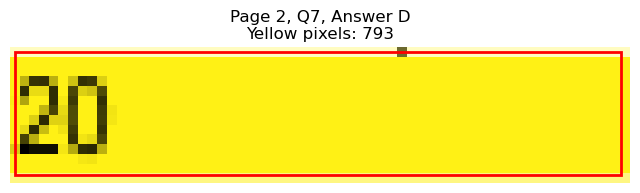

Page 2, Q7 - E: Detected box: x0=315.4, y0=556.5, x1=323.9, y1=569.2
Page 2, Q7, E: Yellow pixels: 59
Page 2, Q7, E: Total non-white pixels: 128
Page 2, Q7, E: Yellow percentage: 46.1%


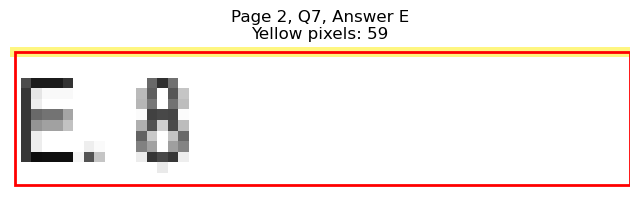


Page 2, Q7 - Selected Answer: D (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=94.3, y1=619.6
Page 2, Q8, A: Yellow pixels: 0
Page 2, Q8, A: Total non-white pixels: 140
Page 2, Q8, A: Yellow percentage: 0.0%


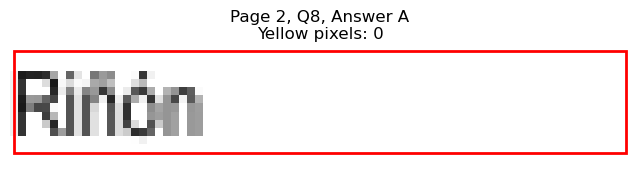

Page 2, Q8 - B: Detected box: x0=68.3, y0=619.6, x1=110.9, y1=632.3
Page 2, Q8, B: Yellow pixels: 927
Page 2, Q8, B: Total non-white pixels: 1302
Page 2, Q8, B: Yellow percentage: 71.2%


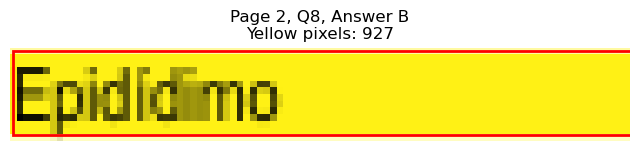

Page 2, Q8 - C: Detected box: x0=68.8, y0=632.2, x1=96.4, y1=644.9
Page 2, Q8, C: Yellow pixels: 0
Page 2, Q8, C: Total non-white pixels: 214
Page 2, Q8, C: Yellow percentage: 0.0%


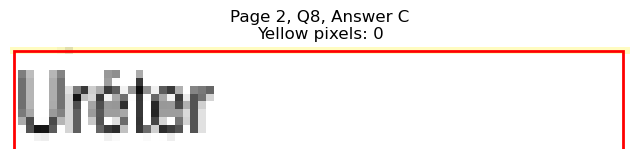

Page 2, Q8 - D: Detected box: x0=327.5, y0=606.9, x1=355.1, y1=619.6
Page 2, Q8, D: Yellow pixels: 0
Page 2, Q8, D: Total non-white pixels: 141
Page 2, Q8, D: Yellow percentage: 0.0%


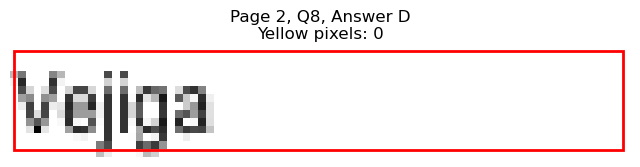

Page 2, Q8 - E: Detected box: x0=327.0, y0=619.6, x1=363.2, y1=632.3
Page 2, Q8, E: Yellow pixels: 0
Page 2, Q8, E: Total non-white pixels: 194
Page 2, Q8, E: Yellow percentage: 0.0%


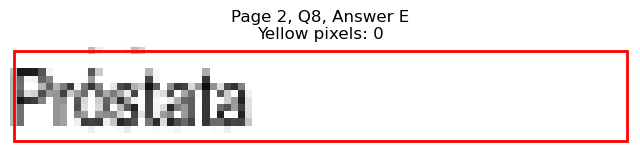


Page 2, Q8 - Selected Answer: B (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=68.3, y0=670.1, x1=100.9, y1=682.7
Page 2, Q9, A: Yellow pixels: 0
Page 2, Q9, A: Total non-white pixels: 210
Page 2, Q9, A: Yellow percentage: 0.0%


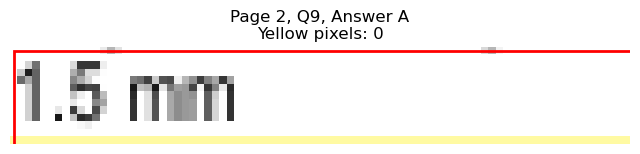

Page 2, Q9 - B: Detected box: x0=68.3, y0=682.7, x1=93.4, y1=695.3
Page 2, Q9, B: Yellow pixels: 838
Page 2, Q9, B: Total non-white pixels: 1064
Page 2, Q9, B: Yellow percentage: 78.8%


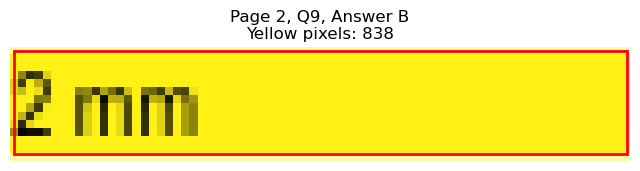

Page 2, Q9 - C: Detected box: x0=68.8, y0=695.4, x1=106.3, y1=708.0
Page 2, Q9, C: Yellow pixels: 0
Page 2, Q9, C: Total non-white pixels: 250
Page 2, Q9, C: Yellow percentage: 0.0%


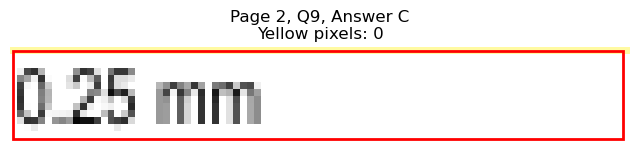

Page 2, Q9 - D: Detected box: x0=327.5, y0=670.1, x1=352.6, y1=682.7
Page 2, Q9, D: Yellow pixels: 0
Page 2, Q9, D: Total non-white pixels: 81
Page 2, Q9, D: Yellow percentage: 0.0%


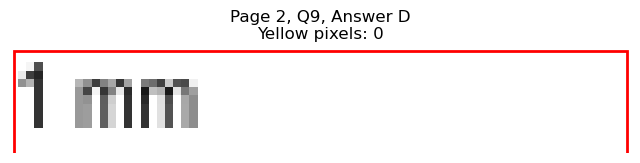

Page 2, Q9 - E: Detected box: x0=327.0, y0=682.7, x1=364.6, y1=695.3
Page 2, Q9, E: Yellow pixels: 0
Page 2, Q9, E: Total non-white pixels: 163
Page 2, Q9, E: Yellow percentage: 0.0%


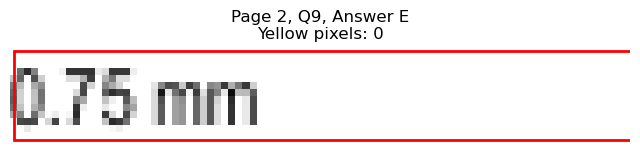


Page 2, Q9 - Selected Answer: B (based on yellow pixel count)




Page 2, Q10 - A: Detected box: x0=68.3, y0=733.2, x1=142.0, y1=745.8
Page 2, Q10, A: Yellow pixels: 0
Page 2, Q10, A: Total non-white pixels: 412
Page 2, Q10, A: Yellow percentage: 0.0%


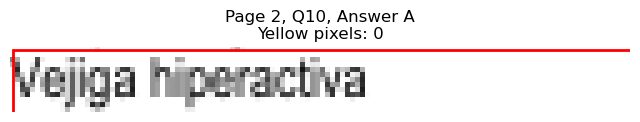

Page 2, Q10 - B: Detected box: x0=68.3, y0=745.8, x1=143.5, y1=758.4
Page 2, Q10, B: Yellow pixels: 0
Page 2, Q10, B: Total non-white pixels: 392
Page 2, Q10, B: Yellow percentage: 0.0%


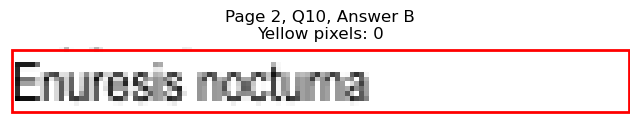

Page 2, Q10 - C: Detected box: x0=68.8, y0=758.5, x1=169.1, y1=771.2
Page 2, Q10, C: Yellow pixels: 0
Page 2, Q10, C: Total non-white pixels: 508
Page 2, Q10, C: Yellow percentage: 0.0%


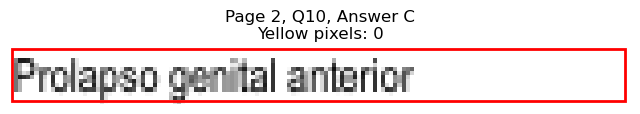

Page 2, Q10 - D: Detected box: x0=327.5, y0=733.2, x1=403.3, y1=745.8
Page 2, Q10, D: Yellow pixels: 0
Page 2, Q10, D: Total non-white pixels: 512
Page 2, Q10, D: Yellow percentage: 0.0%


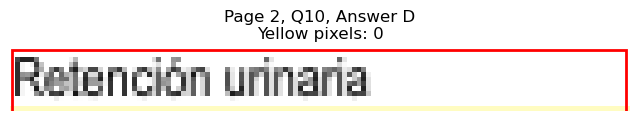

Page 2, Q10 - E: Detected box: x0=327.0, y0=745.8, x1=432.4, y1=758.4
Page 2, Q10, E: Yellow pixels: 1655
Page 2, Q10, E: Total non-white pixels: 2184
Page 2, Q10, E: Yellow percentage: 75.8%


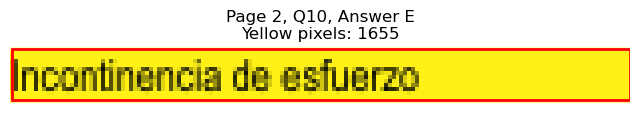


Page 2, Q10 - Selected Answer: E (based on yellow pixel count)





Page 3: Found 10 questions
Page 3, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=118.5, y1=102.1
Page 3, Q1, A: Yellow pixels: 0
Page 3, Q1, A: Total non-white pixels: 252
Page 3, Q1, A: Yellow percentage: 0.0%


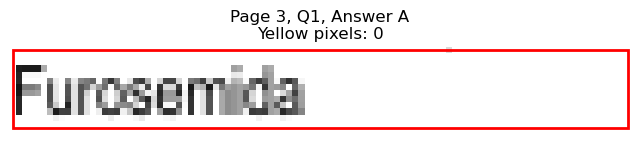

Page 3, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=130.0, y1=114.7
Page 3, Q1, B: Yellow pixels: 0
Page 3, Q1, B: Total non-white pixels: 309
Page 3, Q1, B: Yellow percentage: 0.0%


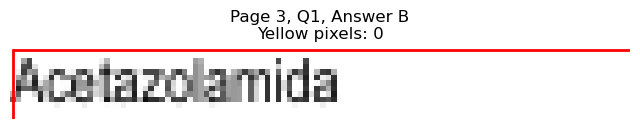

Page 3, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=136.5, y1=127.3
Page 3, Q1, C: Yellow pixels: 0
Page 3, Q1, C: Total non-white pixels: 350
Page 3, Q1, C: Yellow percentage: 0.0%


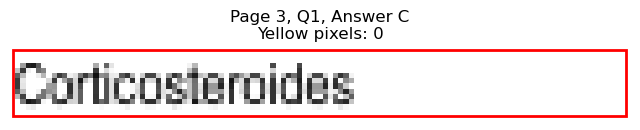

Page 3, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=365.1, y1=102.1
Page 3, Q1, D: Yellow pixels: 89
Page 3, Q1, D: Total non-white pixels: 275
Page 3, Q1, D: Yellow percentage: 32.4%


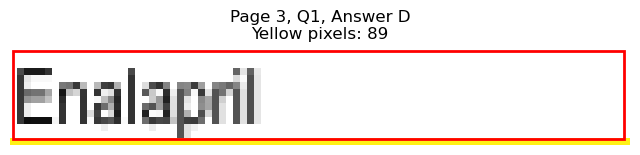

Page 3, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=378.2, y1=114.7
Page 3, Q1, E: Yellow pixels: 1142
Page 3, Q1, E: Total non-white pixels: 1326
Page 3, Q1, E: Yellow percentage: 86.1%


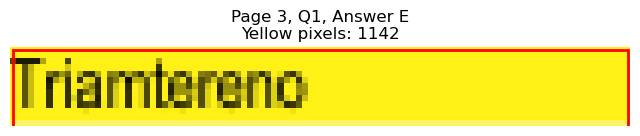


Page 3, Q1 - Selected Answer: E (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=126.5, y1=177.8
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 320
Page 3, Q2, A: Yellow percentage: 0.0%


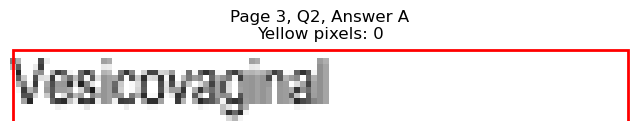

Page 3, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=121.5, y1=190.4
Page 3, Q2, B: Yellow pixels: 0
Page 3, Q2, B: Total non-white pixels: 294
Page 3, Q2, B: Yellow percentage: 0.0%


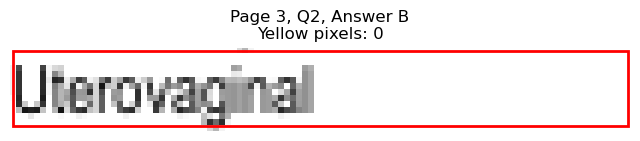

Page 3, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=120.4, y1=203.0
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 275
Page 3, Q2, C: Yellow percentage: 0.0%


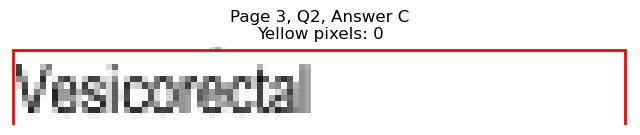

Page 3, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=382.1, y1=177.8
Page 3, Q2, D: Yellow pixels: 0
Page 3, Q2, D: Total non-white pixels: 393
Page 3, Q2, D: Yellow percentage: 0.0%


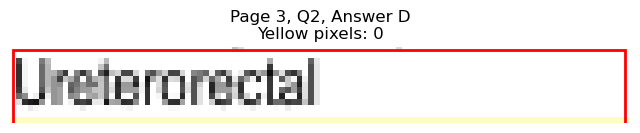

Page 3, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=388.3, y1=190.4
Page 3, Q2, E: Yellow pixels: 1112
Page 3, Q2, E: Total non-white pixels: 1568
Page 3, Q2, E: Yellow percentage: 70.9%


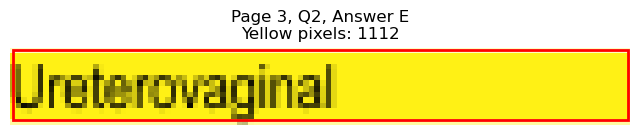


Page 3, Q2 - Selected Answer: E (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=167.1, y1=240.9
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 485
Page 3, Q3, A: Yellow percentage: 0.0%


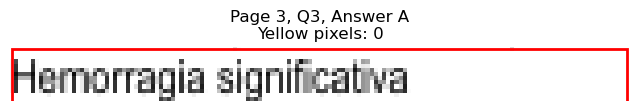

Page 3, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=130.5, y1=253.5
Page 3, Q3, B: Yellow pixels: 0
Page 3, Q3, B: Total non-white pixels: 318
Page 3, Q3, B: Yellow percentage: 0.0%


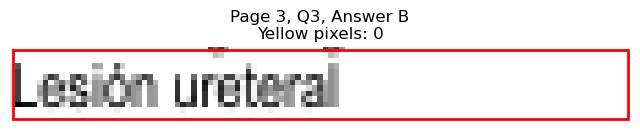

Page 3, Q3 - C: Detected box: x0=68.8, y0=253.5, x1=161.5, y1=266.1
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 464
Page 3, Q3, C: Yellow percentage: 0.0%


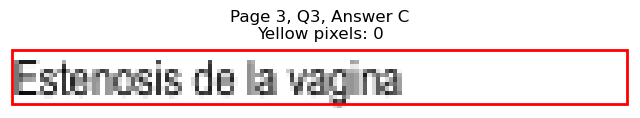

Page 3, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=398.8, y1=240.9
Page 3, Q3, D: Yellow pixels: 0
Page 3, Q3, D: Total non-white pixels: 492
Page 3, Q3, D: Yellow percentage: 0.0%


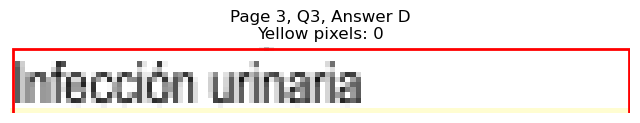

Page 3, Q3 - E: Detected box: x0=327.0, y0=240.9, x1=412.9, y1=253.5
Page 3, Q3, E: Yellow pixels: 1420
Page 3, Q3, E: Total non-white pixels: 1904
Page 3, Q3, E: Yellow percentage: 74.6%


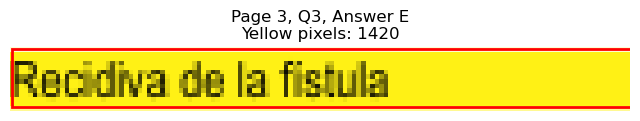


Page 3, Q3 - Selected Answer: E (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=106.9, y1=329.3
Page 3, Q4, A: Yellow pixels: 0
Page 3, Q4, A: Total non-white pixels: 206
Page 3, Q4, A: Yellow percentage: 0.0%


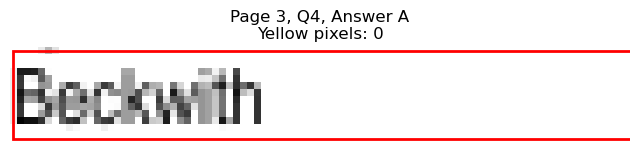

Page 3, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=118.9, y1=341.9
Page 3, Q4, B: Yellow pixels: 0
Page 3, Q4, B: Total non-white pixels: 245
Page 3, Q4, B: Yellow percentage: 0.0%


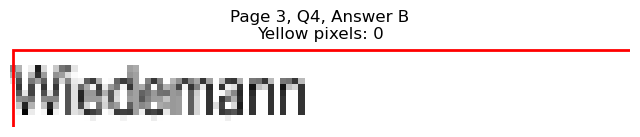

Page 3, Q4 - C: Detected box: x0=68.8, y0=341.9, x1=98.4, y1=354.6
Page 3, Q4, C: Yellow pixels: 936
Page 3, Q4, C: Total non-white pixels: 1134
Page 3, Q4, C: Yellow percentage: 82.5%


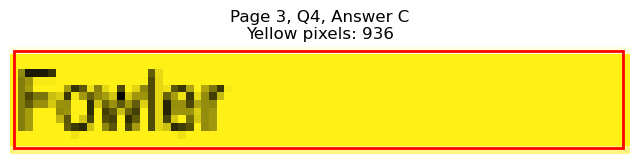

Page 3, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=353.1, y1=329.3
Page 3, Q4, D: Yellow pixels: 0
Page 3, Q4, D: Total non-white pixels: 111
Page 3, Q4, D: Yellow percentage: 0.0%


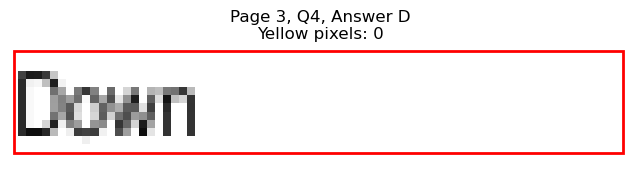

Page 3, Q4 - E: Detected box: x0=327.0, y0=329.2, x1=353.1, y1=341.9
Page 3, Q4, E: Yellow pixels: 0
Page 3, Q4, E: Total non-white pixels: 129
Page 3, Q4, E: Yellow percentage: 0.0%


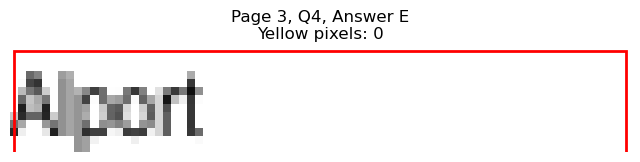


Page 3, Q4 - Selected Answer: C (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=68.3, y0=379.7, x1=172.1, y1=392.4
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 517
Page 3, Q5, A: Yellow percentage: 0.0%


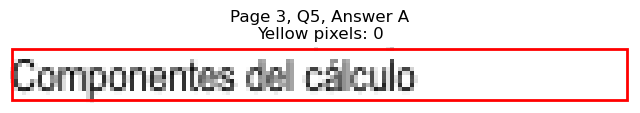

Page 3, Q5 - B: Detected box: x0=68.3, y0=392.3, x1=216.8, y1=405.0
Page 3, Q5, B: Yellow pixels: 0
Page 3, Q5, B: Total non-white pixels: 724
Page 3, Q5, B: Yellow percentage: 0.0%


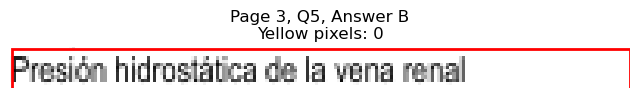

Page 3, Q5 - C: Detected box: x0=68.8, y0=404.9, x1=167.1, y1=417.6
Page 3, Q5, C: Yellow pixels: 0
Page 3, Q5, C: Total non-white pixels: 507
Page 3, Q5, C: Yellow percentage: 0.0%


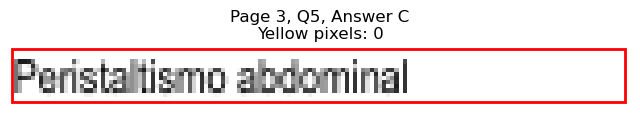

Page 3, Q5 - D: Detected box: x0=327.5, y0=379.7, x1=438.9, y1=392.4
Page 3, Q5, D: Yellow pixels: 162
Page 3, Q5, D: Total non-white pixels: 732
Page 3, Q5, D: Yellow percentage: 22.1%


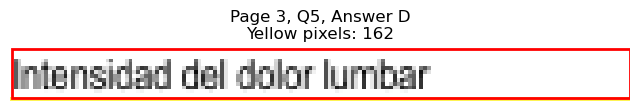

Page 3, Q5 - E: Detected box: x0=327.0, y0=392.3, x1=466.0, y1=405.0
Page 3, Q5, E: Yellow pixels: 1924
Page 3, Q5, E: Total non-white pixels: 2470
Page 3, Q5, E: Yellow percentage: 77.9%


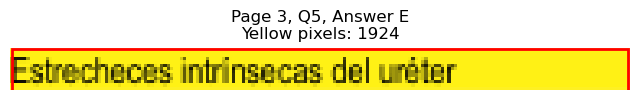


Page 3, Q5 - Selected Answer: E (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=68.3, y0=442.8, x1=127.0, y1=455.5
Page 3, Q6, A: Yellow pixels: 109
Page 3, Q6, A: Total non-white pixels: 422
Page 3, Q6, A: Yellow percentage: 25.8%


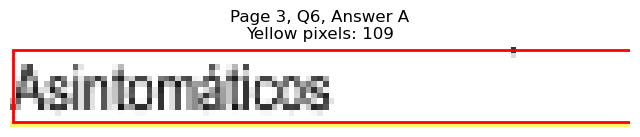

Page 3, Q6 - B: Detected box: x0=68.3, y0=455.5, x1=154.6, y1=468.1
Page 3, Q6, B: Yellow pixels: 1452
Page 3, Q6, B: Total non-white pixels: 1918
Page 3, Q6, B: Yellow percentage: 75.7%


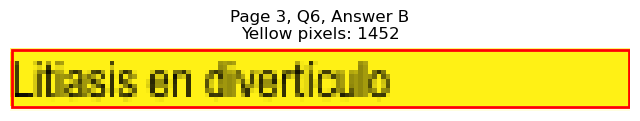

Page 3, Q6 - C: Detected box: x0=68.8, y0=468.1, x1=135.0, y1=480.7
Page 3, Q6, C: Yellow pixels: 0
Page 3, Q6, C: Total non-white pixels: 429
Page 3, Q6, C: Yellow percentage: 0.0%


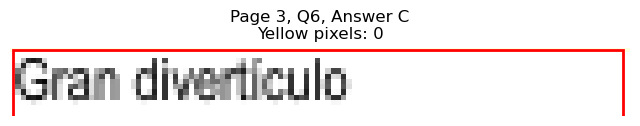

Page 3, Q6 - D: Detected box: x0=327.5, y0=442.8, x1=392.2, y1=455.5
Page 3, Q6, D: Yellow pixels: 0
Page 3, Q6, D: Total non-white pixels: 336
Page 3, Q6, D: Yellow percentage: 0.0%


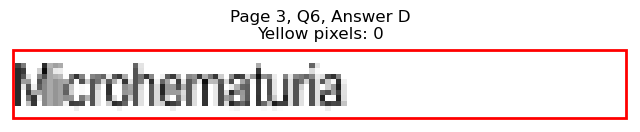

Page 3, Q6 - E: Detected box: x0=327.0, y0=455.5, x1=415.4, y1=468.1
Page 3, Q6, E: Yellow pixels: 0
Page 3, Q6, E: Total non-white pixels: 443
Page 3, Q6, E: Yellow percentage: 0.0%


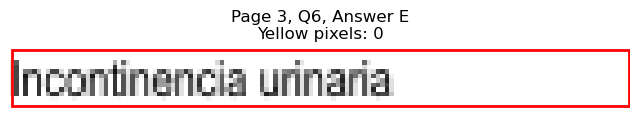


Page 3, Q6 - Selected Answer: B (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=68.3, y0=506.0, x1=139.0, y1=518.6
Page 3, Q7, A: Yellow pixels: 0
Page 3, Q7, A: Total non-white pixels: 353
Page 3, Q7, A: Yellow percentage: 0.0%


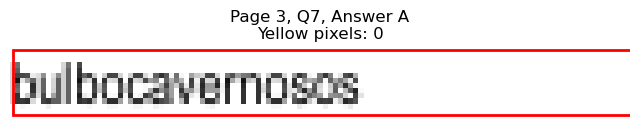

Page 3, Q7 - B: Detected box: x0=68.3, y0=518.6, x1=120.5, y1=531.2
Page 3, Q7, B: Yellow pixels: 0
Page 3, Q7, B: Total non-white pixels: 269
Page 3, Q7, B: Yellow percentage: 0.0%


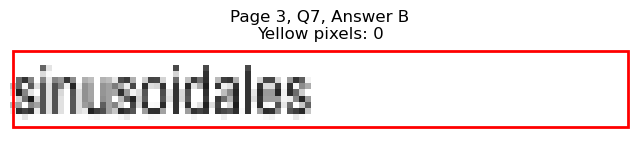

Page 3, Q7 - C: Detected box: x0=68.8, y0=531.2, x1=132.0, y1=543.8
Page 3, Q7, C: Yellow pixels: 0
Page 3, Q7, C: Total non-white pixels: 336
Page 3, Q7, C: Yellow percentage: 0.0%


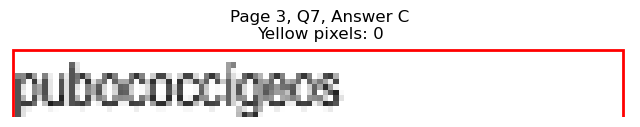

Page 3, Q7 - D: Detected box: x0=327.5, y0=506.0, x1=390.3, y1=518.6
Page 3, Q7, D: Yellow pixels: 114
Page 3, Q7, D: Total non-white pixels: 451
Page 3, Q7, D: Yellow percentage: 25.3%


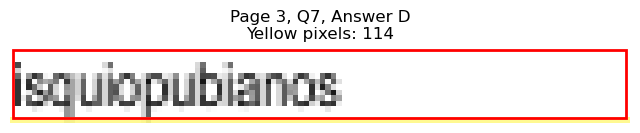

Page 3, Q7 - E: Detected box: x0=327.0, y0=518.6, x1=399.3, y1=531.2
Page 3, Q7, E: Yellow pixels: 1328
Page 3, Q7, E: Total non-white pixels: 1722
Page 3, Q7, E: Yellow percentage: 77.1%


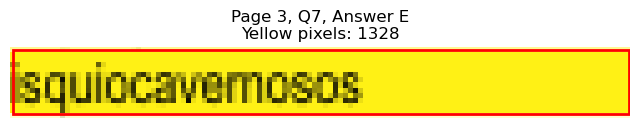


Page 3, Q7 - Selected Answer: E (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=68.3, y0=569.1, x1=129.5, y1=581.8
Page 3, Q8, A: Yellow pixels: 0
Page 3, Q8, A: Total non-white pixels: 334
Page 3, Q8, A: Yellow percentage: 0.0%


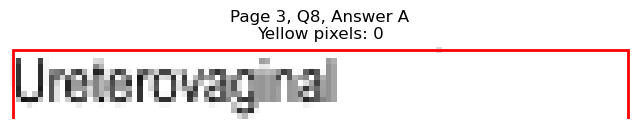

Page 3, Q8 - B: Detected box: x0=68.3, y0=581.7, x1=125.5, y1=594.4
Page 3, Q8, B: Yellow pixels: 0
Page 3, Q8, B: Total non-white pixels: 296
Page 3, Q8, B: Yellow percentage: 0.0%


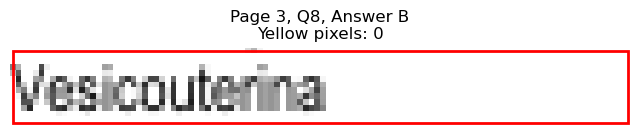

Page 3, Q8 - C: Detected box: x0=68.8, y0=594.3, x1=124.9, y1=607.0
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 262
Page 3, Q8, C: Yellow percentage: 0.0%


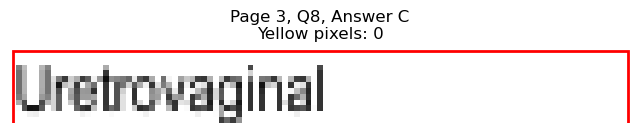

Page 3, Q8 - D: Detected box: x0=327.5, y0=569.1, x1=385.7, y1=581.8
Page 3, Q8, D: Yellow pixels: 1176
Page 3, Q8, D: Total non-white pixels: 1417
Page 3, Q8, D: Yellow percentage: 83.0%


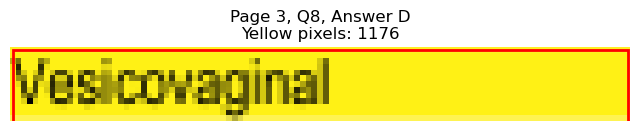

Page 3, Q8 - E: Detected box: x0=327.0, y0=581.7, x1=381.8, y1=594.4
Page 3, Q8, E: Yellow pixels: 104
Page 3, Q8, E: Total non-white pixels: 400
Page 3, Q8, E: Yellow percentage: 26.0%


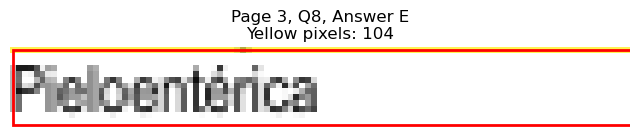


Page 3, Q8 - Selected Answer: D (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=68.3, y0=632.2, x1=95.4, y1=644.9
Page 3, Q9, A: Yellow pixels: 0
Page 3, Q9, A: Total non-white pixels: 197
Page 3, Q9, A: Yellow percentage: 0.0%


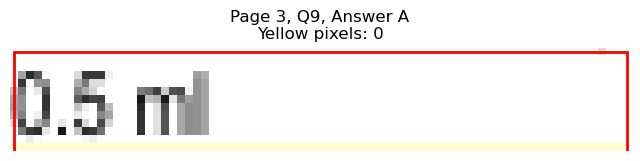

Page 3, Q9 - B: Detected box: x0=68.3, y0=644.9, x1=87.9, y1=657.5
Page 3, Q9, B: Yellow pixels: 855
Page 3, Q9, B: Total non-white pixels: 980
Page 3, Q9, B: Yellow percentage: 87.2%


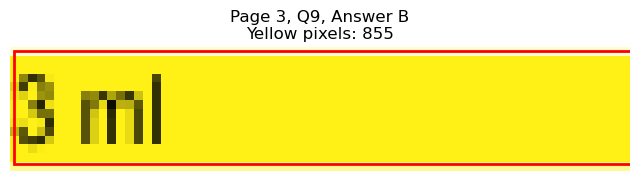

Page 3, Q9 - C: Detected box: x0=68.8, y0=657.5, x1=88.3, y1=670.1
Page 3, Q9, C: Yellow pixels: 71
Page 3, Q9, C: Total non-white pixels: 147
Page 3, Q9, C: Yellow percentage: 48.3%


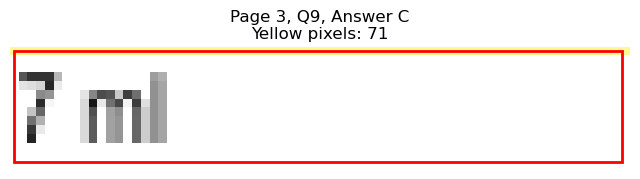

Page 3, Q9 - D: Detected box: x0=327.5, y0=632.2, x1=347.1, y1=644.9
Page 3, Q9, D: Yellow pixels: 0
Page 3, Q9, D: Total non-white pixels: 75
Page 3, Q9, D: Yellow percentage: 0.0%


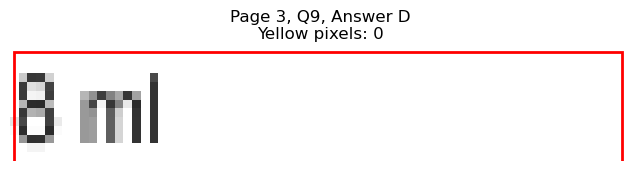

Page 3, Q9 - E: Detected box: x0=327.0, y0=644.9, x1=346.6, y1=657.5
Page 3, Q9, E: Yellow pixels: 0
Page 3, Q9, E: Total non-white pixels: 69
Page 3, Q9, E: Yellow percentage: 0.0%


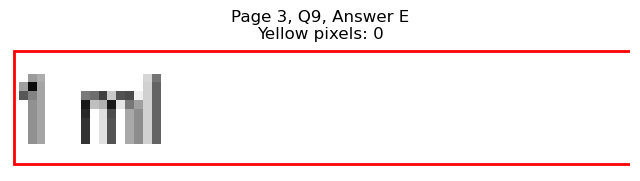


Page 3, Q9 - Selected Answer: B (based on yellow pixel count)




Page 3, Q10 - A: Detected box: x0=68.3, y0=695.4, x1=129.0, y1=708.0
Page 3, Q10, A: Yellow pixels: 0
Page 3, Q10, A: Total non-white pixels: 318
Page 3, Q10, A: Yellow percentage: 0.0%


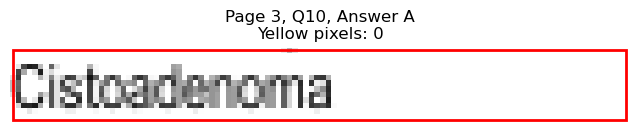

Page 3, Q10 - B: Detected box: x0=68.3, y0=708.0, x1=139.6, y1=720.6
Page 3, Q10, B: Yellow pixels: 0
Page 3, Q10, B: Total non-white pixels: 350
Page 3, Q10, B: Yellow percentage: 0.0%


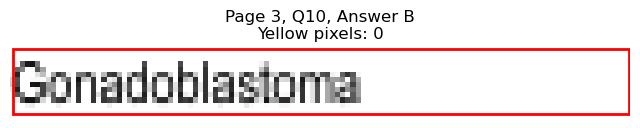

Page 3, Q10 - C: Detected box: x0=68.8, y0=720.6, x1=109.9, y1=733.2
Page 3, Q10, C: Yellow pixels: 0
Page 3, Q10, C: Total non-white pixels: 194
Page 3, Q10, C: Yellow percentage: 0.0%


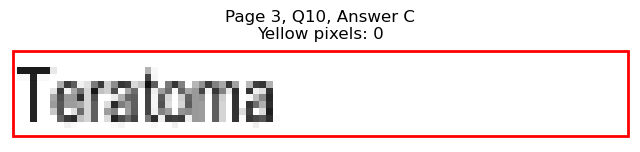

Page 3, Q10 - D: Detected box: x0=327.5, y0=695.4, x1=381.2, y1=708.0
Page 3, Q10, D: Yellow pixels: 1127
Page 3, Q10, D: Total non-white pixels: 1365
Page 3, Q10, D: Yellow percentage: 82.6%


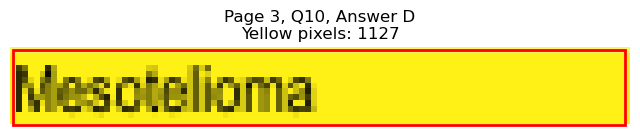

Page 3, Q10 - E: Detected box: x0=327.0, y0=708.0, x1=365.7, y1=720.6
Page 3, Q10, E: Yellow pixels: 89
Page 3, Q10, E: Total non-white pixels: 279
Page 3, Q10, E: Yellow percentage: 31.9%


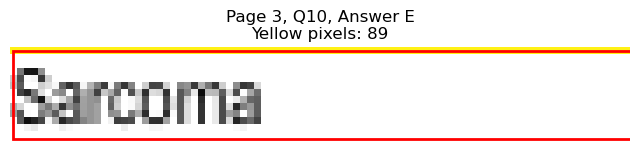


Page 3, Q10 - Selected Answer: D (based on yellow pixel count)





Page 4: Found 10 questions
Page 4, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=177.1, y1=114.7
Page 4, Q1, A: Yellow pixels: 0
Page 4, Q1, A: Total non-white pixels: 515
Page 4, Q1, A: Yellow percentage: 0.0%


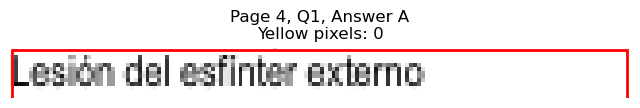

Page 4, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=206.2, y1=127.3
Page 4, Q1, B: Yellow pixels: 189
Page 4, Q1, B: Total non-white pixels: 860
Page 4, Q1, B: Yellow percentage: 22.0%


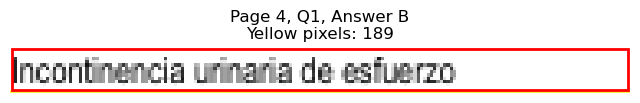

Page 4, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=158.5, y1=139.9
Page 4, Q1, C: Yellow pixels: 1437
Page 4, Q1, C: Total non-white pixels: 1833
Page 4, Q1, C: Yellow percentage: 78.4%


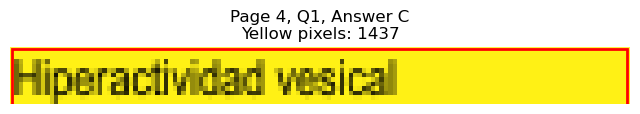

Page 4, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=387.8, y1=114.7
Page 4, Q1, D: Yellow pixels: 0
Page 4, Q1, D: Total non-white pixels: 307
Page 4, Q1, D: Yellow percentage: 0.0%


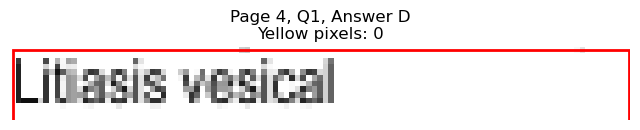

Page 4, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=397.7, y1=127.3
Page 4, Q1, E: Yellow pixels: 0
Page 4, Q1, E: Total non-white pixels: 366
Page 4, Q1, E: Yellow percentage: 0.0%


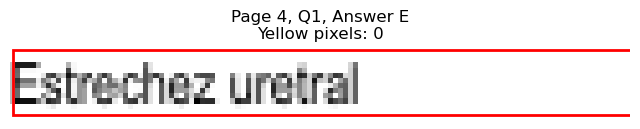


Page 4, Q1 - Selected Answer: C (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=119.9, y1=177.8
Page 4, Q2, A: Yellow pixels: 1145
Page 4, Q2, A: Total non-white pixels: 1326
Page 4, Q2, A: Yellow percentage: 86.3%


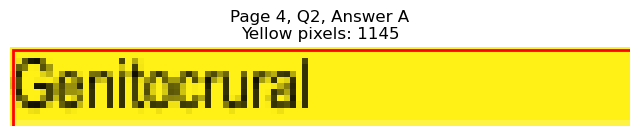

Page 4, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=134.1, y1=190.4
Page 4, Q2, B: Yellow pixels: 117
Page 4, Q2, B: Total non-white pixels: 435
Page 4, Q2, B: Yellow percentage: 26.9%


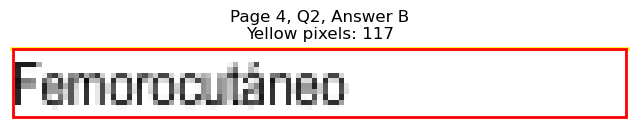

Page 4, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=113.9, y1=203.0
Page 4, Q2, C: Yellow pixels: 0
Page 4, Q2, C: Total non-white pixels: 205
Page 4, Q2, C: Yellow percentage: 0.0%


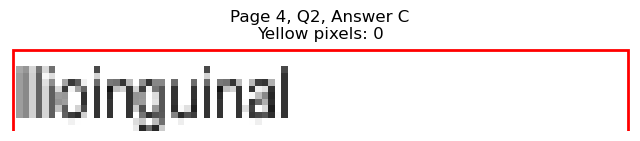

Page 4, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=380.2, y1=177.8
Page 4, Q2, D: Yellow pixels: 0
Page 4, Q2, D: Total non-white pixels: 300
Page 4, Q2, D: Yellow percentage: 0.0%


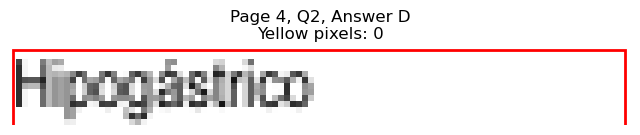

Page 4, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=396.8, y1=190.4
Page 4, Q2, E: Yellow pixels: 0
Page 4, Q2, E: Total non-white pixels: 394
Page 4, Q2, E: Yellow percentage: 0.0%


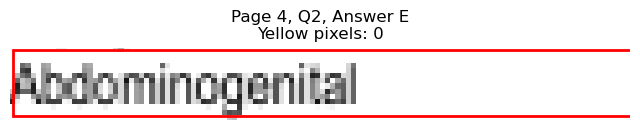


Page 4, Q2 - Selected Answer: A (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=229.0, y1=240.9
Page 4, Q3, A: Yellow pixels: 2177
Page 4, Q3, A: Total non-white pixels: 2756
Page 4, Q3, A: Yellow percentage: 79.0%


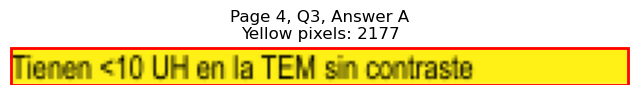

Page 4, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=225.0, y1=253.5
Page 4, Q3, B: Yellow pixels: 208
Page 4, Q3, B: Total non-white pixels: 939
Page 4, Q3, B: Yellow percentage: 22.2%


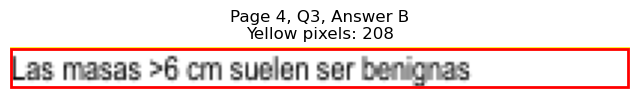

Page 4, Q3 - C: Detected box: x0=68.8, y0=253.5, x1=223.7, y1=266.1
Page 4, Q3, C: Yellow pixels: 0
Page 4, Q3, C: Total non-white pixels: 765
Page 4, Q3, C: Yellow percentage: 0.0%


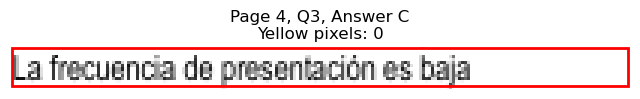

Page 4, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=475.1, y1=240.9
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 714
Page 4, Q3, D: Yellow percentage: 0.0%


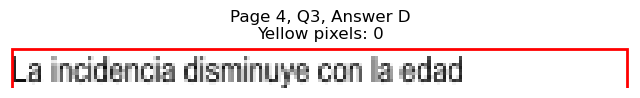

Page 4, Q3 - E: Detected box: x0=327.0, y0=240.9, x1=476.0, y1=253.5
Page 4, Q3, E: Yellow pixels: 0
Page 4, Q3, E: Total non-white pixels: 756
Page 4, Q3, E: Yellow percentage: 0.0%


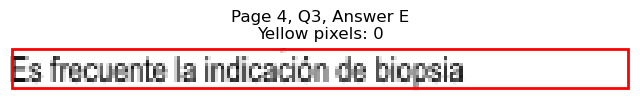


Page 4, Q3 - Selected Answer: A (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=140.1, y1=316.7
Page 4, Q4, A: Yellow pixels: 0
Page 4, Q4, A: Total non-white pixels: 378
Page 4, Q4, A: Yellow percentage: 0.0%


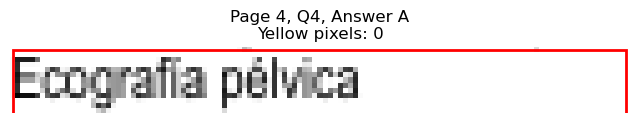

Page 4, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=157.1, y1=329.3
Page 4, Q4, B: Yellow pixels: 0
Page 4, Q4, B: Total non-white pixels: 435
Page 4, Q4, B: Yellow percentage: 0.0%


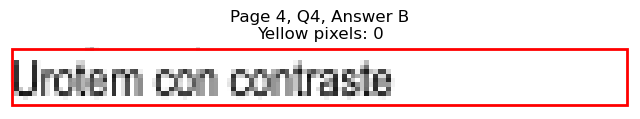

Page 4, Q4 - C: Detected box: x0=68.8, y0=329.2, x1=151.0, y1=341.9
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 422
Page 4, Q4, C: Yellow percentage: 0.0%


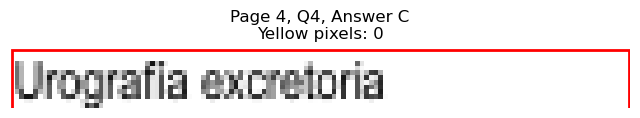

Page 4, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=464.5, y1=316.7
Page 4, Q4, D: Yellow pixels: 3
Page 4, Q4, D: Total non-white pixels: 895
Page 4, Q4, D: Yellow percentage: 0.3%


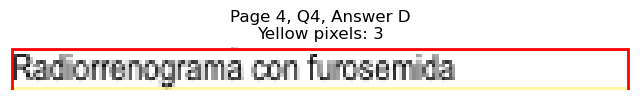

Page 4, Q4 - E: Detected box: x0=327.0, y0=316.6, x1=422.8, y1=329.3
Page 4, Q4, E: Yellow pixels: 1358
Page 4, Q4, E: Total non-white pixels: 2044
Page 4, Q4, E: Yellow percentage: 66.4%


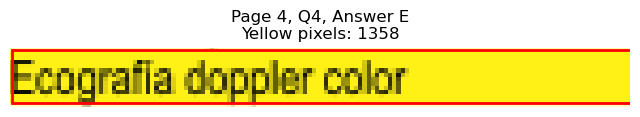


Page 4, Q4 - Selected Answer: E (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=115.5, y1=405.0
Page 4, Q5, A: Yellow pixels: 0
Page 4, Q5, A: Total non-white pixels: 357
Page 4, Q5, A: Yellow percentage: 0.0%


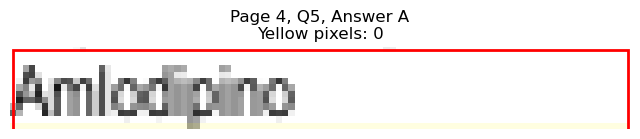

Page 4, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=113.9, y1=417.6
Page 4, Q5, B: Yellow pixels: 1083
Page 4, Q5, B: Total non-white pixels: 1344
Page 4, Q5, B: Yellow percentage: 80.6%


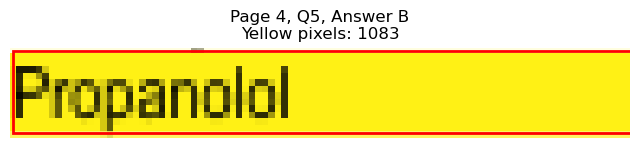

Page 4, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=108.4, y1=430.3
Page 4, Q5, C: Yellow pixels: 91
Page 4, Q5, C: Total non-white pixels: 300
Page 4, Q5, C: Yellow percentage: 30.3%


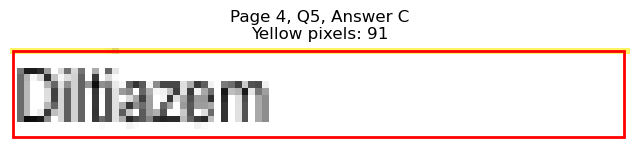

Page 4, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=366.2, y1=405.0
Page 4, Q5, D: Yellow pixels: 0
Page 4, Q5, D: Total non-white pixels: 213
Page 4, Q5, D: Yellow percentage: 0.0%


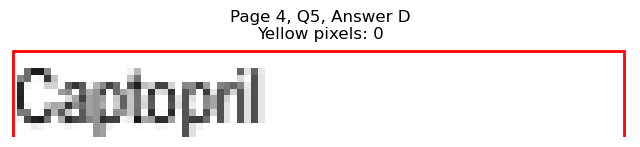

Page 4, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=364.7, y1=417.6
Page 4, Q5, E: Yellow pixels: 0
Page 4, Q5, E: Total non-white pixels: 195
Page 4, Q5, E: Yellow percentage: 0.0%


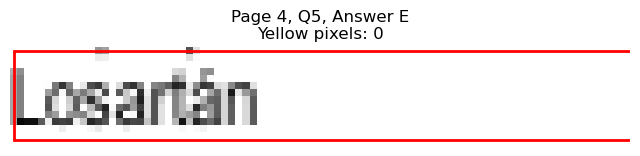


Page 4, Q5 - Selected Answer: B (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=143.1, y1=468.1
Page 4, Q6, A: Yellow pixels: 0
Page 4, Q6, A: Total non-white pixels: 350
Page 4, Q6, A: Yellow percentage: 0.0%


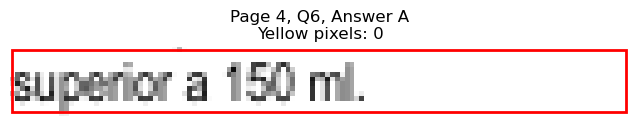

Page 4, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=138.0, y1=480.7
Page 4, Q6, B: Yellow pixels: 0
Page 4, Q6, B: Total non-white pixels: 318
Page 4, Q6, B: Yellow percentage: 0.0%


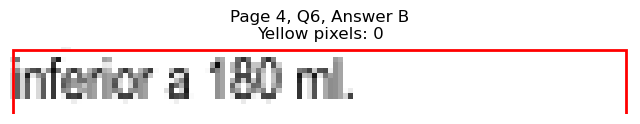

Page 4, Q6 - C: Detected box: x0=68.8, y0=480.8, x1=143.5, y1=493.4
Page 4, Q6, C: Yellow pixels: 0
Page 4, Q6, C: Total non-white pixels: 330
Page 4, Q6, C: Yellow percentage: 0.0%


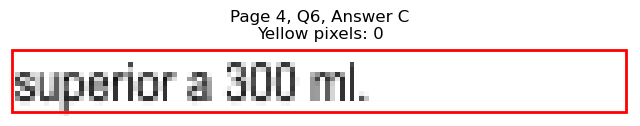

Page 4, Q6 - D: Detected box: x0=327.5, y0=455.5, x1=402.3, y1=468.1
Page 4, Q6, D: Yellow pixels: 126
Page 4, Q6, D: Total non-white pixels: 481
Page 4, Q6, D: Yellow percentage: 26.2%


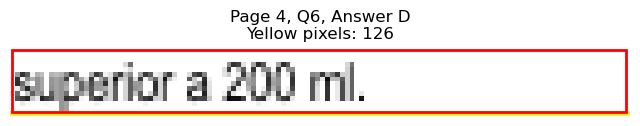

Page 4, Q6 - E: Detected box: x0=327.0, y0=468.1, x1=396.8, y1=480.7
Page 4, Q6, E: Yellow pixels: 1314
Page 4, Q6, E: Total non-white pixels: 1560
Page 4, Q6, E: Yellow percentage: 84.2%


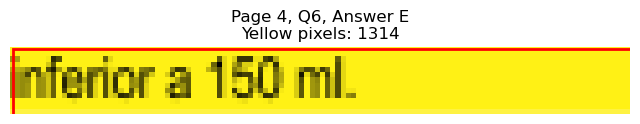


Page 4, Q6 - Selected Answer: E (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=68.3, y0=518.6, x1=136.0, y1=531.2
Page 4, Q7, A: Yellow pixels: 118
Page 4, Q7, A: Total non-white pixels: 432
Page 4, Q7, A: Yellow percentage: 27.3%


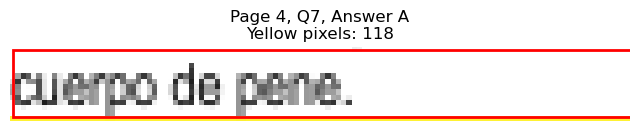

Page 4, Q7 - B: Detected box: x0=68.3, y0=531.2, x1=100.5, y1=543.8
Page 4, Q7, B: Yellow pixels: 958
Page 4, Q7, B: Total non-white pixels: 1079
Page 4, Q7, B: Yellow percentage: 88.8%


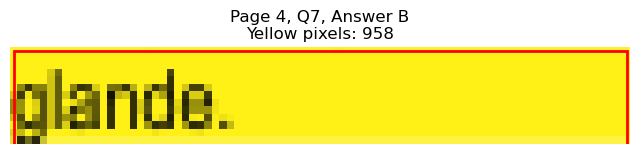

Page 4, Q7 - C: Detected box: x0=68.8, y0=543.8, x1=103.3, y1=556.4
Page 4, Q7, C: Yellow pixels: 82
Page 4, Q7, C: Total non-white pixels: 256
Page 4, Q7, C: Yellow percentage: 32.0%


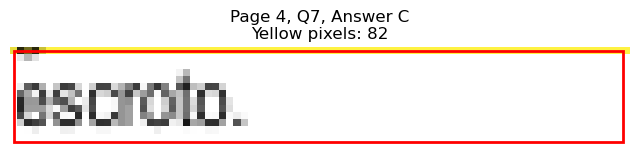

Page 4, Q7 - D: Detected box: x0=327.5, y0=518.6, x1=387.3, y1=531.2
Page 4, Q7, D: Yellow pixels: 0
Page 4, Q7, D: Total non-white pixels: 282
Page 4, Q7, D: Yellow percentage: 0.0%


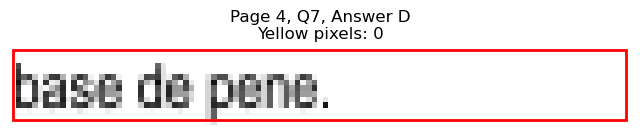

Page 4, Q7 - E: Detected box: x0=327.0, y0=531.2, x1=355.6, y1=543.8
Page 4, Q7, E: Yellow pixels: 0
Page 4, Q7, E: Total non-white pixels: 129
Page 4, Q7, E: Yellow percentage: 0.0%


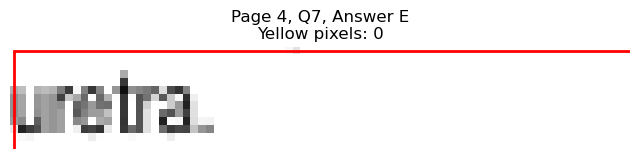


Page 4, Q7 - Selected Answer: B (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=68.3, y0=581.7, x1=82.3, y1=594.4
Page 4, Q8, A: Yellow pixels: 0
Page 4, Q8, A: Total non-white pixels: 57
Page 4, Q8, A: Yellow percentage: 0.0%


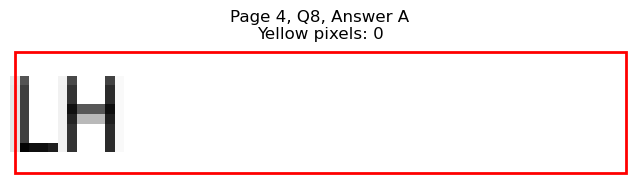

Page 4, Q8 - B: Detected box: x0=68.3, y0=594.3, x1=110.9, y1=607.0
Page 4, Q8, B: Yellow pixels: 0
Page 4, Q8, B: Total non-white pixels: 209
Page 4, Q8, B: Yellow percentage: 0.0%


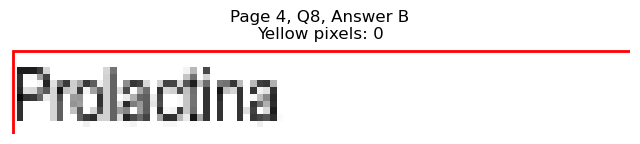

Page 4, Q8 - C: Detected box: x0=68.8, y0=606.9, x1=96.4, y1=619.6
Page 4, Q8, C: Yellow pixels: 0
Page 4, Q8, C: Total non-white pixels: 142
Page 4, Q8, C: Yellow percentage: 0.0%


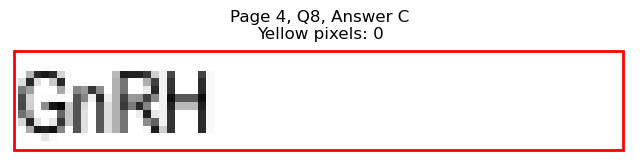

Page 4, Q8 - D: Detected box: x0=327.5, y0=581.7, x1=348.1, y1=594.4
Page 4, Q8, D: Yellow pixels: 786
Page 4, Q8, D: Total non-white pixels: 1008
Page 4, Q8, D: Yellow percentage: 78.0%


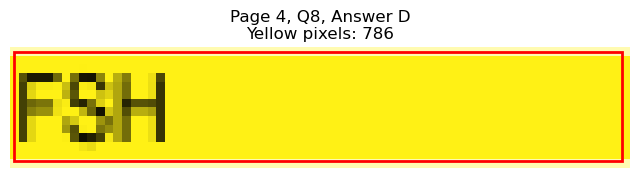

Page 4, Q8 - E: Detected box: x0=327.0, y0=594.3, x1=407.9, y1=607.0
Page 4, Q8, E: Yellow pixels: 0
Page 4, Q8, E: Total non-white pixels: 551
Page 4, Q8, E: Yellow percentage: 0.0%


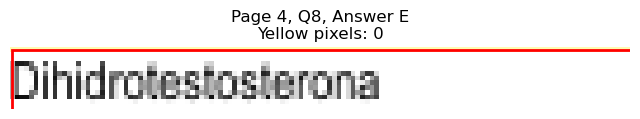


Page 4, Q8 - Selected Answer: D (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=68.3, y0=644.9, x1=116.4, y1=657.5
Page 4, Q9, A: Yellow pixels: 0
Page 4, Q9, A: Total non-white pixels: 227
Page 4, Q9, A: Yellow percentage: 0.0%


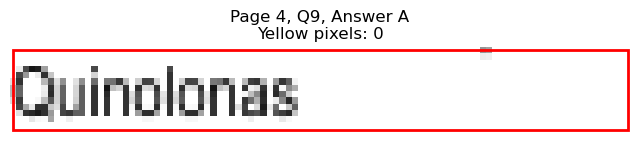

Page 4, Q9 - B: Detected box: x0=68.3, y0=657.5, x1=115.9, y1=670.1
Page 4, Q9, B: Yellow pixels: 0
Page 4, Q9, B: Total non-white pixels: 253
Page 4, Q9, B: Yellow percentage: 0.0%


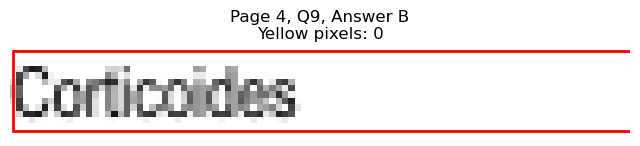

Page 4, Q9 - C: Detected box: x0=68.8, y0=670.1, x1=162.5, y1=682.7
Page 4, Q9, C: Yellow pixels: 0
Page 4, Q9, C: Total non-white pixels: 462
Page 4, Q9, C: Yellow percentage: 0.0%


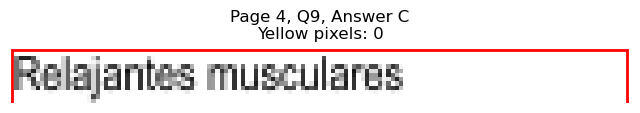

Page 4, Q9 - D: Detected box: x0=327.5, y0=644.9, x1=404.2, y1=657.5
Page 4, Q9, D: Yellow pixels: 128
Page 4, Q9, D: Total non-white pixels: 524
Page 4, Q9, D: Yellow percentage: 24.4%


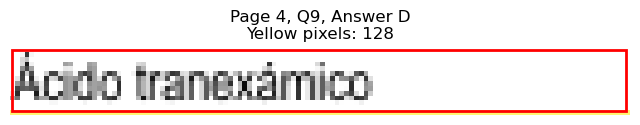

Page 4, Q9 - E: Detected box: x0=327.0, y0=657.5, x1=426.9, y1=670.1
Page 4, Q9, E: Yellow pixels: 1568
Page 4, Q9, E: Total non-white pixels: 2100
Page 4, Q9, E: Yellow percentage: 74.7%


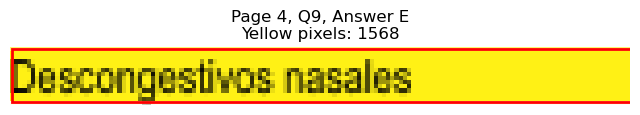


Page 4, Q9 - Selected Answer: E (based on yellow pixel count)




Page 4, Q10 - A: Detected box: x0=68.3, y0=733.2, x1=124.9, y1=745.8
Page 4, Q10, A: Yellow pixels: 1
Page 4, Q10, A: Total non-white pixels: 393
Page 4, Q10, A: Yellow percentage: 0.3%


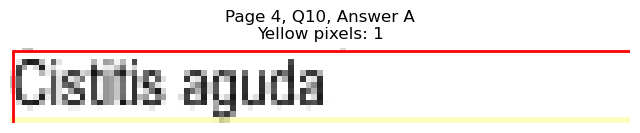

Page 4, Q10 - B: Detected box: x0=68.3, y0=745.8, x1=145.1, y1=758.4
Page 4, Q10, B: Yellow pixels: 1359
Page 4, Q10, B: Total non-white pixels: 1792
Page 4, Q10, B: Yellow percentage: 75.8%


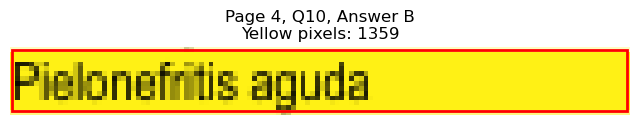

Page 4, Q10 - C: Detected box: x0=68.8, y0=758.5, x1=147.5, y1=771.2
Page 4, Q10, C: Yellow pixels: 128
Page 4, Q10, C: Total non-white pixels: 515
Page 4, Q10, C: Yellow percentage: 24.9%


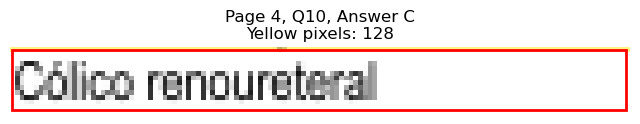

Page 4, Q10 - D: Detected box: x0=327.5, y0=733.2, x1=399.3, y1=745.8
Page 4, Q10, D: Yellow pixels: 0
Page 4, Q10, D: Total non-white pixels: 365
Page 4, Q10, D: Yellow percentage: 0.0%


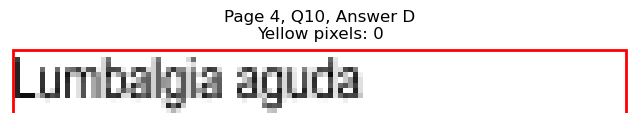

Page 4, Q10 - E: Detected box: x0=327.0, y0=745.8, x1=405.3, y1=758.4
Page 4, Q10, E: Yellow pixels: 0
Page 4, Q10, E: Total non-white pixels: 399
Page 4, Q10, E: Yellow percentage: 0.0%


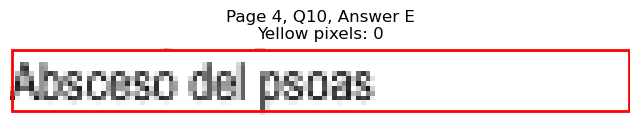


Page 4, Q10 - Selected Answer: B (based on yellow pixel count)





Page 5: Found 10 questions
Page 5, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=133.9, y1=102.1
Page 5, Q1, A: Yellow pixels: 116
Page 5, Q1, A: Total non-white pixels: 432
Page 5, Q1, A: Yellow percentage: 26.9%


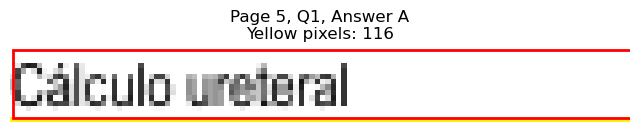

Page 5, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=137.1, y1=114.7
Page 5, Q1, B: Yellow pixels: 1276
Page 5, Q1, B: Total non-white pixels: 1560
Page 5, Q1, B: Yellow percentage: 81.8%


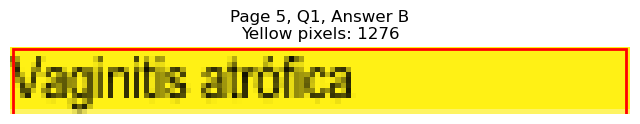

Page 5, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=112.9, y1=127.3
Page 5, Q1, C: Yellow pixels: 94
Page 5, Q1, C: Total non-white pixels: 300
Page 5, Q1, C: Yellow percentage: 31.3%


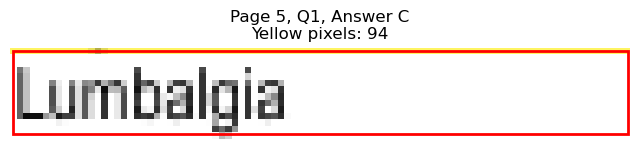

Page 5, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=361.1, y1=102.1
Page 5, Q1, D: Yellow pixels: 0
Page 5, Q1, D: Total non-white pixels: 169
Page 5, Q1, D: Yellow percentage: 0.0%


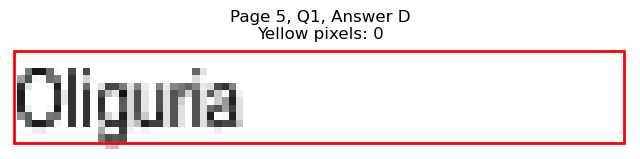

Page 5, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=359.1, y1=114.7
Page 5, Q1, E: Yellow pixels: 0
Page 5, Q1, E: Total non-white pixels: 150
Page 5, Q1, E: Yellow percentage: 0.0%


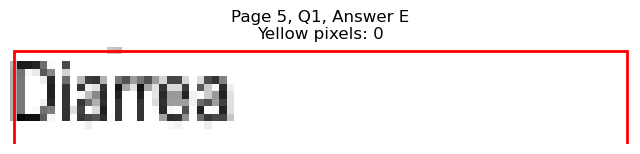


Page 5, Q1 - Selected Answer: B (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=159.6, y1=165.2
Page 5, Q2, A: Yellow pixels: 142
Page 5, Q2, A: Total non-white pixels: 626
Page 5, Q2, A: Yellow percentage: 22.7%


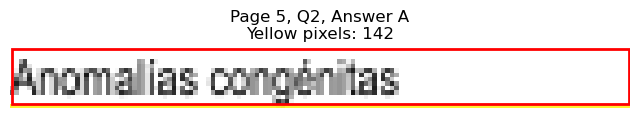

Page 5, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=120.0, y1=177.8
Page 5, Q2, B: Yellow pixels: 1133
Page 5, Q2, B: Total non-white pixels: 1339
Page 5, Q2, B: Yellow percentage: 84.6%


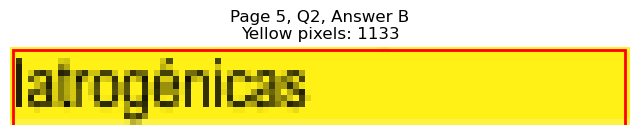

Page 5, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=122.4, y1=190.4
Page 5, Q2, C: Yellow pixels: 103
Page 5, Q2, C: Total non-white pixels: 407
Page 5, Q2, C: Yellow percentage: 25.3%


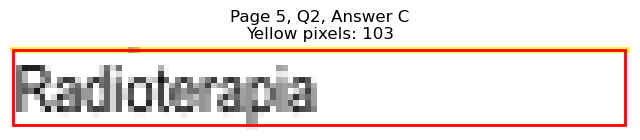

Page 5, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=427.4, y1=165.2
Page 5, Q2, D: Yellow pixels: 0
Page 5, Q2, D: Total non-white pixels: 520
Page 5, Q2, D: Yellow percentage: 0.0%


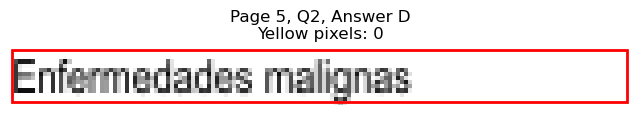

Page 5, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=421.4, y1=177.8
Page 5, Q2, E: Yellow pixels: 0
Page 5, Q2, E: Total non-white pixels: 474
Page 5, Q2, E: Yellow percentage: 0.0%


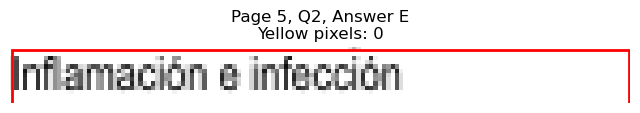


Page 5, Q2 - Selected Answer: B (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=128.5, y1=228.3
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 278
Page 5, Q3, A: Yellow percentage: 0.0%


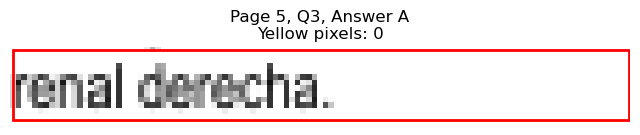

Page 5, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=124.0, y1=240.9
Page 5, Q3, B: Yellow pixels: 0
Page 5, Q3, B: Total non-white pixels: 265
Page 5, Q3, B: Yellow percentage: 0.0%


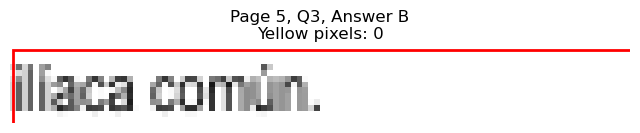

Page 5, Q3 - C: Detected box: x0=68.8, y0=240.9, x1=127.5, y1=253.5
Page 5, Q3, C: Yellow pixels: 0
Page 5, Q3, C: Total non-white pixels: 284
Page 5, Q3, C: Yellow percentage: 0.0%


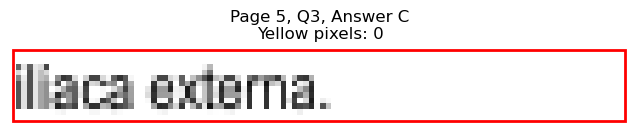

Page 5, Q3 - D: Detected box: x0=327.5, y0=215.7, x1=386.7, y1=228.3
Page 5, Q3, D: Yellow pixels: 110
Page 5, Q3, D: Total non-white pixels: 392
Page 5, Q3, D: Yellow percentage: 28.1%


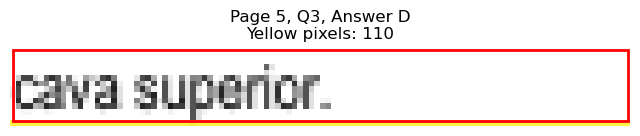

Page 5, Q3 - E: Detected box: x0=327.0, y0=228.3, x1=381.2, y1=240.9
Page 5, Q3, E: Yellow pixels: 1169
Page 5, Q3, E: Total non-white pixels: 1365
Page 5, Q3, E: Yellow percentage: 85.6%


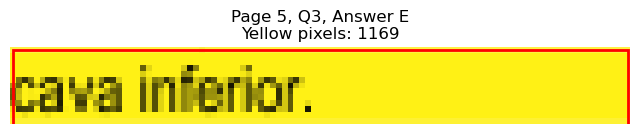


Page 5, Q3 - Selected Answer: E (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=68.3, y0=278.8, x1=104.4, y1=291.5
Page 5, Q4, A: Yellow pixels: 87
Page 5, Q4, A: Total non-white pixels: 282
Page 5, Q4, A: Yellow percentage: 30.9%


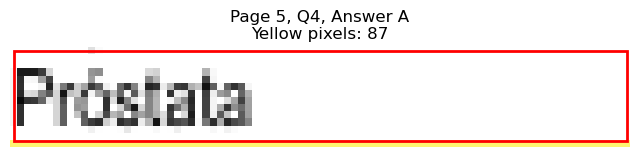

Page 5, Q4 - B: Detected box: x0=68.3, y0=291.4, x1=153.0, y1=304.1
Page 5, Q4, B: Yellow pixels: 1412
Page 5, Q4, B: Total non-white pixels: 1904
Page 5, Q4, B: Yellow percentage: 74.2%


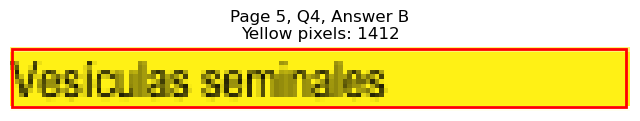

Page 5, Q4 - C: Detected box: x0=68.8, y0=304.0, x1=92.4, y1=316.7
Page 5, Q4, C: Yellow pixels: 0
Page 5, Q4, C: Total non-white pixels: 188
Page 5, Q4, C: Yellow percentage: 0.0%


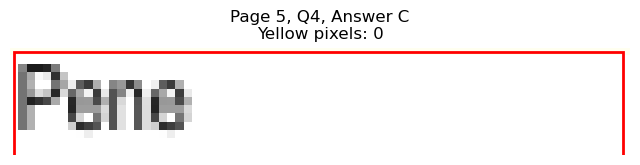

Page 5, Q4 - D: Detected box: x0=327.5, y0=278.8, x1=360.7, y1=291.5
Page 5, Q4, D: Yellow pixels: 0
Page 5, Q4, D: Total non-white pixels: 158
Page 5, Q4, D: Yellow percentage: 0.0%


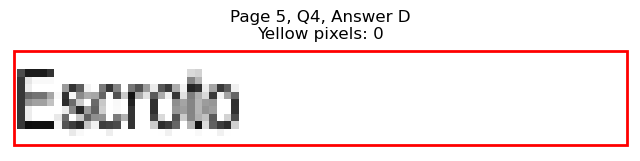

Page 5, Q4 - E: Detected box: x0=327.0, y0=291.4, x1=354.7, y1=304.1
Page 5, Q4, E: Yellow pixels: 0
Page 5, Q4, E: Total non-white pixels: 159
Page 5, Q4, E: Yellow percentage: 0.0%


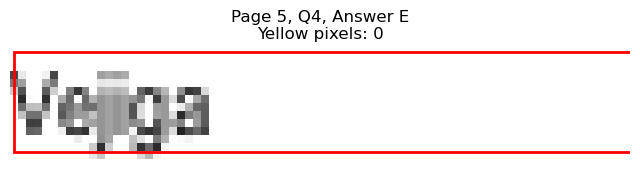


Page 5, Q4 - Selected Answer: B (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=68.3, y0=341.9, x1=241.8, y1=354.6
Page 5, Q5, A: Yellow pixels: 0
Page 5, Q5, A: Total non-white pixels: 886
Page 5, Q5, A: Yellow percentage: 0.0%


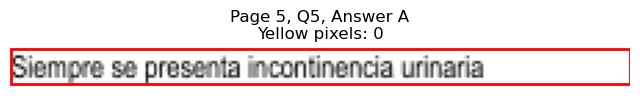

Page 5, Q5 - B: Detected box: x0=68.3, y0=354.5, x1=215.3, y1=367.2
Page 5, Q5, B: Yellow pixels: 198
Page 5, Q5, B: Total non-white pixels: 936
Page 5, Q5, B: Yellow percentage: 21.2%


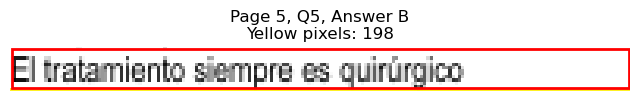

Page 5, Q5 - C: Detected box: x0=68.8, y0=367.1, x1=213.3, y1=379.8
Page 5, Q5, C: Yellow pixels: 2019
Page 5, Q5, C: Total non-white pixels: 2548
Page 5, Q5, C: Yellow percentage: 79.2%


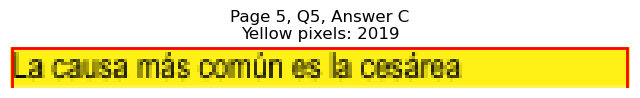

Page 5, Q5 - D: Detected box: x0=327.5, y0=341.9, x1=516.2, y1=354.6
Page 5, Q5, D: Yellow pixels: 0
Page 5, Q5, D: Total non-white pixels: 919
Page 5, Q5, D: Yellow percentage: 0.0%


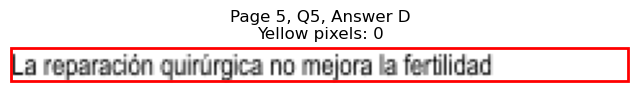

Page 5, Q5 - E: Detected box: x0=327.0, y0=354.5, x1=452.0, y1=367.2
Page 5, Q5, E: Yellow pixels: 0
Page 5, Q5, E: Total non-white pixels: 659
Page 5, Q5, E: Yellow percentage: 0.0%


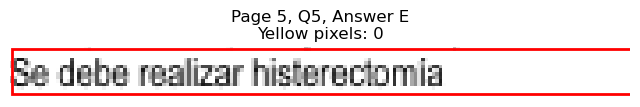


Page 5, Q5 - Selected Answer: C (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=68.3, y0=404.9, x1=109.0, y1=417.6
Page 5, Q6, A: Yellow pixels: 1013
Page 5, Q6, A: Total non-white pixels: 1274
Page 5, Q6, A: Yellow percentage: 79.5%


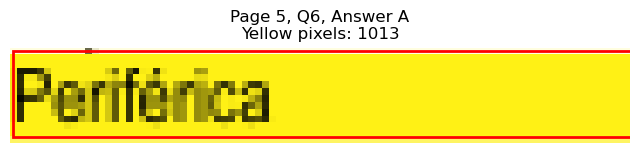

Page 5, Q6 - B: Detected box: x0=68.3, y0=417.6, x1=99.9, y1=430.3
Page 5, Q6, B: Yellow pixels: 82
Page 5, Q6, B: Total non-white pixels: 236
Page 5, Q6, B: Yellow percentage: 34.7%


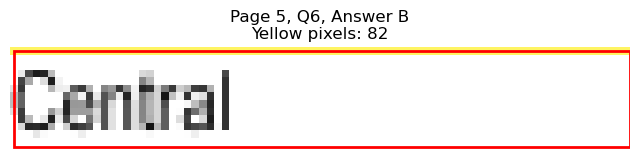

Page 5, Q6 - C: Detected box: x0=68.8, y0=430.2, x1=102.9, y1=442.9
Page 5, Q6, C: Yellow pixels: 0
Page 5, Q6, C: Total non-white pixels: 167
Page 5, Q6, C: Yellow percentage: 0.0%


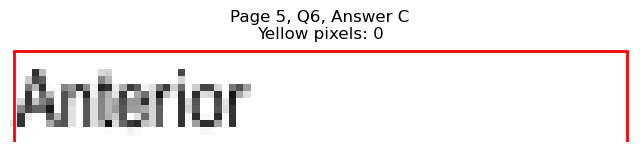

Page 5, Q6 - D: Detected box: x0=327.5, y0=404.9, x1=355.1, y1=417.6
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 132
Page 5, Q6, D: Yellow percentage: 0.0%


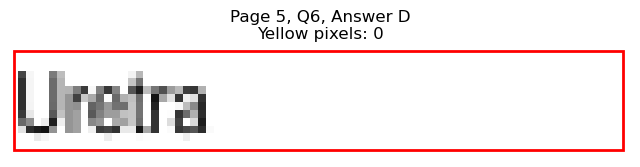

Page 5, Q6 - E: Detected box: x0=327.0, y0=417.6, x1=371.2, y1=430.3
Page 5, Q6, E: Yellow pixels: 0
Page 5, Q6, E: Total non-white pixels: 215
Page 5, Q6, E: Yellow percentage: 0.0%


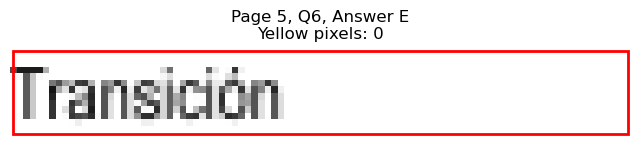


Page 5, Q6 - Selected Answer: A (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=68.3, y0=493.4, x1=144.5, y1=506.0
Page 5, Q7, A: Yellow pixels: 0
Page 5, Q7, A: Total non-white pixels: 372
Page 5, Q7, A: Yellow percentage: 0.0%


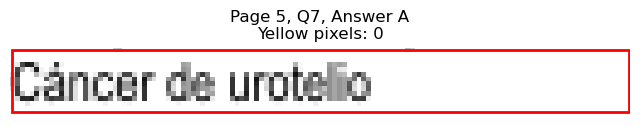

Page 5, Q7 - B: Detected box: x0=68.3, y0=506.0, x1=125.4, y1=518.6
Page 5, Q7, B: Yellow pixels: 0
Page 5, Q7, B: Total non-white pixels: 292
Page 5, Q7, B: Yellow percentage: 0.0%


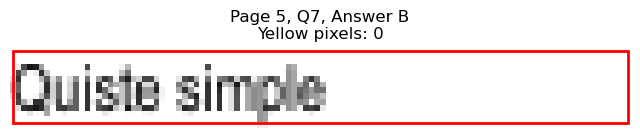

Page 5, Q7 - C: Detected box: x0=68.8, y0=518.6, x1=135.5, y1=531.2
Page 5, Q7, C: Yellow pixels: 0
Page 5, Q7, C: Total non-white pixels: 327
Page 5, Q7, C: Yellow percentage: 0.0%


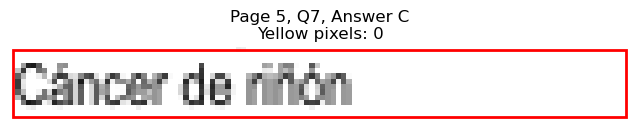

Page 5, Q7 - D: Detected box: x0=327.5, y0=493.4, x1=416.8, y1=506.0
Page 5, Q7, D: Yellow pixels: 1455
Page 5, Q7, D: Total non-white pixels: 1825
Page 5, Q7, D: Yellow percentage: 79.7%


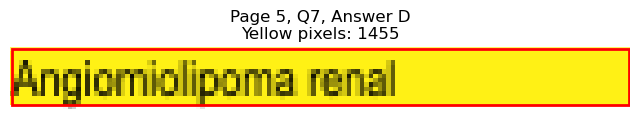

Page 5, Q7 - E: Detected box: x0=327.0, y0=506.0, x1=396.8, y1=518.6
Page 5, Q7, E: Yellow pixels: 114
Page 5, Q7, E: Total non-white pixels: 509
Page 5, Q7, E: Yellow percentage: 22.4%


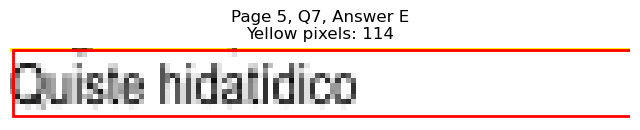


Page 5, Q7 - Selected Answer: D (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=68.3, y0=556.5, x1=161.1, y1=569.2
Page 5, Q8, A: Yellow pixels: 144
Page 5, Q8, A: Total non-white pixels: 551
Page 5, Q8, A: Yellow percentage: 26.1%


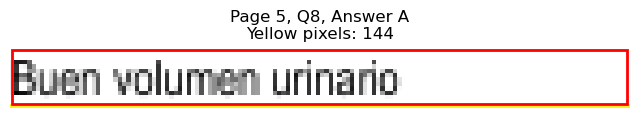

Page 5, Q8 - B: Detected box: x0=68.3, y0=569.1, x1=179.7, y1=581.8
Page 5, Q8, B: Yellow pixels: 1670
Page 5, Q8, B: Total non-white pixels: 2106
Page 5, Q8, B: Yellow percentage: 79.3%


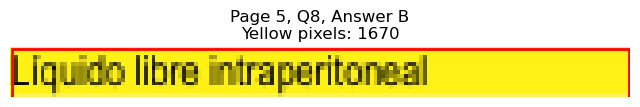

Page 5, Q8 - C: Detected box: x0=68.8, y0=581.7, x1=115.5, y1=594.4
Page 5, Q8, C: Yellow pixels: 98
Page 5, Q8, C: Total non-white pixels: 329
Page 5, Q8, C: Yellow percentage: 29.8%


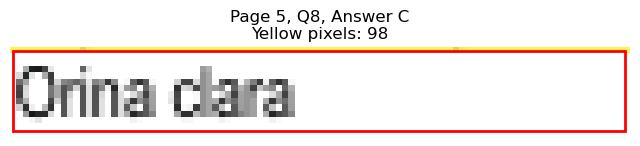

Page 5, Q8 - D: Detected box: x0=327.5, y0=556.5, x1=415.7, y1=569.2
Page 5, Q8, D: Yellow pixels: 0
Page 5, Q8, D: Total non-white pixels: 468
Page 5, Q8, D: Yellow percentage: 0.0%


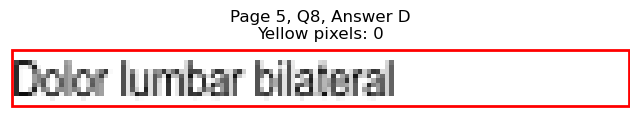

Page 5, Q8 - E: Detected box: x0=327.0, y0=569.1, x1=416.3, y1=581.8
Page 5, Q8, E: Yellow pixels: 0
Page 5, Q8, E: Total non-white pixels: 454
Page 5, Q8, E: Yellow percentage: 0.0%


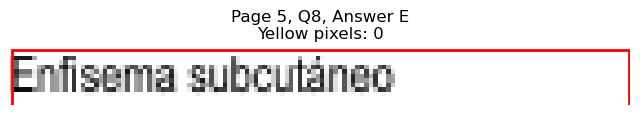


Page 5, Q8 - Selected Answer: B (based on yellow pixel count)




Page 5, Q9 - A: Detected box: x0=68.3, y0=619.6, x1=139.5, y1=632.3
Page 5, Q9, A: Yellow pixels: 1166
Page 5, Q9, A: Total non-white pixels: 1708
Page 5, Q9, A: Yellow percentage: 68.3%


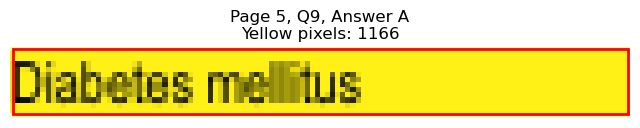

Page 5, Q9 - B: Detected box: x0=68.3, y0=632.2, x1=107.4, y1=644.9
Page 5, Q9, B: Yellow pixels: 0
Page 5, Q9, B: Total non-white pixels: 276
Page 5, Q9, B: Yellow percentage: 0.0%


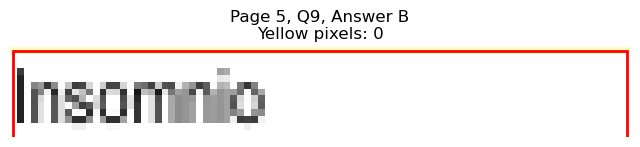

Page 5, Q9 - C: Detected box: x0=68.8, y0=644.9, x1=147.5, y1=657.5
Page 5, Q9, C: Yellow pixels: 0
Page 5, Q9, C: Total non-white pixels: 416
Page 5, Q9, C: Yellow percentage: 0.0%


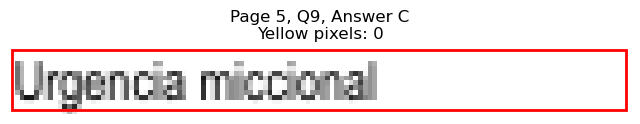

Page 5, Q9 - D: Detected box: x0=327.5, y0=619.6, x1=437.3, y1=632.3
Page 5, Q9, D: Yellow pixels: 0
Page 5, Q9, D: Total non-white pixels: 586
Page 5, Q9, D: Yellow percentage: 0.0%


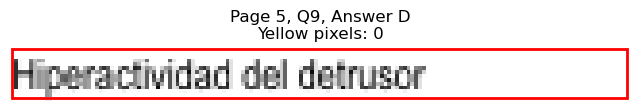

Page 5, Q9 - E: Detected box: x0=327.0, y0=632.2, x1=455.5, y1=644.9
Page 5, Q9, E: Yellow pixels: 0
Page 5, Q9, E: Total non-white pixels: 623
Page 5, Q9, E: Yellow percentage: 0.0%


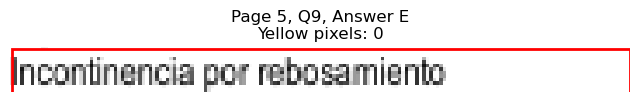


Page 5, Q9 - Selected Answer: A (based on yellow pixel count)




Page 5, Q10 - A: Detected box: x0=68.3, y0=682.7, x1=136.0, y1=695.3
Page 5, Q10, A: Yellow pixels: 0
Page 5, Q10, A: Total non-white pixels: 333
Page 5, Q10, A: Yellow percentage: 0.0%


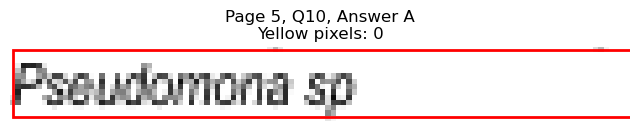

Page 5, Q10 - B: Detected box: x0=68.3, y0=695.4, x1=137.5, y1=708.0
Page 5, Q10, B: Yellow pixels: 1291
Page 5, Q10, B: Total non-white pixels: 1560
Page 5, Q10, B: Yellow percentage: 82.8%


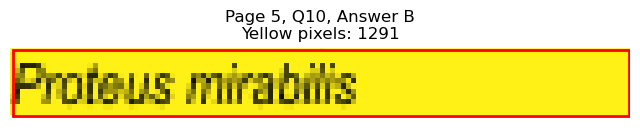

Page 5, Q10 - C: Detected box: x0=68.8, y0=708.0, x1=155.5, y1=720.6
Page 5, Q10, C: Yellow pixels: 138
Page 5, Q10, C: Total non-white pixels: 572
Page 5, Q10, C: Yellow percentage: 24.1%


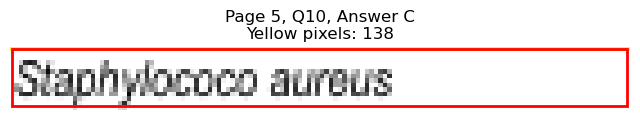

Page 5, Q10 - D: Detected box: x0=327.5, y0=682.7, x1=390.3, y1=695.3
Page 5, Q10, D: Yellow pixels: 0
Page 5, Q10, D: Total non-white pixels: 315
Page 5, Q10, D: Yellow percentage: 0.0%


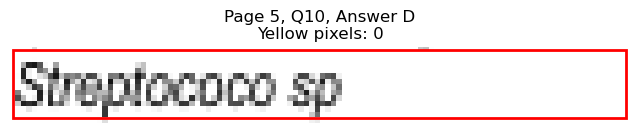

Page 5, Q10 - E: Detected box: x0=327.0, y0=695.4, x1=418.9, y1=708.0
Page 5, Q10, E: Yellow pixels: 0
Page 5, Q10, E: Total non-white pixels: 492
Page 5, Q10, E: Yellow percentage: 0.0%


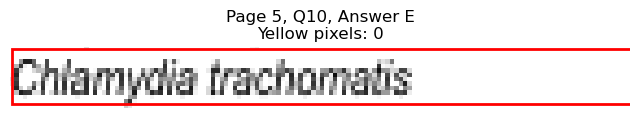


Page 5, Q10 - Selected Answer: B (based on yellow pixel count)





Page 6: Found 9 questions
Page 6, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=221.2, y1=102.1
Page 6, Q1, A: Yellow pixels: 2071
Page 6, Q1, A: Total non-white pixels: 2856
Page 6, Q1, A: Yellow percentage: 72.5%


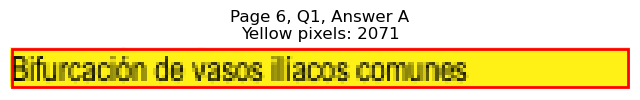

Page 6, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=212.2, y1=114.7
Page 6, Q1, B: Yellow pixels: 0
Page 6, Q1, B: Total non-white pixels: 927
Page 6, Q1, B: Yellow percentage: 0.0%


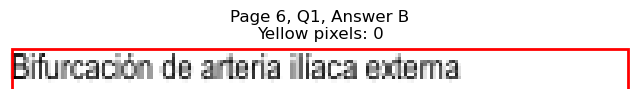

Page 6, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=157.1, y1=127.3
Page 6, Q1, C: Yellow pixels: 0
Page 6, Q1, C: Total non-white pixels: 450
Page 6, Q1, C: Yellow percentage: 0.0%


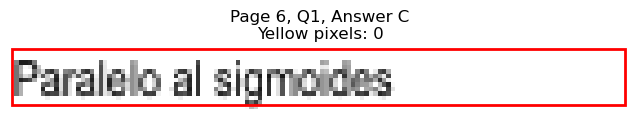

Page 6, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=446.0, y1=102.1
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 572
Page 6, Q1, D: Yellow percentage: 0.0%


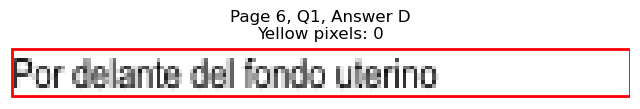

Page 6, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=412.9, y1=114.7
Page 6, Q1, E: Yellow pixels: 0
Page 6, Q1, E: Total non-white pixels: 418
Page 6, Q1, E: Yellow percentage: 0.0%


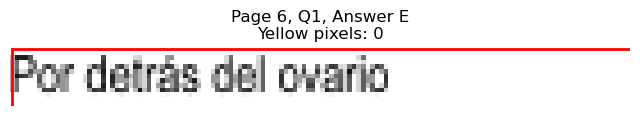


Page 6, Q1 - Selected Answer: A (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=140.5, y1=165.2
Page 6, Q2, A: Yellow pixels: 0
Page 6, Q2, A: Total non-white pixels: 368
Page 6, Q2, A: Yellow percentage: 0.0%


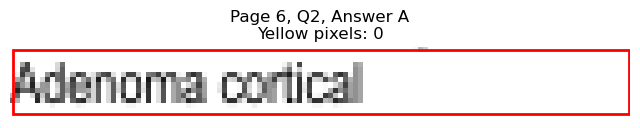

Page 6, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=159.0, y1=177.8
Page 6, Q2, B: Yellow pixels: 0
Page 6, Q2, B: Total non-white pixels: 601
Page 6, Q2, B: Yellow percentage: 0.0%


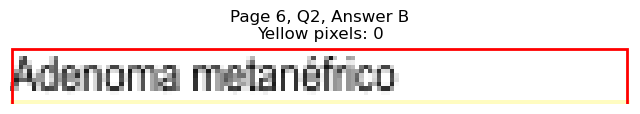

Page 6, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=119.4, y1=190.4
Page 6, Q2, C: Yellow pixels: 1029
Page 6, Q2, C: Total non-white pixels: 1428
Page 6, Q2, C: Yellow percentage: 72.1%


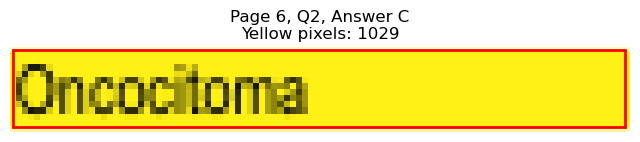

Page 6, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=394.3, y1=165.2
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 341
Page 6, Q2, D: Yellow percentage: 0.0%


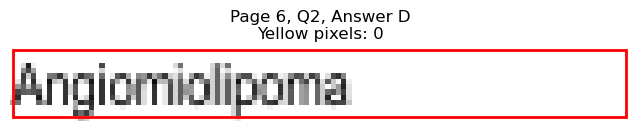

Page 6, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=397.7, y1=177.8
Page 6, Q2, E: Yellow pixels: 0
Page 6, Q2, E: Total non-white pixels: 362
Page 6, Q2, E: Yellow percentage: 0.0%


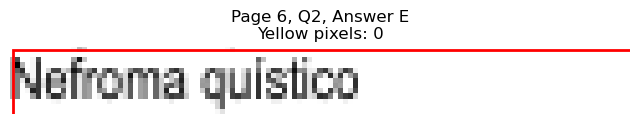


Page 6, Q2 - Selected Answer: C (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=88.3, y1=228.3
Page 6, Q3, A: Yellow pixels: 71
Page 6, Q3, A: Total non-white pixels: 175
Page 6, Q3, A: Yellow percentage: 40.6%


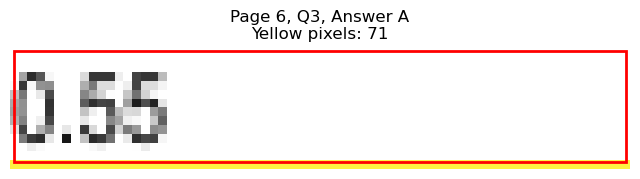

Page 6, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=88.3, y1=240.9
Page 6, Q3, B: Yellow pixels: 856
Page 6, Q3, B: Total non-white pixels: 923
Page 6, Q3, B: Yellow percentage: 92.7%


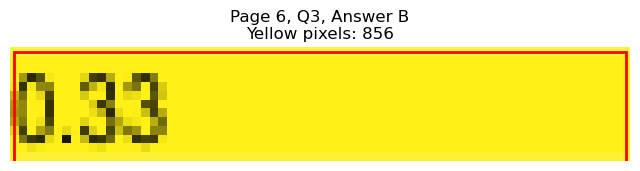

Page 6, Q3 - C: Detected box: x0=68.8, y0=240.9, x1=88.8, y1=253.5
Page 6, Q3, C: Yellow pixels: 71
Page 6, Q3, C: Total non-white pixels: 162
Page 6, Q3, C: Yellow percentage: 43.8%


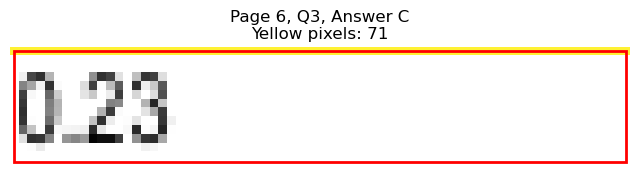

Page 6, Q3 - D: Detected box: x0=327.5, y0=215.7, x1=347.6, y1=228.3
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 98
Page 6, Q3, D: Yellow percentage: 0.0%


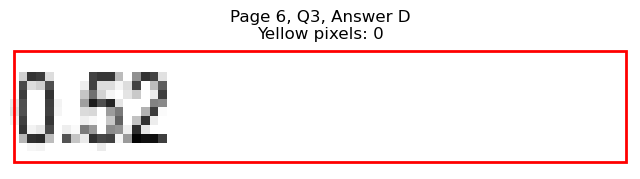

Page 6, Q3 - E: Detected box: x0=327.0, y0=228.3, x1=347.1, y1=240.9
Page 6, Q3, E: Yellow pixels: 0
Page 6, Q3, E: Total non-white pixels: 98
Page 6, Q3, E: Yellow percentage: 0.0%


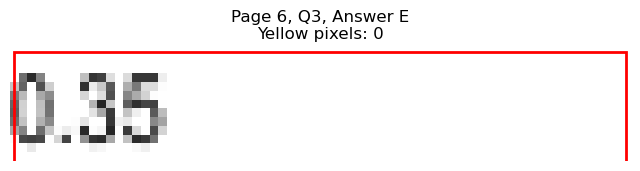


Page 6, Q3 - Selected Answer: B (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=68.3, y0=278.8, x1=179.7, y1=291.5
Page 6, Q4, A: Yellow pixels: 0
Page 6, Q4, A: Total non-white pixels: 565
Page 6, Q4, A: Yellow percentage: 0.0%


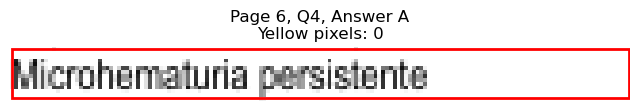

Page 6, Q4 - B: Detected box: x0=68.3, y0=291.4, x1=258.4, y1=304.1
Page 6, Q4, B: Yellow pixels: 0
Page 6, Q4, B: Total non-white pixels: 951
Page 6, Q4, B: Yellow percentage: 0.0%


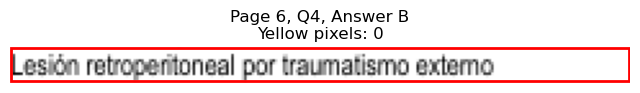

Page 6, Q4 - C: Detected box: x0=68.8, y0=304.0, x1=194.7, y1=316.7
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 623
Page 6, Q4, C: Yellow percentage: 0.0%


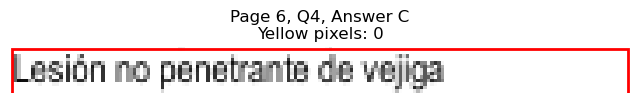

Page 6, Q4 - D: Detected box: x0=327.5, y0=278.8, x1=492.6, y1=291.5
Page 6, Q4, D: Yellow pixels: 2106
Page 6, Q4, D: Total non-white pixels: 2996
Page 6, Q4, D: Yellow percentage: 70.3%


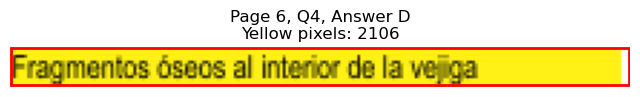

Page 6, Q4 - E: Detected box: x0=327.0, y0=291.4, x1=508.7, y1=304.1
Page 6, Q4, E: Yellow pixels: 210
Page 6, Q4, E: Total non-white pixels: 1087
Page 6, Q4, E: Yellow percentage: 19.3%


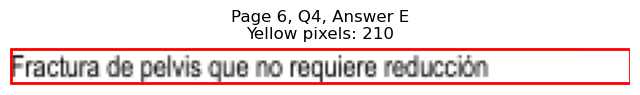


Page 6, Q4 - Selected Answer: D (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=68.3, y0=367.1, x1=98.9, y1=379.8
Page 6, Q5, A: Yellow pixels: 0
Page 6, Q5, A: Total non-white pixels: 179
Page 6, Q5, A: Yellow percentage: 0.0%


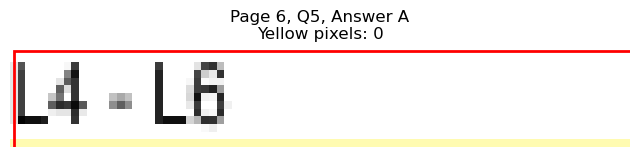

Page 6, Q5 - B: Detected box: x0=68.3, y0=379.7, x1=100.9, y1=392.4
Page 6, Q5, B: Yellow pixels: 895
Page 6, Q5, B: Total non-white pixels: 1162
Page 6, Q5, B: Yellow percentage: 77.0%


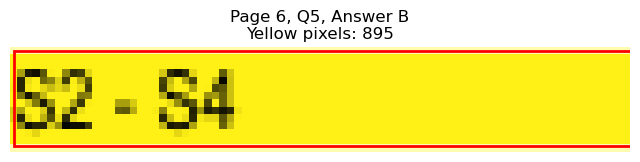

Page 6, Q5 - C: Detected box: x0=68.8, y0=392.3, x1=100.3, y1=405.0
Page 6, Q5, C: Yellow pixels: 0
Page 6, Q5, C: Total non-white pixels: 198
Page 6, Q5, C: Yellow percentage: 0.0%


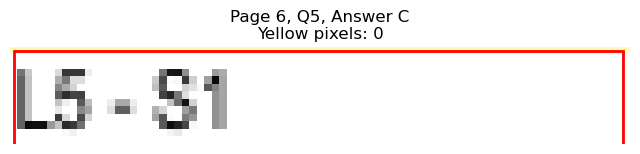

Page 6, Q5 - D: Detected box: x0=327.5, y0=367.1, x1=368.7, y1=379.8
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 177
Page 6, Q5, D: Yellow percentage: 0.0%


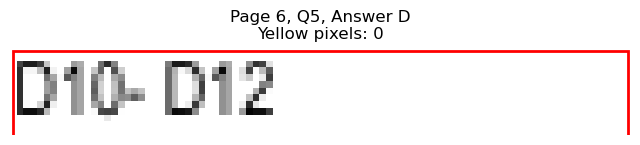

Page 6, Q5 - E: Detected box: x0=327.0, y0=379.7, x1=364.1, y1=392.4
Page 6, Q5, E: Yellow pixels: 0
Page 6, Q5, E: Total non-white pixels: 113
Page 6, Q5, E: Yellow percentage: 0.0%


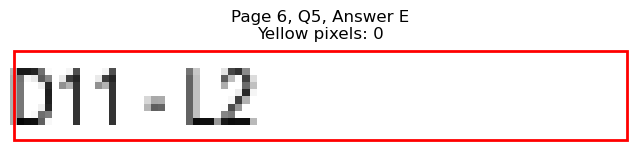


Page 6, Q5 - Selected Answer: B (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=68.3, y0=430.2, x1=136.5, y1=442.9
Page 6, Q6, A: Yellow pixels: 0
Page 6, Q6, A: Total non-white pixels: 342
Page 6, Q6, A: Yellow percentage: 0.0%


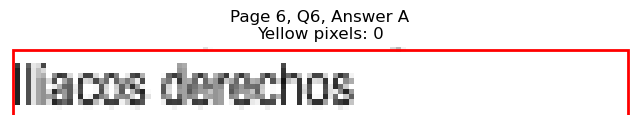

Page 6, Q6 - B: Detected box: x0=68.3, y0=442.8, x1=121.5, y1=455.5
Page 6, Q6, B: Yellow pixels: 104
Page 6, Q6, B: Total non-white pixels: 384
Page 6, Q6, B: Yellow percentage: 27.1%


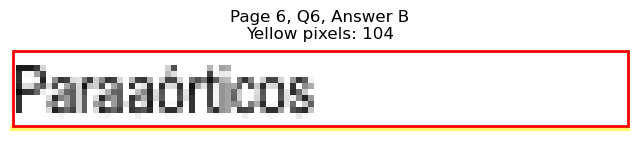

Page 6, Q6 - C: Detected box: x0=68.8, y0=455.5, x1=140.1, y1=468.1
Page 6, Q6, C: Yellow pixels: 1307
Page 6, Q6, C: Total non-white pixels: 1722
Page 6, Q6, C: Yellow percentage: 75.9%


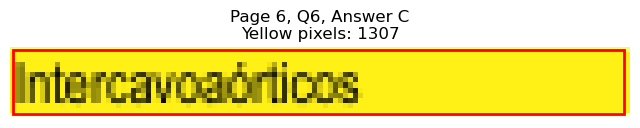

Page 6, Q6 - D: Detected box: x0=327.5, y0=430.2, x1=409.7, y1=442.9
Page 6, Q6, D: Yellow pixels: 0
Page 6, Q6, D: Total non-white pixels: 390
Page 6, Q6, D: Yellow percentage: 0.0%


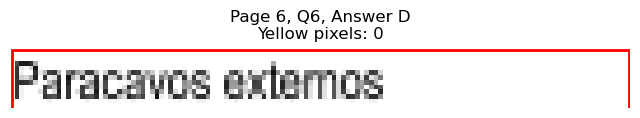

Page 6, Q6 - E: Detected box: x0=327.0, y0=442.8, x1=401.3, y1=455.5
Page 6, Q6, E: Yellow pixels: 0
Page 6, Q6, E: Total non-white pixels: 381
Page 6, Q6, E: Yellow percentage: 0.0%


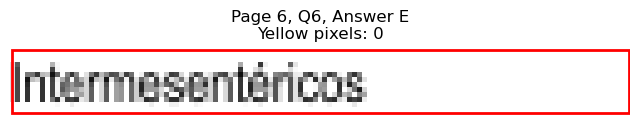


Page 6, Q6 - Selected Answer: C (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=68.3, y0=506.0, x1=116.4, y1=518.6
Page 6, Q7, A: Yellow pixels: 0
Page 6, Q7, A: Total non-white pixels: 265
Page 6, Q7, A: Yellow percentage: 0.0%


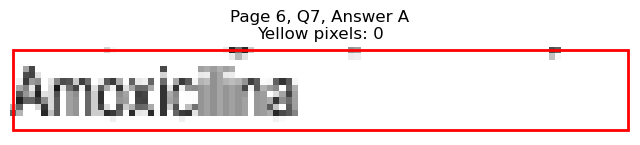

Page 6, Q7 - B: Detected box: x0=68.3, y0=518.6, x1=123.5, y1=531.2
Page 6, Q7, B: Yellow pixels: 0
Page 6, Q7, B: Total non-white pixels: 280
Page 6, Q7, B: Yellow percentage: 0.0%


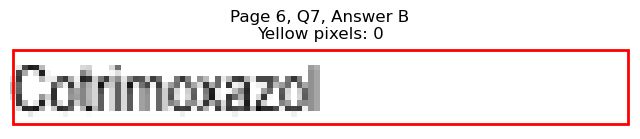

Page 6, Q7 - C: Detected box: x0=68.8, y0=531.2, x1=114.9, y1=543.8
Page 6, Q7, C: Yellow pixels: 0
Page 6, Q7, C: Total non-white pixels: 258
Page 6, Q7, C: Yellow percentage: 0.0%


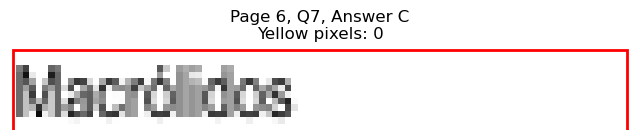

Page 6, Q7 - D: Detected box: x0=327.5, y0=506.0, x1=399.3, y1=518.6
Page 6, Q7, D: Yellow pixels: 1295
Page 6, Q7, D: Total non-white pixels: 1722
Page 6, Q7, D: Yellow percentage: 75.2%


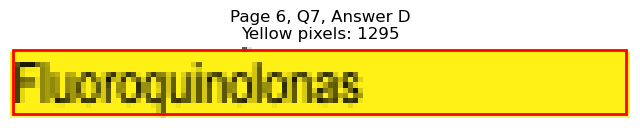

Page 6, Q7 - E: Detected box: x0=327.0, y0=518.6, x1=402.9, y1=531.2
Page 6, Q7, E: Yellow pixels: 126
Page 6, Q7, E: Total non-white pixels: 769
Page 6, Q7, E: Yellow percentage: 16.4%


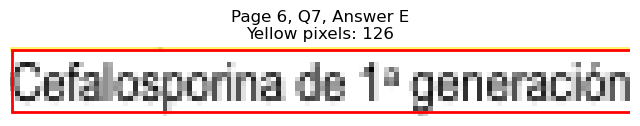


Page 6, Q7 - Selected Answer: D (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=150.5, y1=619.6
Page 6, Q8, A: Yellow pixels: 1421
Page 6, Q8, A: Total non-white pixels: 1862
Page 6, Q8, A: Yellow percentage: 76.3%


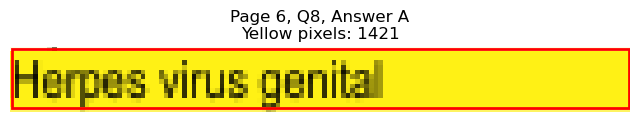

Page 6, Q8 - B: Detected box: x0=68.3, y0=619.6, x1=168.1, y1=632.3
Page 6, Q8, B: Yellow pixels: 149
Page 6, Q8, B: Total non-white pixels: 655
Page 6, Q8, B: Yellow percentage: 22.7%


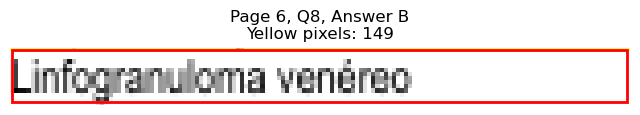

Page 6, Q8 - C: Detected box: x0=68.8, y0=632.2, x1=127.9, y1=644.9
Page 6, Q8, C: Yellow pixels: 0
Page 6, Q8, C: Total non-white pixels: 306
Page 6, Q8, C: Yellow percentage: 0.0%


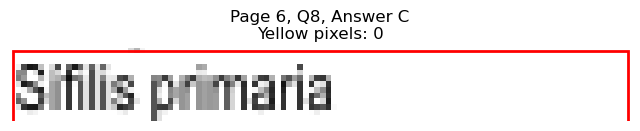

Page 6, Q8 - D: Detected box: x0=327.5, y0=606.9, x1=420.8, y1=619.6
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 469
Page 6, Q8, D: Yellow percentage: 0.0%


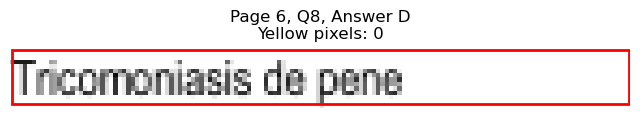

Page 6, Q8 - E: Detected box: x0=327.0, y0=619.6, x1=413.8, y1=632.3
Page 6, Q8, E: Yellow pixels: 0
Page 6, Q8, E: Total non-white pixels: 431
Page 6, Q8, E: Yellow percentage: 0.0%


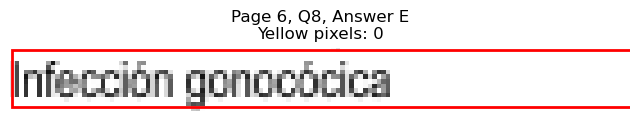


Page 6, Q8 - Selected Answer: A (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=68.3, y0=682.7, x1=113.9, y1=695.3
Page 6, Q9, A: Yellow pixels: 0
Page 6, Q9, A: Total non-white pixels: 222
Page 6, Q9, A: Yellow percentage: 0.0%


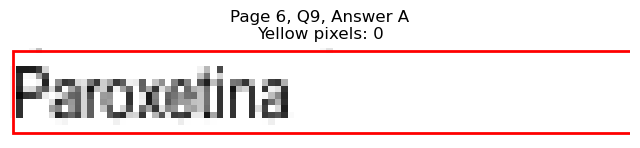

Page 6, Q9 - B: Detected box: x0=68.3, y0=695.4, x1=109.5, y1=708.0
Page 6, Q9, B: Yellow pixels: 0
Page 6, Q9, B: Total non-white pixels: 219
Page 6, Q9, B: Yellow percentage: 0.0%


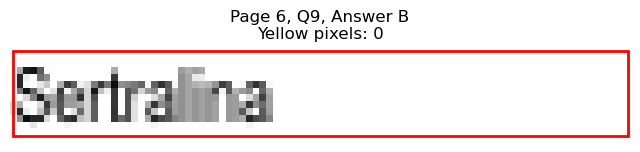

Page 6, Q9 - C: Detected box: x0=68.8, y0=708.0, x1=112.9, y1=720.6
Page 6, Q9, C: Yellow pixels: 0
Page 6, Q9, C: Total non-white pixels: 210
Page 6, Q9, C: Yellow percentage: 0.0%


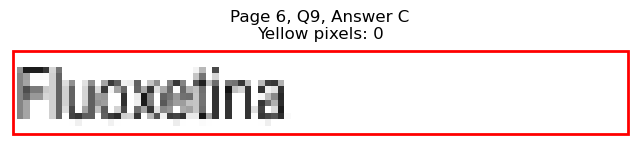

Page 6, Q9 - D: Detected box: x0=327.5, y0=682.7, x1=385.7, y1=695.3
Page 6, Q9, D: Yellow pixels: 0
Page 6, Q9, D: Total non-white pixels: 294
Page 6, Q9, D: Yellow percentage: 0.0%


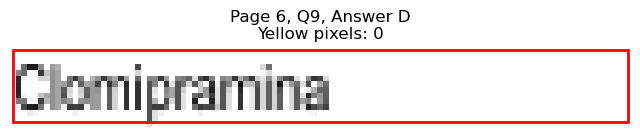

Page 6, Q9 - E: Detected box: x0=327.0, y0=695.4, x1=372.8, y1=708.0
Page 6, Q9, E: Yellow pixels: 1070
Page 6, Q9, E: Total non-white pixels: 1249
Page 6, Q9, E: Yellow percentage: 85.7%


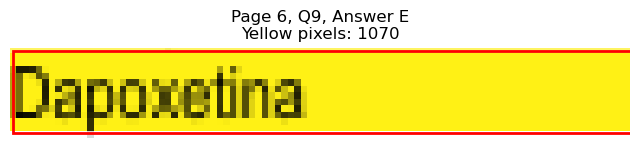


Page 6, Q9 - Selected Answer: E (based on yellow pixel count)





Page 7: Found 9 questions
Page 7, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=141.0, y1=102.1
Page 7, Q1, A: Yellow pixels: 0
Page 7, Q1, A: Total non-white pixels: 395
Page 7, Q1, A: Yellow percentage: 0.0%


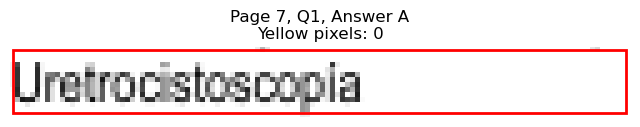

Page 7, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=136.9, y1=114.7
Page 7, Q1, B: Yellow pixels: 0
Page 7, Q1, B: Total non-white pixels: 426
Page 7, Q1, B: Yellow percentage: 0.0%


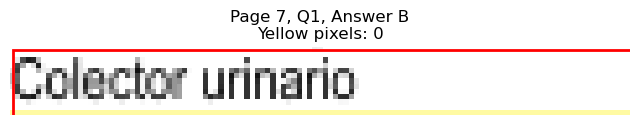

Page 7, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=169.6, y1=127.3
Page 7, Q1, C: Yellow pixels: 1412
Page 7, Q1, C: Total non-white pixels: 2128
Page 7, Q1, C: Yellow percentage: 66.4%


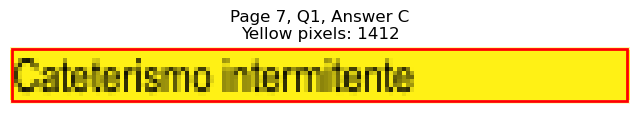

Page 7, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=397.7, y1=102.1
Page 7, Q1, D: Yellow pixels: 0
Page 7, Q1, D: Total non-white pixels: 377
Page 7, Q1, D: Yellow percentage: 0.0%


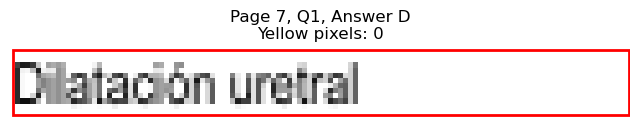

Page 7, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=406.3, y1=114.7
Page 7, Q1, E: Yellow pixels: 0
Page 7, Q1, E: Total non-white pixels: 403
Page 7, Q1, E: Yellow percentage: 0.0%


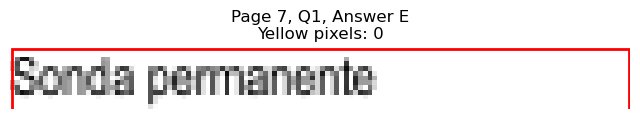


Page 7, Q1 - Selected Answer: C (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=121.2, y0=177.7, x1=187.4, y1=190.4
Page 7, Q2, A: Yellow pixels: 0
Page 7, Q2, A: Total non-white pixels: 554
Page 7, Q2, A: Yellow percentage: 0.0%


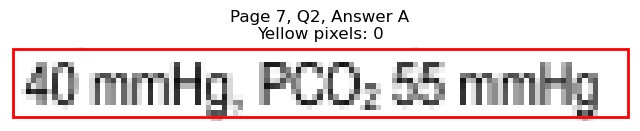

Page 7, Q2 - B: Detected box: x0=116.2, y0=190.3, x1=182.4, y1=203.0
Page 7, Q2, B: Yellow pixels: 0
Page 7, Q2, B: Total non-white pixels: 655
Page 7, Q2, B: Yellow percentage: 0.0%


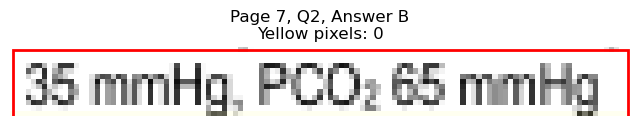

Page 7, Q2 - C: Detected box: x0=116.7, y0=202.9, x1=182.9, y1=215.6
Page 7, Q2, C: Yellow pixels: 1099
Page 7, Q2, C: Total non-white pixels: 1638
Page 7, Q2, C: Yellow percentage: 67.1%


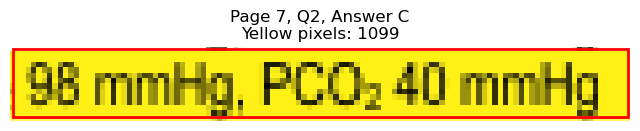

Page 7, Q2 - D: Detected box: x0=121.7, y0=215.7, x1=187.9, y1=228.3
Page 7, Q2, D: Yellow pixels: 114
Page 7, Q2, D: Total non-white pixels: 664
Page 7, Q2, D: Yellow percentage: 17.2%


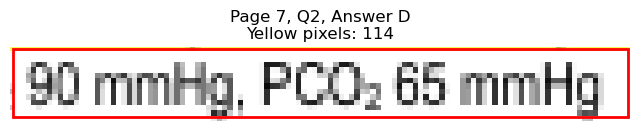

Page 7, Q2 - E: Detected box: x0=121.2, y0=228.3, x1=187.4, y1=240.9
Page 7, Q2, E: Yellow pixels: 0
Page 7, Q2, E: Total non-white pixels: 552
Page 7, Q2, E: Yellow percentage: 0.0%


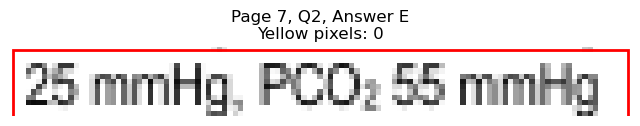


Page 7, Q2 - Selected Answer: C (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=68.3, y0=278.8, x1=154.6, y1=291.5
Page 7, Q3, A: Yellow pixels: 137
Page 7, Q3, A: Total non-white pixels: 574
Page 7, Q3, A: Yellow percentage: 23.9%


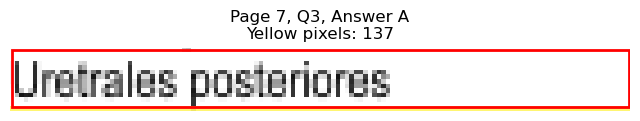

Page 7, Q3 - B: Detected box: x0=68.3, y0=291.4, x1=184.7, y1=304.1
Page 7, Q3, B: Yellow pixels: 1741
Page 7, Q3, B: Total non-white pixels: 2338
Page 7, Q3, B: Yellow percentage: 74.5%


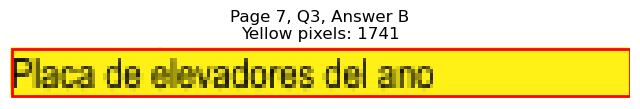

Page 7, Q3 - C: Detected box: x0=68.8, y0=304.0, x1=165.1, y1=316.7
Page 7, Q3, C: Yellow pixels: 0
Page 7, Q3, C: Total non-white pixels: 643
Page 7, Q3, C: Yellow percentage: 0.0%


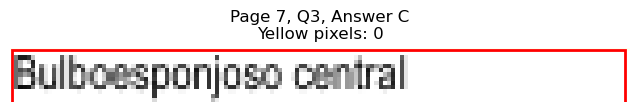

Page 7, Q3 - D: Detected box: x0=327.5, y0=278.8, x1=428.8, y1=291.5
Page 7, Q3, D: Yellow pixels: 0
Page 7, Q3, D: Total non-white pixels: 513
Page 7, Q3, D: Yellow percentage: 0.0%


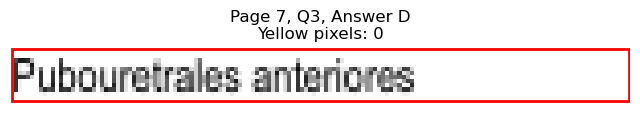

Page 7, Q3 - E: Detected box: x0=327.0, y0=291.4, x1=431.9, y1=304.1
Page 7, Q3, E: Yellow pixels: 0
Page 7, Q3, E: Total non-white pixels: 557
Page 7, Q3, E: Yellow percentage: 0.0%


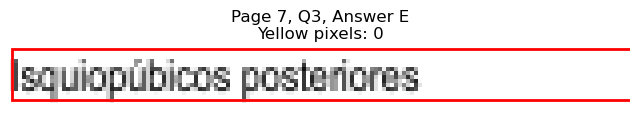


Page 7, Q3 - Selected Answer: B (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=143.5, y1=354.6
Page 7, Q4, A: Yellow pixels: 126
Page 7, Q4, A: Total non-white pixels: 485
Page 7, Q4, A: Yellow percentage: 26.0%


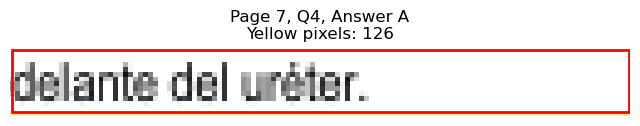

Page 7, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=180.6, y1=367.2
Page 7, Q4, B: Yellow pixels: 1666
Page 7, Q4, B: Total non-white pixels: 2282
Page 7, Q4, B: Yellow percentage: 73.0%


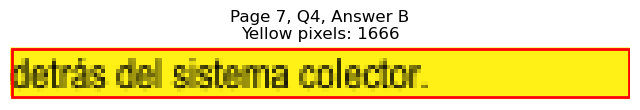

Page 7, Q4 - C: Detected box: x0=68.8, y0=367.1, x1=169.6, y1=379.8
Page 7, Q4, C: Yellow pixels: 0
Page 7, Q4, C: Total non-white pixels: 591
Page 7, Q4, C: Yellow percentage: 0.0%


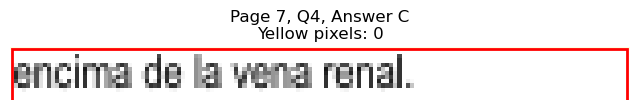

Page 7, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=444.9, y1=354.6
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 609
Page 7, Q4, D: Yellow percentage: 0.0%


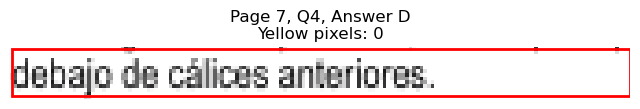

Page 7, Q4 - E: Detected box: x0=327.0, y0=354.5, x1=432.4, y1=367.2
Page 7, Q4, E: Yellow pixels: 0
Page 7, Q4, E: Total non-white pixels: 512
Page 7, Q4, E: Yellow percentage: 0.0%


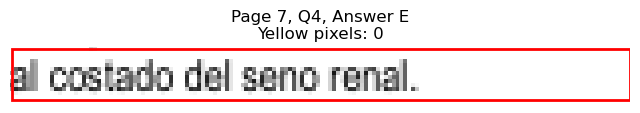


Page 7, Q4 - Selected Answer: B (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=98.9, y1=417.6
Page 7, Q5, A: Yellow pixels: 0
Page 7, Q5, A: Total non-white pixels: 158
Page 7, Q5, A: Yellow percentage: 0.0%


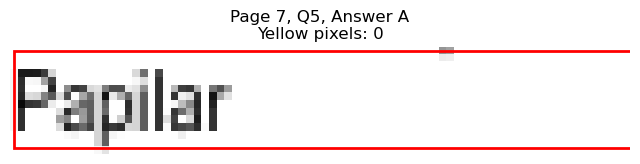

Page 7, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=129.5, y1=430.3
Page 7, Q5, B: Yellow pixels: 112
Page 7, Q5, B: Total non-white pixels: 429
Page 7, Q5, B: Yellow percentage: 26.1%


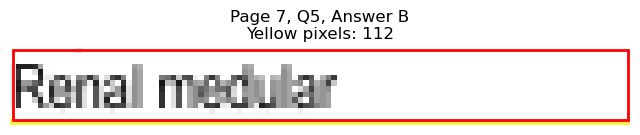

Page 7, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=139.9, y1=442.9
Page 7, Q5, C: Yellow pixels: 1315
Page 7, Q5, C: Total non-white pixels: 1586
Page 7, Q5, C: Yellow percentage: 82.9%


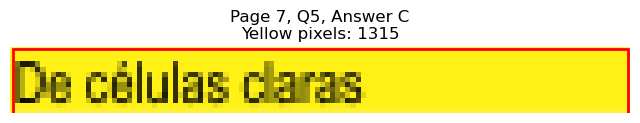

Page 7, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=374.7, y1=417.6
Page 7, Q5, D: Yellow pixels: 0
Page 7, Q5, D: Total non-white pixels: 237
Page 7, Q5, D: Yellow percentage: 0.0%


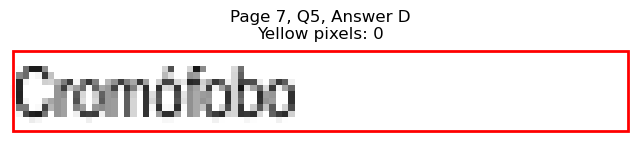

Page 7, Q5 - E: Detected box: x0=327.0, y0=417.6, x1=398.3, y1=430.3
Page 7, Q5, E: Yellow pixels: 0
Page 7, Q5, E: Total non-white pixels: 355
Page 7, Q5, E: Yellow percentage: 0.0%


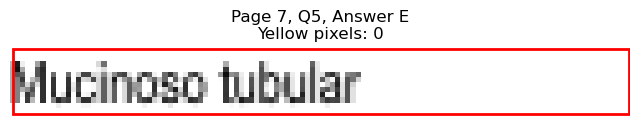


Page 7, Q5 - Selected Answer: C (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=68.3, y0=493.4, x1=166.6, y1=506.0
Page 7, Q6, A: Yellow pixels: 0
Page 7, Q6, A: Total non-white pixels: 471
Page 7, Q6, A: Yellow percentage: 0.0%


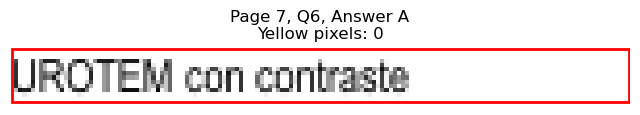

Page 7, Q6 - B: Detected box: x0=68.3, y0=506.0, x1=176.7, y1=518.6
Page 7, Q6, B: Yellow pixels: 0
Page 7, Q6, B: Total non-white pixels: 534
Page 7, Q6, B: Yellow percentage: 0.0%


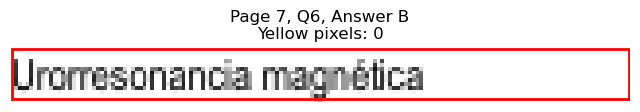

Page 7, Q6 - C: Detected box: x0=68.8, y0=518.6, x1=158.1, y1=531.2
Page 7, Q6, C: Yellow pixels: 0
Page 7, Q6, C: Total non-white pixels: 460
Page 7, Q6, C: Yellow percentage: 0.0%


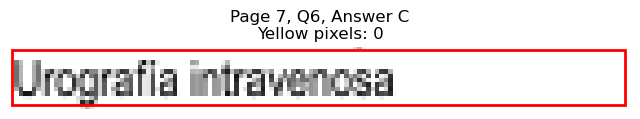

Page 7, Q6 - D: Detected box: x0=327.5, y0=493.4, x1=413.8, y1=506.0
Page 7, Q6, D: Yellow pixels: 137
Page 7, Q6, D: Total non-white pixels: 723
Page 7, Q6, D: Yellow percentage: 18.9%


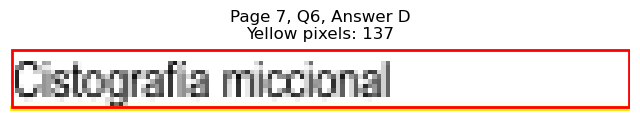

Page 7, Q6 - E: Detected box: x0=327.0, y0=506.0, x1=452.9, y1=518.6
Page 7, Q6, E: Yellow pixels: 1793
Page 7, Q6, E: Total non-white pixels: 2464
Page 7, Q6, E: Yellow percentage: 72.8%


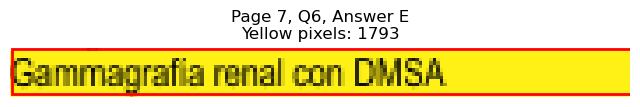


Page 7, Q6 - Selected Answer: E (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=215.3, y1=569.2
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 730
Page 7, Q7, A: Yellow percentage: 0.0%


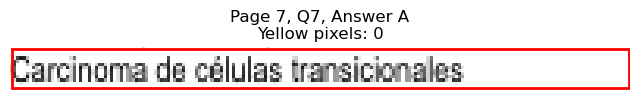

Page 7, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=138.5, y1=581.8
Page 7, Q7, B: Yellow pixels: 0
Page 7, Q7, B: Total non-white pixels: 346
Page 7, Q7, B: Yellow percentage: 0.0%


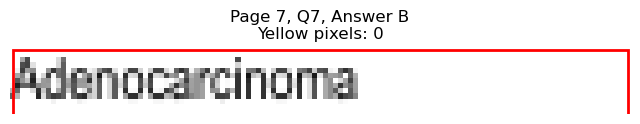

Page 7, Q7 - C: Detected box: x0=68.8, y0=581.7, x1=136.5, y1=594.4
Page 7, Q7, C: Yellow pixels: 0
Page 7, Q7, C: Total non-white pixels: 373
Page 7, Q7, C: Yellow percentage: 0.0%


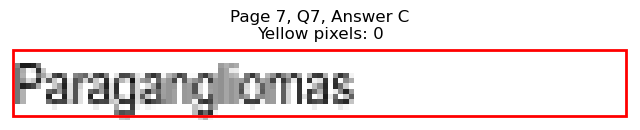

Page 7, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=366.2, y1=569.2
Page 7, Q7, D: Yellow pixels: 90
Page 7, Q7, D: Total non-white pixels: 278
Page 7, Q7, D: Yellow percentage: 32.4%


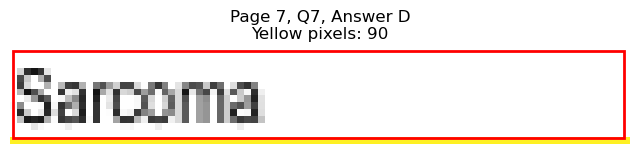

Page 7, Q7 - E: Detected box: x0=327.0, y0=569.1, x1=425.3, y1=581.8
Page 7, Q7, E: Yellow pixels: 1547
Page 7, Q7, E: Total non-white pixels: 1937
Page 7, Q7, E: Yellow percentage: 79.9%


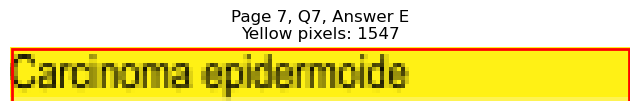


Page 7, Q7 - Selected Answer: E (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=106.5, y1=632.3
Page 7, Q8, A: Yellow pixels: 0
Page 7, Q8, A: Total non-white pixels: 213
Page 7, Q8, A: Yellow percentage: 0.0%


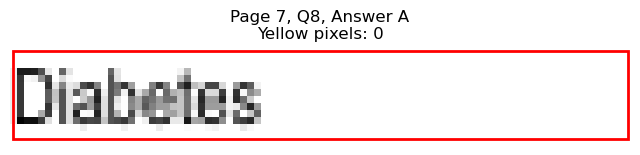

Page 7, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=141.5, y1=644.9
Page 7, Q8, B: Yellow pixels: 0
Page 7, Q8, B: Total non-white pixels: 475
Page 7, Q8, B: Yellow percentage: 0.0%


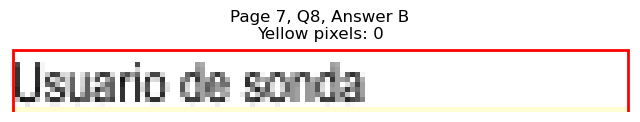

Page 7, Q8 - C: Detected box: x0=68.8, y0=644.9, x1=112.5, y1=657.5
Page 7, Q8, C: Yellow pixels: 1071
Page 7, Q8, C: Total non-white pixels: 1330
Page 7, Q8, C: Yellow percentage: 80.5%


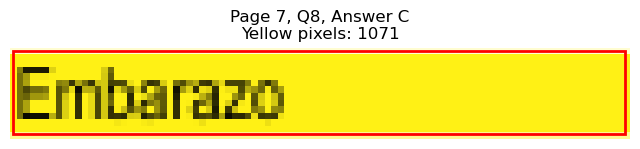

Page 7, Q8 - D: Detected box: x0=327.5, y0=619.6, x1=379.3, y1=632.3
Page 7, Q8, D: Yellow pixels: 0
Page 7, Q8, D: Total non-white pixels: 276
Page 7, Q8, D: Yellow percentage: 0.0%


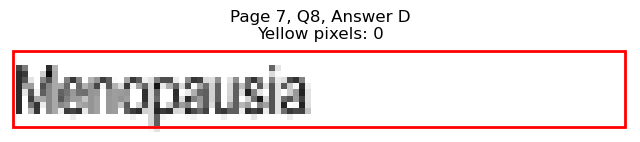

Page 7, Q8 - E: Detected box: x0=327.0, y0=632.2, x1=383.2, y1=644.9
Page 7, Q8, E: Yellow pixels: 0
Page 7, Q8, E: Total non-white pixels: 302
Page 7, Q8, E: Yellow percentage: 0.0%


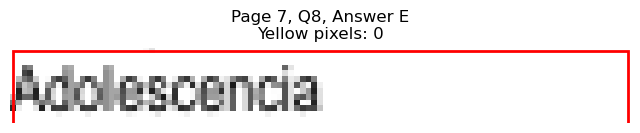


Page 7, Q8 - Selected Answer: C (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=103.9, y1=708.0
Page 7, Q9, A: Yellow pixels: 0
Page 7, Q9, A: Total non-white pixels: 158
Page 7, Q9, A: Yellow percentage: 0.0%


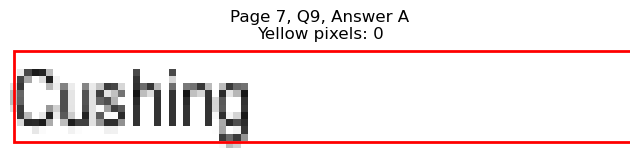

Page 7, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=99.4, y1=720.6
Page 7, Q9, B: Yellow pixels: 0
Page 7, Q9, B: Total non-white pixels: 168
Page 7, Q9, B: Yellow percentage: 0.0%


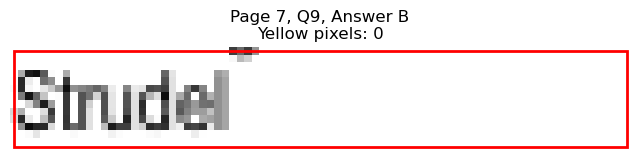

Page 7, Q9 - C: Detected box: x0=68.8, y0=720.6, x1=145.5, y1=733.2
Page 7, Q9, C: Yellow pixels: 0
Page 7, Q9, C: Total non-white pixels: 390
Page 7, Q9, C: Yellow percentage: 0.0%


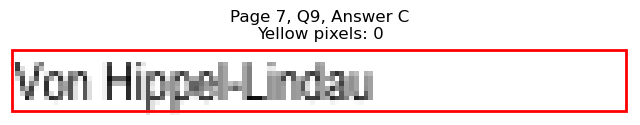

Page 7, Q9 - D: Detected box: x0=327.5, y0=695.4, x1=361.6, y1=708.0
Page 7, Q9, D: Yellow pixels: 947
Page 7, Q9, D: Total non-white pixels: 1105
Page 7, Q9, D: Yellow percentage: 85.7%


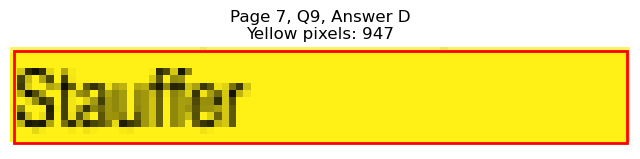

Page 7, Q9 - E: Detected box: x0=327.0, y0=708.0, x1=389.8, y1=720.6
Page 7, Q9, E: Yellow pixels: 113
Page 7, Q9, E: Total non-white pixels: 475
Page 7, Q9, E: Yellow percentage: 23.8%


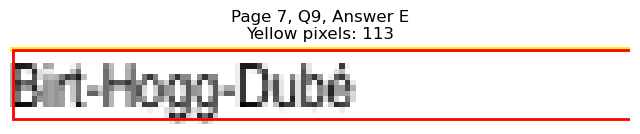


Page 7, Q9 - Selected Answer: D (based on yellow pixel count)





Page 8: Found 9 questions
Page 8, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=112.5, y1=114.7
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 229
Page 8, Q1, A: Yellow percentage: 0.0%


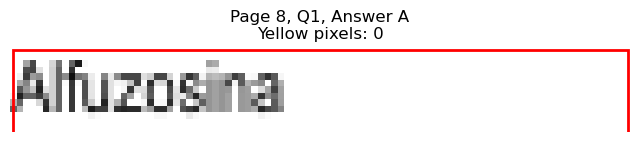

Page 8, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=115.5, y1=127.3
Page 8, Q1, B: Yellow pixels: 0
Page 8, Q1, B: Total non-white pixels: 250
Page 8, Q1, B: Yellow percentage: 0.0%


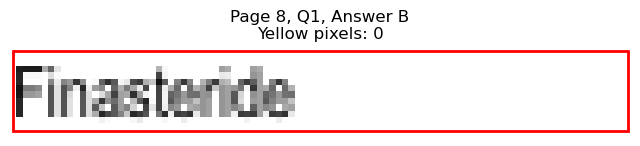

Page 8, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=110.4, y1=139.9
Page 8, Q1, C: Yellow pixels: 0
Page 8, Q1, C: Total non-white pixels: 211
Page 8, Q1, C: Yellow percentage: 0.0%


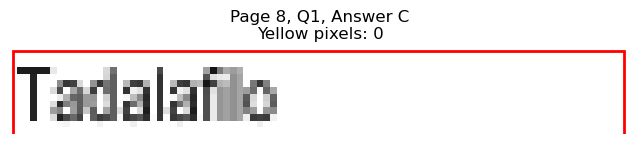

Page 8, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=381.2, y1=114.7
Page 8, Q1, D: Yellow pixels: 1160
Page 8, Q1, D: Total non-white pixels: 1365
Page 8, Q1, D: Yellow percentage: 85.0%


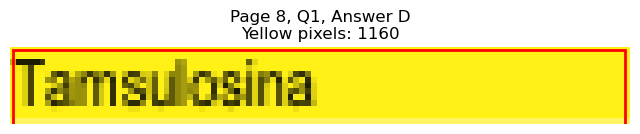

Page 8, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=375.7, y1=127.3
Page 8, Q1, E: Yellow pixels: 99
Page 8, Q1, E: Total non-white pixels: 362
Page 8, Q1, E: Yellow percentage: 27.3%


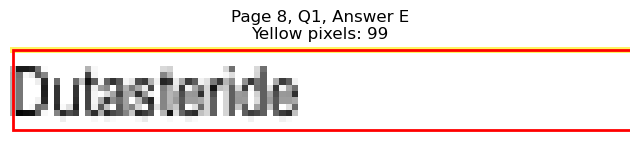


Page 8, Q1 - Selected Answer: D (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=126.5, y1=177.8
Page 8, Q2, A: Yellow pixels: 0
Page 8, Q2, A: Total non-white pixels: 297
Page 8, Q2, A: Yellow percentage: 0.0%


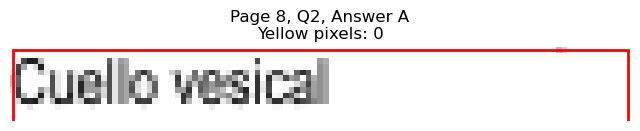

Page 8, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=109.0, y1=190.4
Page 8, Q2, B: Yellow pixels: 0
Page 8, Q2, B: Total non-white pixels: 216
Page 8, Q2, B: Yellow percentage: 0.0%


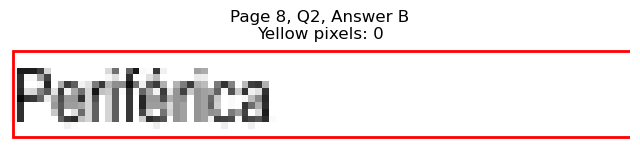

Page 8, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=106.9, y1=203.0
Page 8, Q2, C: Yellow pixels: 0
Page 8, Q2, C: Total non-white pixels: 175
Page 8, Q2, C: Yellow percentage: 0.0%


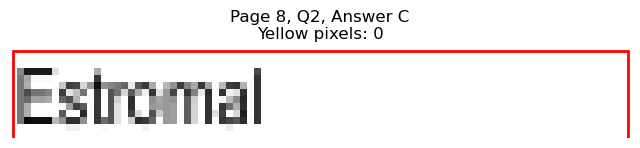

Page 8, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=405.3, y1=177.8
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 546
Page 8, Q2, D: Yellow percentage: 0.0%


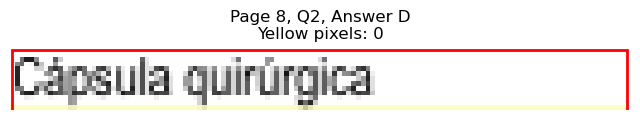

Page 8, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=382.3, y1=190.4
Page 8, Q2, E: Yellow pixels: 1074
Page 8, Q2, E: Total non-white pixels: 1484
Page 8, Q2, E: Yellow percentage: 72.4%


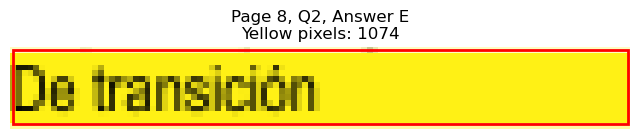


Page 8, Q2 - Selected Answer: E (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=78.4, y1=240.9
Page 8, Q3, A: Yellow pixels: 761
Page 8, Q3, A: Total non-white pixels: 793
Page 8, Q3, A: Yellow percentage: 96.0%


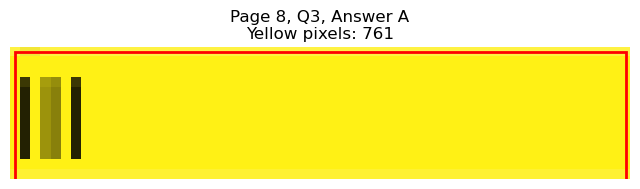

Page 8, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=79.3, y1=253.5
Page 8, Q3, B: Yellow pixels: 62
Page 8, Q3, B: Total non-white pixels: 101
Page 8, Q3, B: Yellow percentage: 61.4%


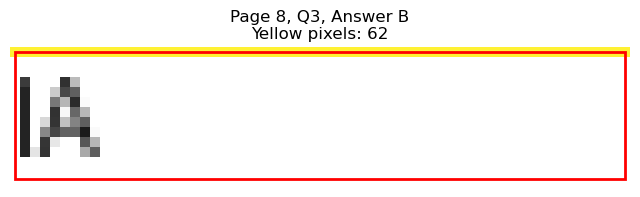

Page 8, Q3 - C: Detected box: x0=56.6, y0=253.5, x1=65.6, y1=266.1
Page 8, Q3, C: Yellow pixels: 0
Page 8, Q3, C: Total non-white pixels: 61
Page 8, Q3, C: Yellow percentage: 0.0%


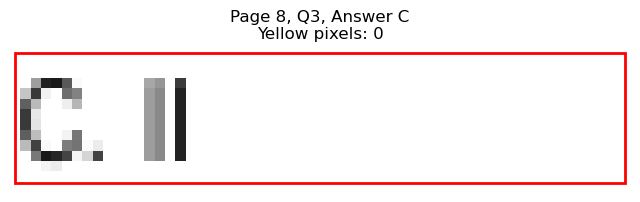

Page 8, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=343.1, y1=240.9
Page 8, Q3, D: Yellow pixels: 0
Page 8, Q3, D: Total non-white pixels: 62
Page 8, Q3, D: Yellow percentage: 0.0%


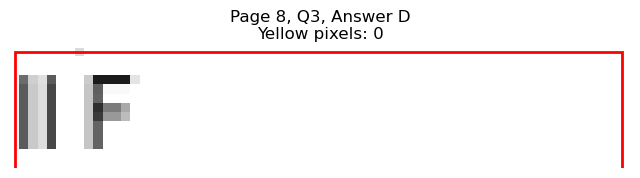

Page 8, Q3 - E: Detected box: x0=327.0, y0=240.9, x1=343.6, y1=253.5
Page 8, Q3, E: Yellow pixels: 0
Page 8, Q3, E: Total non-white pixels: 65
Page 8, Q3, E: Yellow percentage: 0.0%


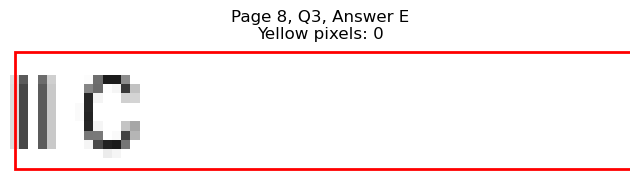


Page 8, Q3 - Selected Answer: A (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=133.0, y1=329.3
Page 8, Q4, A: Yellow pixels: 0
Page 8, Q4, A: Total non-white pixels: 320
Page 8, Q4, A: Yellow percentage: 0.0%


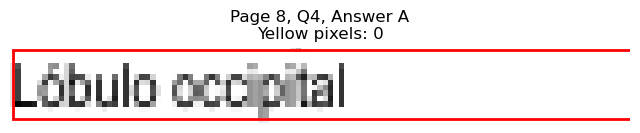

Page 8, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=130.0, y1=341.9
Page 8, Q4, B: Yellow pixels: 0
Page 8, Q4, B: Total non-white pixels: 298
Page 8, Q4, B: Yellow percentage: 0.0%


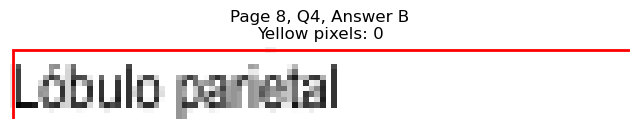

Page 8, Q4 - C: Detected box: x0=68.8, y0=341.9, x1=107.9, y1=354.6
Page 8, Q4, C: Yellow pixels: 0
Page 8, Q4, C: Total non-white pixels: 207
Page 8, Q4, C: Yellow percentage: 0.0%


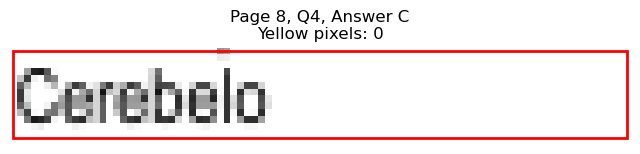

Page 8, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=401.2, y1=329.3
Page 8, Q4, D: Yellow pixels: 125
Page 8, Q4, D: Total non-white pixels: 493
Page 8, Q4, D: Yellow percentage: 25.4%


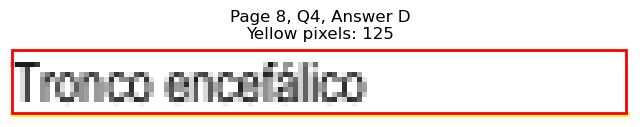

Page 8, Q4 - E: Detected box: x0=327.0, y0=329.2, x1=384.3, y1=341.9
Page 8, Q4, E: Yellow pixels: 1168
Page 8, Q4, E: Total non-white pixels: 1404
Page 8, Q4, E: Yellow percentage: 83.2%


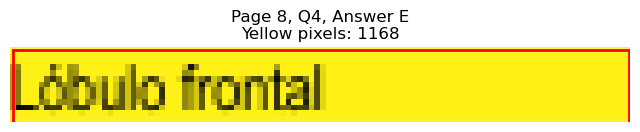


Page 8, Q4 - Selected Answer: E (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=139.6, y1=417.6
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 359
Page 8, Q5, A: Yellow percentage: 0.0%


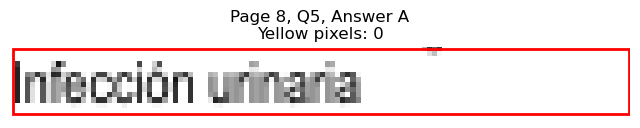

Page 8, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=136.5, y1=430.3
Page 8, Q5, B: Yellow pixels: 119
Page 8, Q5, B: Total non-white pixels: 438
Page 8, Q5, B: Yellow percentage: 27.2%


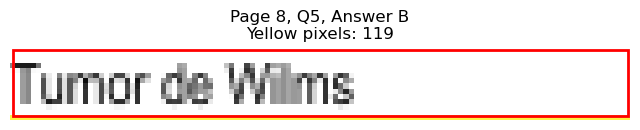

Page 8, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=110.4, y1=442.9
Page 8, Q5, C: Yellow pixels: 1021
Page 8, Q5, C: Total non-white pixels: 1209
Page 8, Q5, C: Yellow percentage: 84.4%


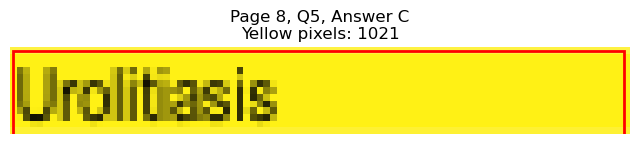

Page 8, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=363.2, y1=417.6
Page 8, Q5, D: Yellow pixels: 0
Page 8, Q5, D: Total non-white pixels: 186
Page 8, Q5, D: Yellow percentage: 0.0%


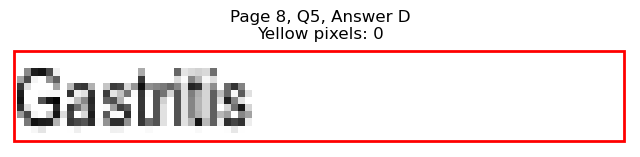

Page 8, Q5 - E: Detected box: x0=327.0, y0=417.6, x1=373.3, y1=430.3
Page 8, Q5, E: Yellow pixels: 0
Page 8, Q5, E: Total non-white pixels: 257
Page 8, Q5, E: Yellow percentage: 0.0%


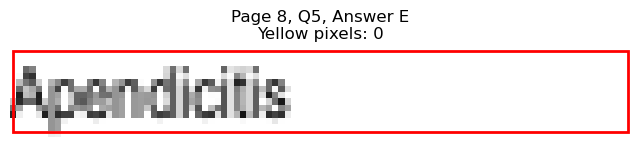


Page 8, Q5 - Selected Answer: C (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=96.9, y1=493.4
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 138
Page 8, Q6, A: Yellow percentage: 0.0%


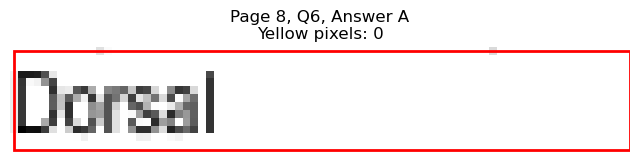

Page 8, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=105.9, y1=506.0
Page 8, Q6, B: Yellow pixels: 0
Page 8, Q6, B: Total non-white pixels: 177
Page 8, Q6, B: Yellow percentage: 0.0%


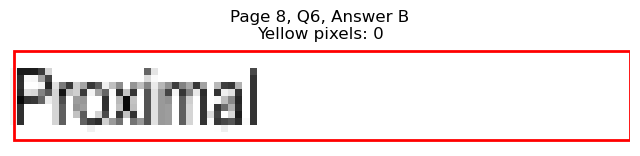

Page 8, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=102.9, y1=518.6
Page 8, Q6, C: Yellow pixels: 0
Page 8, Q6, C: Total non-white pixels: 157
Page 8, Q6, C: Yellow percentage: 0.0%


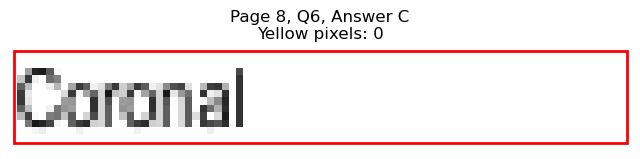

Page 8, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=357.7, y1=493.4
Page 8, Q6, D: Yellow pixels: 855
Page 8, Q6, D: Total non-white pixels: 1134
Page 8, Q6, D: Yellow percentage: 75.4%


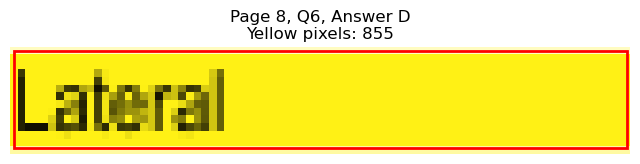

Page 8, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=358.6, y1=506.0
Page 8, Q6, E: Yellow pixels: 0
Page 8, Q6, E: Total non-white pixels: 253
Page 8, Q6, E: Yellow percentage: 0.0%


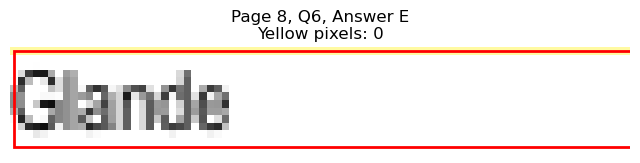


Page 8, Q6 - Selected Answer: D (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=121.5, y1=556.4
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 256
Page 8, Q7, A: Yellow percentage: 0.0%


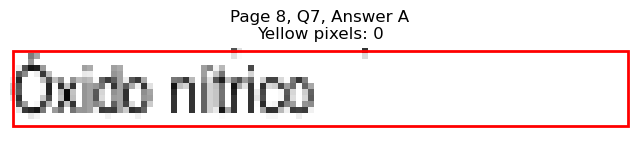

Page 8, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=113.4, y1=569.2
Page 8, Q7, B: Yellow pixels: 96
Page 8, Q7, B: Total non-white pixels: 341
Page 8, Q7, B: Yellow percentage: 28.2%


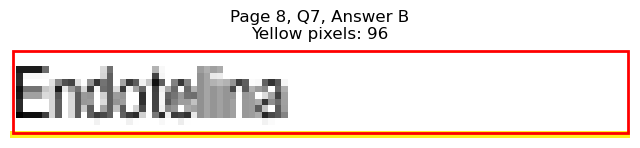

Page 8, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=127.9, y1=581.8
Page 8, Q7, C: Yellow pixels: 1196
Page 8, Q7, C: Total non-white pixels: 1430
Page 8, Q7, C: Yellow percentage: 83.6%


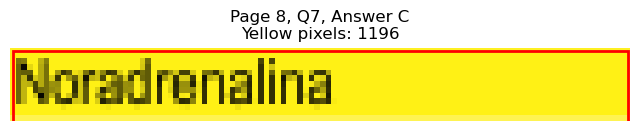

Page 8, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=375.7, y1=556.4
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 257
Page 8, Q7, D: Yellow percentage: 0.0%


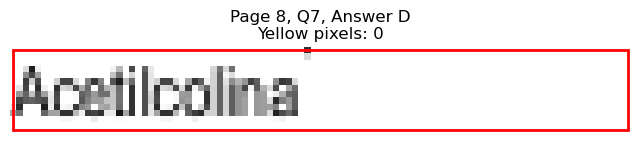

Page 8, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=372.7, y1=569.2
Page 8, Q7, E: Yellow pixels: 0
Page 8, Q7, E: Total non-white pixels: 244
Page 8, Q7, E: Yellow percentage: 0.0%


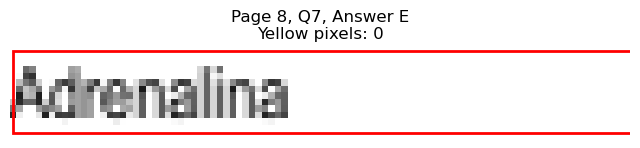


Page 8, Q7 - Selected Answer: C (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=160.6, y1=619.6
Page 8, Q8, A: Yellow pixels: 0
Page 8, Q8, A: Total non-white pixels: 428
Page 8, Q8, A: Yellow percentage: 0.0%


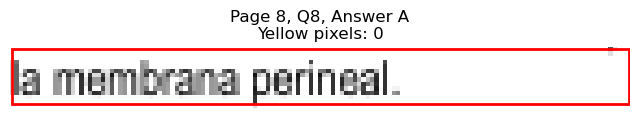

Page 8, Q8 - B: Detected box: x0=68.3, y0=619.6, x1=175.6, y1=632.3
Page 8, Q8, B: Yellow pixels: 1495
Page 8, Q8, B: Total non-white pixels: 2212
Page 8, Q8, B: Yellow percentage: 67.6%


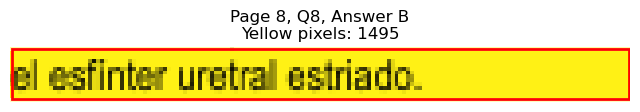

Page 8, Q8 - C: Detected box: x0=68.8, y0=632.2, x1=181.6, y1=644.9
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 694
Page 8, Q8, C: Yellow percentage: 0.0%


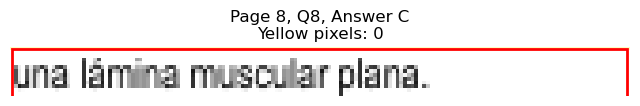

Page 8, Q8 - D: Detected box: x0=327.5, y0=606.9, x1=403.7, y1=619.6
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 379
Page 8, Q8, D: Yellow percentage: 0.0%


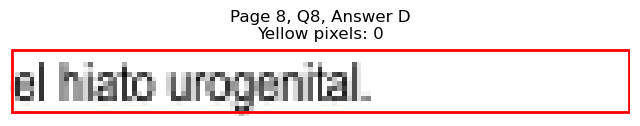

Page 8, Q8 - E: Detected box: x0=327.0, y0=619.6, x1=456.1, y1=632.3
Page 8, Q8, E: Yellow pixels: 0
Page 8, Q8, E: Total non-white pixels: 687
Page 8, Q8, E: Yellow percentage: 0.0%


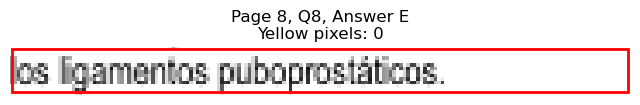


Page 8, Q8 - Selected Answer: B (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=68.3, y0=682.7, x1=219.3, y1=695.3
Page 8, Q9, A: Yellow pixels: 0
Page 8, Q9, A: Total non-white pixels: 697
Page 8, Q9, A: Yellow percentage: 0.0%


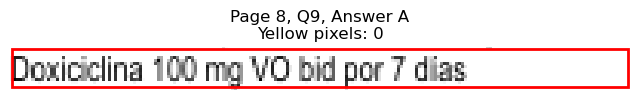

Page 8, Q9 - B: Detected box: x0=68.3, y0=695.4, x1=230.8, y1=708.0
Page 8, Q9, B: Yellow pixels: 2149
Page 8, Q9, B: Total non-white pixels: 2770
Page 8, Q9, B: Yellow percentage: 77.6%


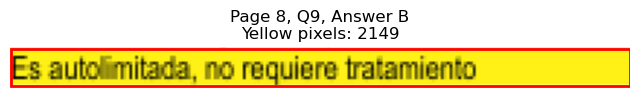

Page 8, Q9 - C: Detected box: x0=68.8, y0=708.0, x1=233.3, y1=720.6
Page 8, Q9, C: Yellow pixels: 212
Page 8, Q9, C: Total non-white pixels: 1040
Page 8, Q9, C: Yellow percentage: 20.4%


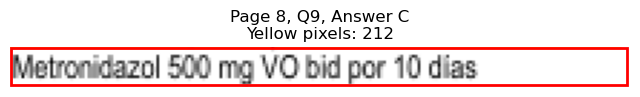

Page 8, Q9 - D: Detected box: x0=327.5, y0=682.7, x1=502.2, y1=695.3
Page 8, Q9, D: Yellow pixels: 0
Page 8, Q9, D: Total non-white pixels: 868
Page 8, Q9, D: Yellow percentage: 0.0%


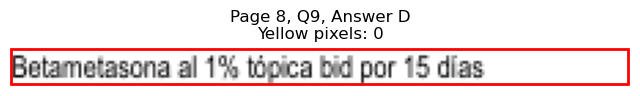

Page 8, Q9 - E: Detected box: x0=327.0, y0=695.4, x1=504.1, y1=708.0
Page 8, Q9, E: Yellow pixels: 0
Page 8, Q9, E: Total non-white pixels: 851
Page 8, Q9, E: Yellow percentage: 0.0%


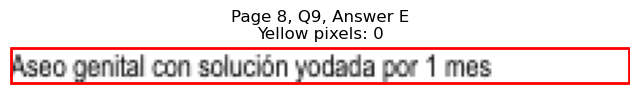


Page 8, Q9 - Selected Answer: B (based on yellow pixel count)





Page 9: Found 10 questions
Page 9, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=127.9, y1=102.1
Page 9, Q1, A: Yellow pixels: 0
Page 9, Q1, A: Total non-white pixels: 284
Page 9, Q1, A: Yellow percentage: 0.0%


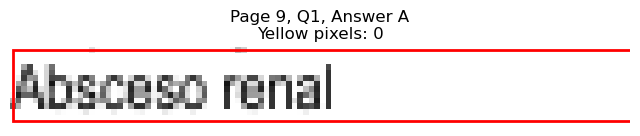

Page 9, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=163.1, y1=114.7
Page 9, Q1, B: Yellow pixels: 0
Page 9, Q1, B: Total non-white pixels: 504
Page 9, Q1, B: Yellow percentage: 0.0%


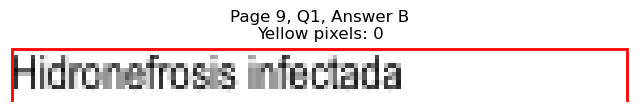

Page 9, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=174.1, y1=127.3
Page 9, Q1, C: Yellow pixels: 0
Page 9, Q1, C: Total non-white pixels: 553
Page 9, Q1, C: Yellow percentage: 0.0%


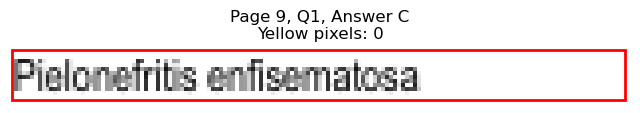

Page 9, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=410.8, y1=102.1
Page 9, Q1, D: Yellow pixels: 134
Page 9, Q1, D: Total non-white pixels: 544
Page 9, Q1, D: Yellow percentage: 24.6%


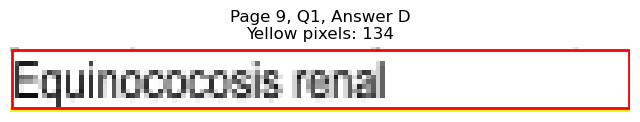

Page 9, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=460.4, y1=114.7
Page 9, Q1, E: Yellow pixels: 1827
Page 9, Q1, E: Total non-white pixels: 2392
Page 9, Q1, E: Yellow percentage: 76.4%


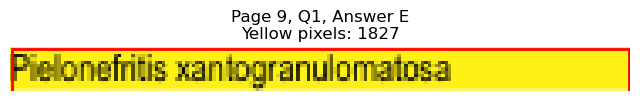


Page 9, Q1 - Selected Answer: E (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=142.0, y1=190.4
Page 9, Q2, A: Yellow pixels: 0
Page 9, Q2, A: Total non-white pixels: 364
Page 9, Q2, A: Yellow percentage: 0.0%


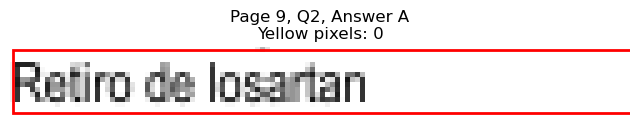

Page 9, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=163.1, y1=203.0
Page 9, Q2, B: Yellow pixels: 0
Page 9, Q2, B: Total non-white pixels: 472
Page 9, Q2, B: Yellow percentage: 0.0%


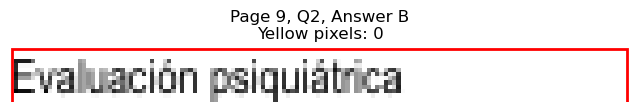

Page 9, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=153.5, y1=215.6
Page 9, Q2, C: Yellow pixels: 0
Page 9, Q2, C: Total non-white pixels: 452
Page 9, Q2, C: Yellow percentage: 0.0%


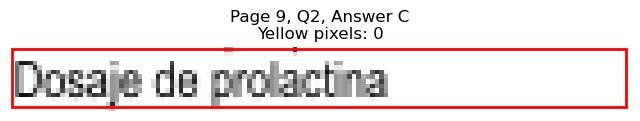

Page 9, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=400.3, y1=190.4
Page 9, Q2, D: Yellow pixels: 1201
Page 9, Q2, D: Total non-white pixels: 1736
Page 9, Q2, D: Yellow percentage: 69.2%


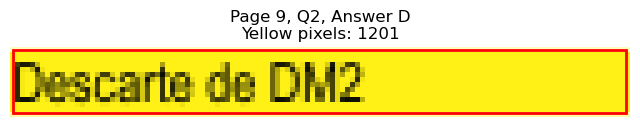

Page 9, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=411.3, y1=203.0
Page 9, Q2, E: Yellow pixels: 0
Page 9, Q2, E: Total non-white pixels: 574
Page 9, Q2, E: Yellow percentage: 0.0%


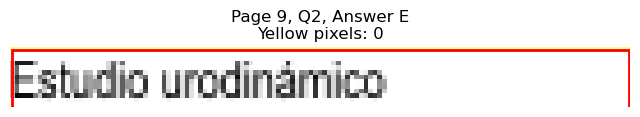


Page 9, Q2 - Selected Answer: D (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=139.6, y1=253.5
Page 9, Q3, A: Yellow pixels: 122
Page 9, Q3, A: Total non-white pixels: 472
Page 9, Q3, A: Yellow percentage: 25.8%


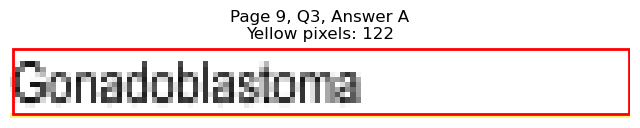

Page 9, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=109.5, y1=266.1
Page 9, Q3, B: Yellow pixels: 1033
Page 9, Q3, B: Total non-white pixels: 1288
Page 9, Q3, B: Yellow percentage: 80.2%


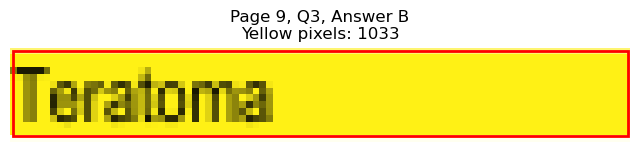

Page 9, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=127.9, y1=278.7
Page 9, Q3, C: Yellow pixels: 0
Page 9, Q3, C: Total non-white pixels: 403
Page 9, Q3, C: Yellow percentage: 0.0%


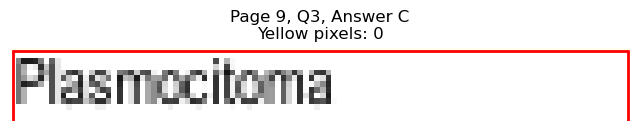

Page 9, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=373.1, y1=253.5
Page 9, Q3, D: Yellow pixels: 0
Page 9, Q3, D: Total non-white pixels: 229
Page 9, Q3, D: Yellow percentage: 0.0%


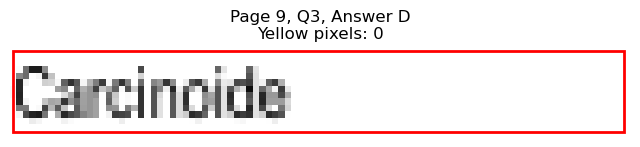

Page 9, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=387.8, y1=266.1
Page 9, Q3, E: Yellow pixels: 0
Page 9, Q3, E: Total non-white pixels: 324
Page 9, Q3, E: Yellow percentage: 0.0%


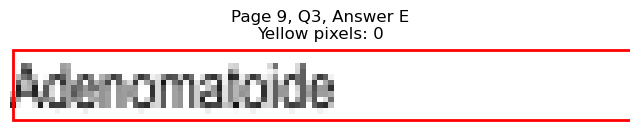


Page 9, Q3 - Selected Answer: B (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=123.0, y1=316.7
Page 9, Q4, A: Yellow pixels: 0
Page 9, Q4, A: Total non-white pixels: 279
Page 9, Q4, A: Yellow percentage: 0.0%


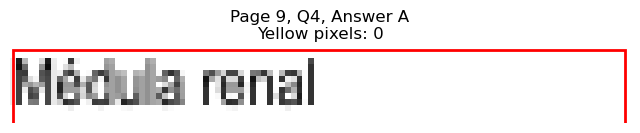

Page 9, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=118.9, y1=329.3
Page 9, Q4, B: Yellow pixels: 0
Page 9, Q4, B: Total non-white pixels: 235
Page 9, Q4, B: Yellow percentage: 0.0%


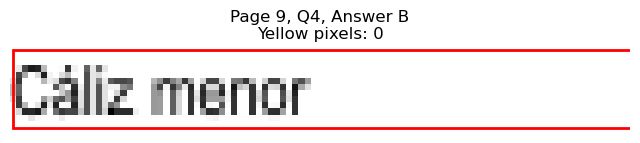

Page 9, Q4 - C: Detected box: x0=68.8, y0=329.2, x1=135.0, y1=341.9
Page 9, Q4, C: Yellow pixels: 0
Page 9, Q4, C: Total non-white pixels: 311
Page 9, Q4, C: Yellow percentage: 0.0%


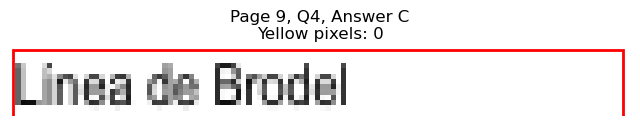

Page 9, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=377.7, y1=316.7
Page 9, Q4, D: Yellow pixels: 1
Page 9, Q4, D: Total non-white pixels: 349
Page 9, Q4, D: Yellow percentage: 0.3%


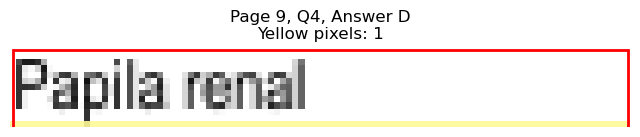

Page 9, Q4 - E: Detected box: x0=327.0, y0=316.6, x1=404.3, y1=329.3
Page 9, Q4, E: Yellow pixels: 1258
Page 9, Q4, E: Total non-white pixels: 1792
Page 9, Q4, E: Yellow percentage: 70.2%


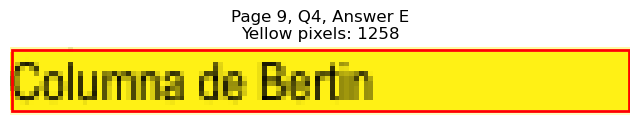


Page 9, Q4 - Selected Answer: E (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=68.3, y0=367.1, x1=102.9, y1=379.8
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 165
Page 9, Q5, A: Yellow percentage: 0.0%


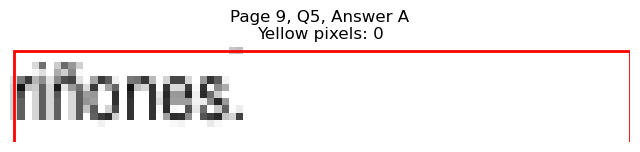

Page 9, Q5 - B: Detected box: x0=68.3, y0=379.7, x1=96.9, y1=392.4
Page 9, Q5, B: Yellow pixels: 0
Page 9, Q5, B: Total non-white pixels: 157
Page 9, Q5, B: Yellow percentage: 0.0%


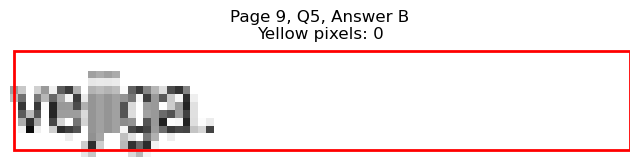

Page 9, Q5 - C: Detected box: x0=68.8, y0=392.3, x1=106.9, y1=405.0
Page 9, Q5, C: Yellow pixels: 0
Page 9, Q5, C: Total non-white pixels: 196
Page 9, Q5, C: Yellow percentage: 0.0%


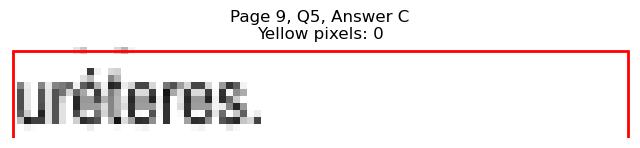

Page 9, Q5 - D: Detected box: x0=327.5, y0=367.1, x1=365.2, y1=379.8
Page 9, Q5, D: Yellow pixels: 1021
Page 9, Q5, D: Total non-white pixels: 1157
Page 9, Q5, D: Yellow percentage: 88.2%


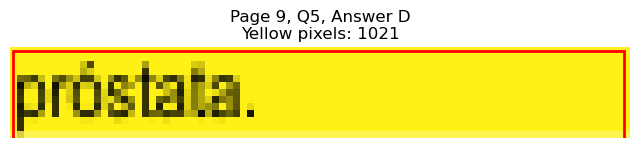

Page 9, Q5 - E: Detected box: x0=327.0, y0=379.7, x1=355.6, y1=392.4
Page 9, Q5, E: Yellow pixels: 79
Page 9, Q5, E: Total non-white pixels: 206
Page 9, Q5, E: Yellow percentage: 38.3%


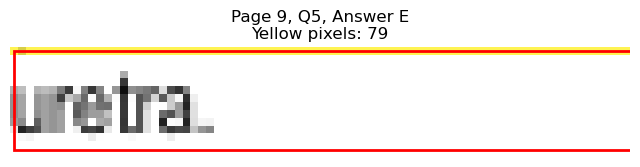


Page 9, Q5 - Selected Answer: D (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=68.3, y0=442.8, x1=88.3, y1=455.5
Page 9, Q6, A: Yellow pixels: 0
Page 9, Q6, A: Total non-white pixels: 106
Page 9, Q6, A: Yellow percentage: 0.0%


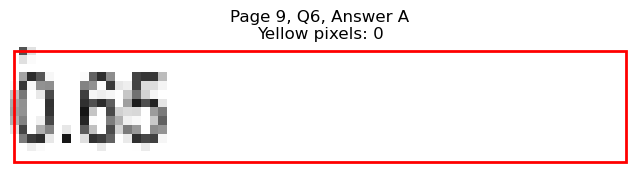

Page 9, Q6 - B: Detected box: x0=68.3, y0=455.5, x1=88.3, y1=468.1
Page 9, Q6, B: Yellow pixels: 0
Page 9, Q6, B: Total non-white pixels: 97
Page 9, Q6, B: Yellow percentage: 0.0%


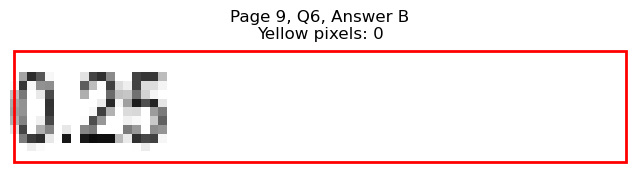

Page 9, Q6 - C: Detected box: x0=68.8, y0=468.1, x1=88.8, y1=480.7
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 96
Page 9, Q6, C: Yellow percentage: 0.0%


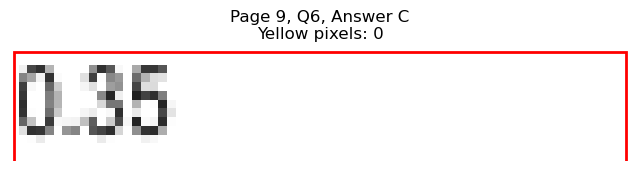

Page 9, Q6 - D: Detected box: x0=327.5, y0=442.8, x1=347.6, y1=455.5
Page 9, Q6, D: Yellow pixels: 863
Page 9, Q6, D: Total non-white pixels: 994
Page 9, Q6, D: Yellow percentage: 86.8%


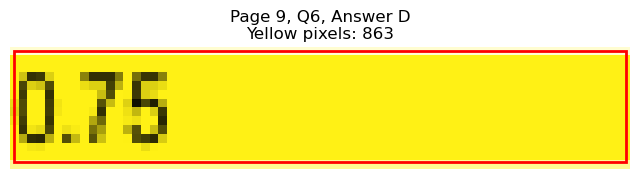

Page 9, Q6 - E: Detected box: x0=327.0, y0=455.5, x1=347.1, y1=468.1
Page 9, Q6, E: Yellow pixels: 0
Page 9, Q6, E: Total non-white pixels: 99
Page 9, Q6, E: Yellow percentage: 0.0%


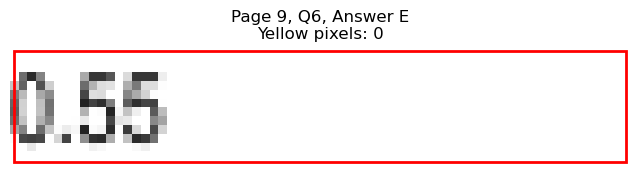


Page 9, Q6 - Selected Answer: D (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=68.3, y0=506.0, x1=334.7, y1=518.6
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 1337
Page 9, Q7, A: Yellow percentage: 0.0%


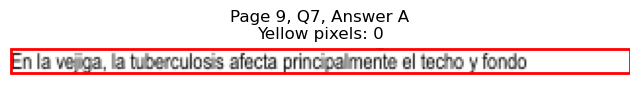

Page 9, Q7 - B: Detected box: x0=68.3, y0=518.6, x1=310.6, y1=531.2
Page 9, Q7, B: Yellow pixels: 293
Page 9, Q7, B: Total non-white pixels: 1490
Page 9, Q7, B: Yellow percentage: 19.7%


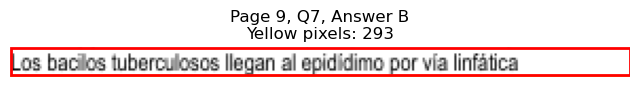

Page 9, Q7 - C: Detected box: x0=68.8, y0=531.2, x1=358.1, y1=543.8
Page 9, Q7, C: Yellow pixels: 3375
Page 9, Q7, C: Total non-white pixels: 4433
Page 9, Q7, C: Yellow percentage: 76.1%


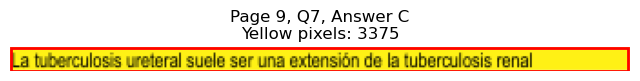

Page 9, Q7 - D: Detected box: x0=68.8, y0=543.8, x1=328.6, y1=556.4
Page 9, Q7, D: Yellow pixels: 311
Page 9, Q7, D: Total non-white pixels: 1560
Page 9, Q7, D: Yellow percentage: 19.9%


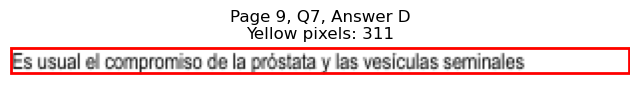

Page 9, Q7 - E: Detected box: x0=68.3, y0=556.5, x1=342.5, y1=569.2
Page 9, Q7, E: Yellow pixels: 0
Page 9, Q7, E: Total non-white pixels: 1366
Page 9, Q7, E: Yellow percentage: 0.0%


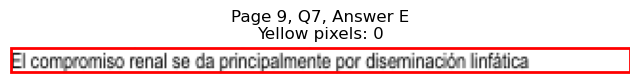


Page 9, Q7 - Selected Answer: C (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=68.3, y0=594.3, x1=139.6, y1=607.0
Page 9, Q8, A: Yellow pixels: 0
Page 9, Q8, A: Total non-white pixels: 475
Page 9, Q8, A: Yellow percentage: 0.0%


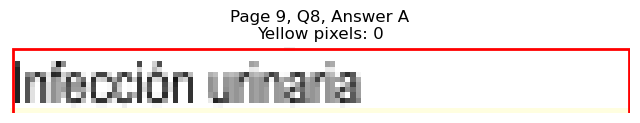

Page 9, Q8 - B: Detected box: x0=68.3, y0=606.9, x1=139.5, y1=619.6
Page 9, Q8, B: Yellow pixels: 1291
Page 9, Q8, B: Total non-white pixels: 1708
Page 9, Q8, B: Yellow percentage: 75.6%


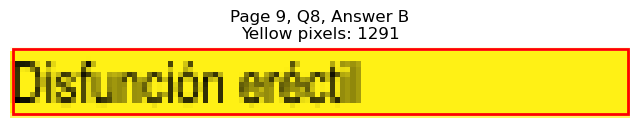

Page 9, Q8 - C: Detected box: x0=68.8, y0=619.6, x1=144.0, y1=632.3
Page 9, Q8, C: Yellow pixels: 127
Page 9, Q8, C: Total non-white pixels: 499
Page 9, Q8, C: Yellow percentage: 25.5%


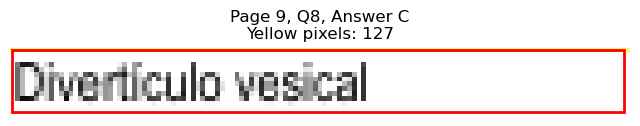

Page 9, Q8 - D: Detected box: x0=327.5, y0=594.3, x1=394.3, y1=607.0
Page 9, Q8, D: Yellow pixels: 0
Page 9, Q8, D: Total non-white pixels: 350
Page 9, Q8, D: Yellow percentage: 0.0%


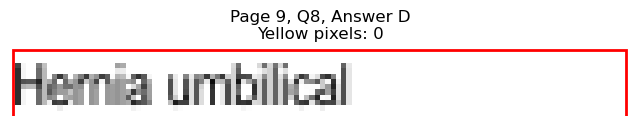

Page 9, Q8 - E: Detected box: x0=327.0, y0=606.9, x1=407.8, y1=619.6
Page 9, Q8, E: Yellow pixels: 0
Page 9, Q8, E: Total non-white pixels: 411
Page 9, Q8, E: Yellow percentage: 0.0%


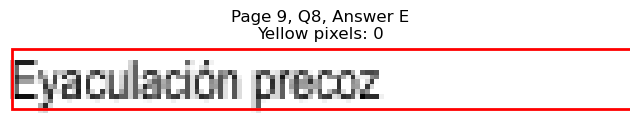


Page 9, Q8 - Selected Answer: B (based on yellow pixel count)




Page 9, Q9 - A: Detected box: x0=68.3, y0=657.5, x1=133.9, y1=670.1
Page 9, Q9, A: Yellow pixels: 0
Page 9, Q9, A: Total non-white pixels: 337
Page 9, Q9, A: Yellow percentage: 0.0%


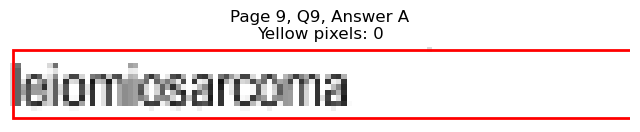

Page 9, Q9 - B: Detected box: x0=68.3, y0=670.1, x1=123.0, y1=682.7
Page 9, Q9, B: Yellow pixels: 0
Page 9, Q9, B: Total non-white pixels: 270
Page 9, Q9, B: Yellow percentage: 0.0%


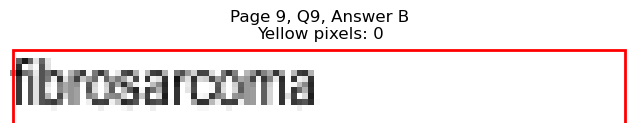

Page 9, Q9 - C: Detected box: x0=68.8, y0=682.7, x1=143.5, y1=695.3
Page 9, Q9, C: Yellow pixels: 0
Page 9, Q9, C: Total non-white pixels: 377
Page 9, Q9, C: Yellow percentage: 0.0%


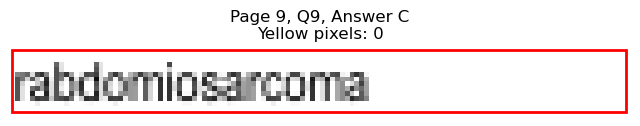

Page 9, Q9 - D: Detected box: x0=327.5, y0=657.5, x1=411.8, y1=670.1
Page 9, Q9, D: Yellow pixels: 135
Page 9, Q9, D: Total non-white pixels: 558
Page 9, Q9, D: Yellow percentage: 24.2%


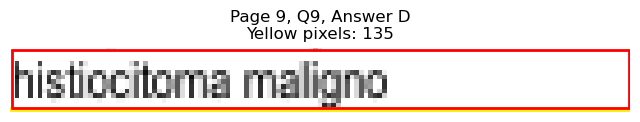

Page 9, Q9 - E: Detected box: x0=327.0, y0=670.1, x1=378.2, y1=682.7
Page 9, Q9, E: Yellow pixels: 1112
Page 9, Q9, E: Total non-white pixels: 1326
Page 9, Q9, E: Yellow percentage: 83.9%


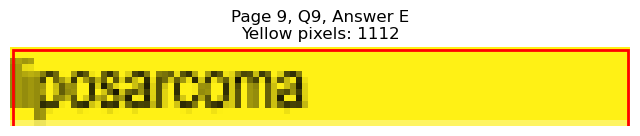


Page 9, Q9 - Selected Answer: E (based on yellow pixel count)




Page 9, Q10 - A: Detected box: x0=68.3, y0=733.2, x1=93.4, y1=745.8
Page 9, Q10, A: Yellow pixels: 916
Page 9, Q10, A: Total non-white pixels: 988
Page 9, Q10, A: Yellow percentage: 92.7%


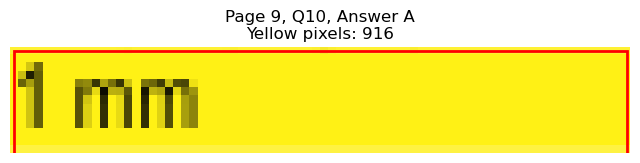

Page 9, Q10 - B: Detected box: x0=68.3, y0=745.8, x1=93.4, y1=758.4
Page 9, Q10, B: Yellow pixels: 76
Page 9, Q10, B: Total non-white pixels: 171
Page 9, Q10, B: Yellow percentage: 44.4%


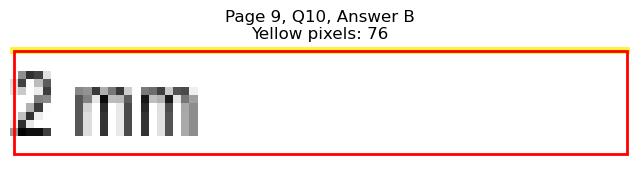

Page 9, Q10 - C: Detected box: x0=68.8, y0=758.5, x1=93.9, y1=771.2
Page 9, Q10, C: Yellow pixels: 0
Page 9, Q10, C: Total non-white pixels: 103
Page 9, Q10, C: Yellow percentage: 0.0%


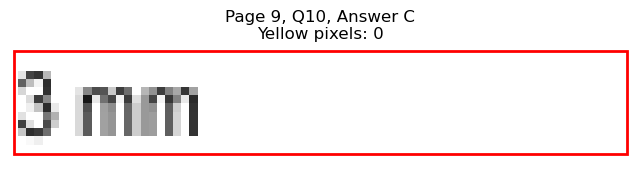

Page 9, Q10 - D: Detected box: x0=327.5, y0=733.2, x1=352.6, y1=745.8
Page 9, Q10, D: Yellow pixels: 0
Page 9, Q10, D: Total non-white pixels: 97
Page 9, Q10, D: Yellow percentage: 0.0%


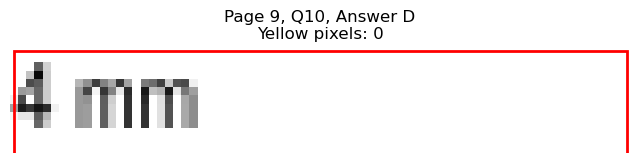

Page 9, Q10 - E: Detected box: x0=327.0, y0=745.8, x1=352.1, y1=758.4
Page 9, Q10, E: Yellow pixels: 0
Page 9, Q10, E: Total non-white pixels: 109
Page 9, Q10, E: Yellow percentage: 0.0%


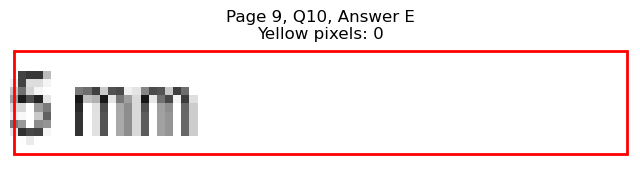


Page 9, Q10 - Selected Answer: A (based on yellow pixel count)





Page 10: Found 10 questions
Page 10, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=137.5, y1=114.7
Page 10, Q1, A: Yellow pixels: 0
Page 10, Q1, A: Total non-white pixels: 345
Page 10, Q1, A: Yellow percentage: 0.0%


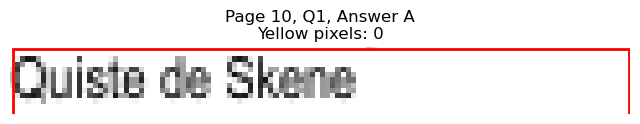

Page 10, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=166.1, y1=127.3
Page 10, Q1, B: Yellow pixels: 0
Page 10, Q1, B: Total non-white pixels: 484
Page 10, Q1, B: Yellow percentage: 0.0%


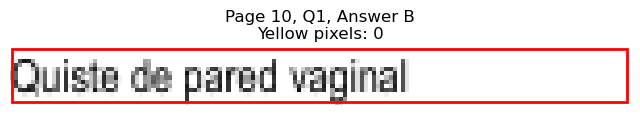

Page 10, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=142.0, y1=139.9
Page 10, Q1, C: Yellow pixels: 0
Page 10, Q1, C: Total non-white pixels: 359
Page 10, Q1, C: Yellow percentage: 0.0%


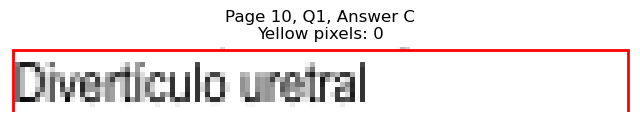

Page 10, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=401.8, y1=114.7
Page 10, Q1, D: Yellow pixels: 0
Page 10, Q1, D: Total non-white pixels: 496
Page 10, Q1, D: Yellow percentage: 0.0%


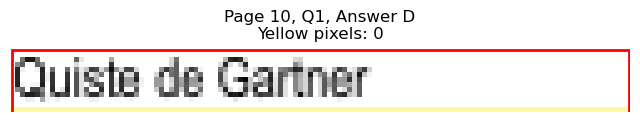

Page 10, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=398.8, y1=127.3
Page 10, Q1, E: Yellow pixels: 1189
Page 10, Q1, E: Total non-white pixels: 1708
Page 10, Q1, E: Yellow percentage: 69.6%


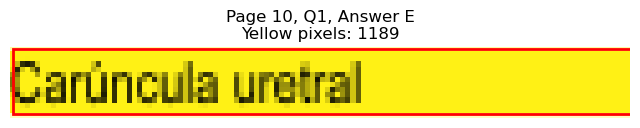


Page 10, Q1 - Selected Answer: E (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=121.0, y1=190.4
Page 10, Q2, A: Yellow pixels: 0
Page 10, Q2, A: Total non-white pixels: 272
Page 10, Q2, A: Yellow percentage: 0.0%


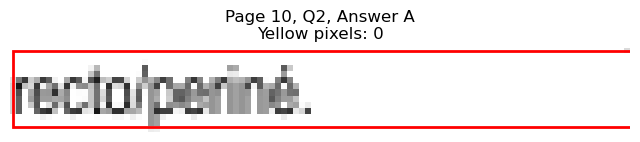

Page 10, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=154.1, y1=203.0
Page 10, Q2, B: Yellow pixels: 0
Page 10, Q2, B: Total non-white pixels: 431
Page 10, Q2, B: Yellow percentage: 0.0%


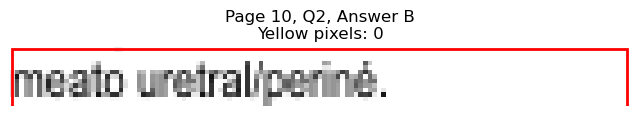

Page 10, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=157.6, y1=215.6
Page 10, Q2, C: Yellow pixels: 0
Page 10, Q2, C: Total non-white pixels: 463
Page 10, Q2, C: Yellow percentage: 0.0%


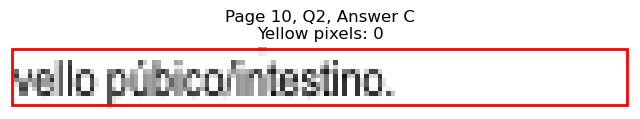

Page 10, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=426.9, y1=190.4
Page 10, Q2, D: Yellow pixels: 1431
Page 10, Q2, D: Total non-white pixels: 2100
Page 10, Q2, D: Yellow percentage: 68.1%


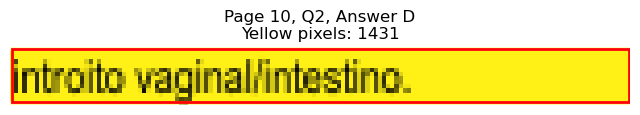

Page 10, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=440.5, y1=203.0
Page 10, Q2, E: Yellow pixels: 0
Page 10, Q2, E: Total non-white pixels: 749
Page 10, Q2, E: Yellow percentage: 0.0%


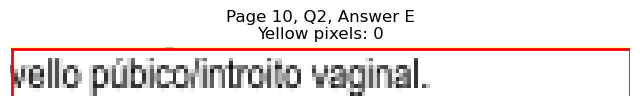


Page 10, Q2 - Selected Answer: D (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=108.4, y1=253.5
Page 10, Q3, A: Yellow pixels: 0
Page 10, Q3, A: Total non-white pixels: 209
Page 10, Q3, A: Yellow percentage: 0.0%


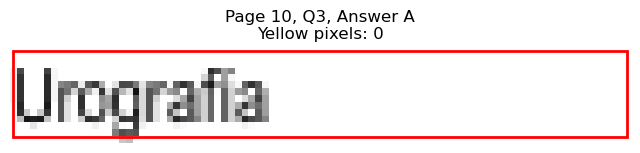

Page 10, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=116.9, y1=266.1
Page 10, Q3, B: Yellow pixels: 99
Page 10, Q3, B: Total non-white pixels: 332
Page 10, Q3, B: Yellow percentage: 29.8%


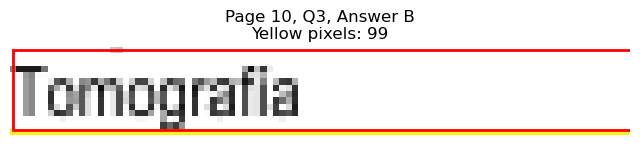

Page 10, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=109.9, y1=278.7
Page 10, Q3, C: Yellow pixels: 1034
Page 10, Q3, C: Total non-white pixels: 1196
Page 10, Q3, C: Yellow percentage: 86.5%


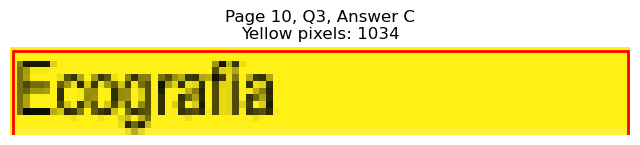

Page 10, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=385.3, y1=253.5
Page 10, Q3, D: Yellow pixels: 0
Page 10, Q3, D: Total non-white pixels: 295
Page 10, Q3, D: Yellow percentage: 0.0%


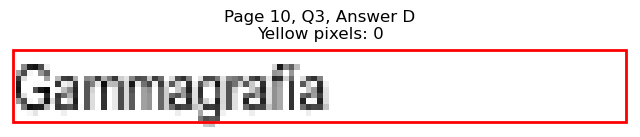

Page 10, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=376.3, y1=266.1
Page 10, Q3, E: Yellow pixels: 0
Page 10, Q3, E: Total non-white pixels: 257
Page 10, Q3, E: Yellow percentage: 0.0%


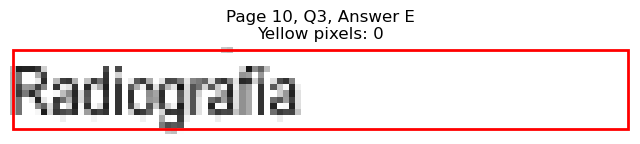


Page 10, Q3 - Selected Answer: C (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=188.7, y1=316.7
Page 10, Q4, A: Yellow pixels: 0
Page 10, Q4, A: Total non-white pixels: 582
Page 10, Q4, A: Yellow percentage: 0.0%


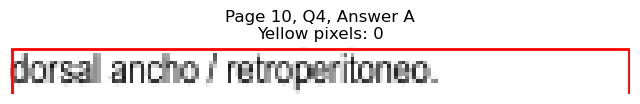

Page 10, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=176.7, y1=329.3
Page 10, Q4, B: Yellow pixels: 0
Page 10, Q4, B: Total non-white pixels: 539
Page 10, Q4, B: Yellow percentage: 0.0%


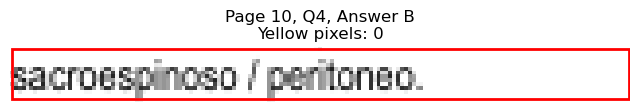

Page 10, Q4 - C: Detected box: x0=68.8, y0=329.2, x1=194.2, y1=341.9
Page 10, Q4, C: Yellow pixels: 0
Page 10, Q4, C: Total non-white pixels: 592
Page 10, Q4, C: Yellow percentage: 0.0%


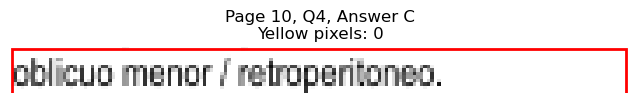

Page 10, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=464.0, y1=316.7
Page 10, Q4, D: Yellow pixels: 1901
Page 10, Q4, D: Total non-white pixels: 2431
Page 10, Q4, D: Yellow percentage: 78.2%


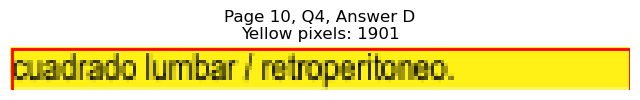

Page 10, Q4 - E: Detected box: x0=327.0, y0=316.6, x1=441.4, y1=329.3
Page 10, Q4, E: Yellow pixels: 165
Page 10, Q4, E: Total non-white pixels: 746
Page 10, Q4, E: Yellow percentage: 22.1%


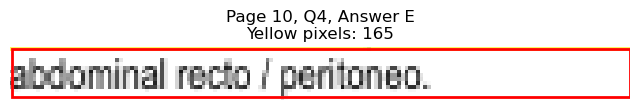


Page 10, Q4 - Selected Answer: D (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=68.3, y0=367.1, x1=87.4, y1=379.8
Page 10, Q5, A: Yellow pixels: 0
Page 10, Q5, A: Total non-white pixels: 147
Page 10, Q5, A: Yellow percentage: 0.0%


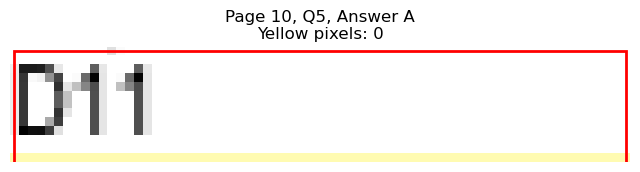

Page 10, Q5 - B: Detected box: x0=68.3, y0=379.7, x1=87.4, y1=392.4
Page 10, Q5, B: Yellow pixels: 784
Page 10, Q5, B: Total non-white pixels: 980
Page 10, Q5, B: Yellow percentage: 80.0%


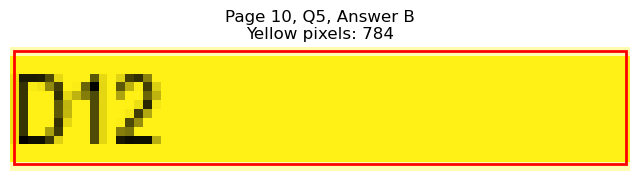

Page 10, Q5 - C: Detected box: x0=68.8, y0=392.3, x1=87.9, y1=405.0
Page 10, Q5, C: Yellow pixels: 0
Page 10, Q5, C: Total non-white pixels: 158
Page 10, Q5, C: Yellow percentage: 0.0%


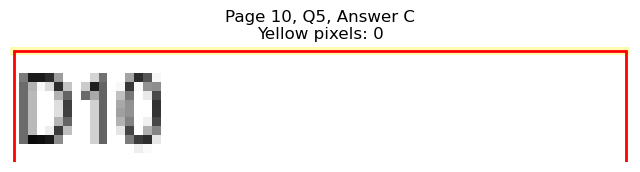

Page 10, Q5 - D: Detected box: x0=327.5, y0=367.1, x1=341.6, y1=379.8
Page 10, Q5, D: Yellow pixels: 0
Page 10, Q5, D: Total non-white pixels: 71
Page 10, Q5, D: Yellow percentage: 0.0%


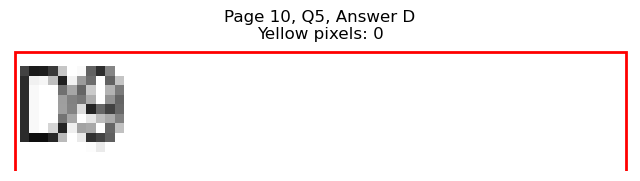

Page 10, Q5 - E: Detected box: x0=327.0, y0=379.7, x1=341.1, y1=392.4
Page 10, Q5, E: Yellow pixels: 0
Page 10, Q5, E: Total non-white pixels: 69
Page 10, Q5, E: Yellow percentage: 0.0%


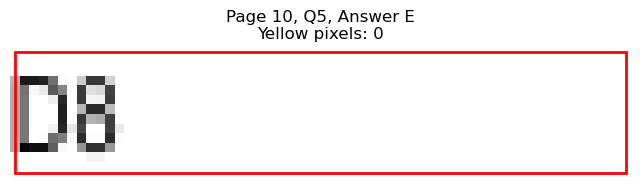


Page 10, Q5 - Selected Answer: B (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=166.6, y1=480.7
Page 10, Q6, A: Yellow pixels: 0
Page 10, Q6, A: Total non-white pixels: 484
Page 10, Q6, A: Yellow percentage: 0.0%


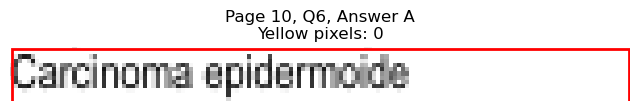

Page 10, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=109.5, y1=493.4
Page 10, Q6, B: Yellow pixels: 0
Page 10, Q6, B: Total non-white pixels: 201
Page 10, Q6, B: Yellow percentage: 0.0%


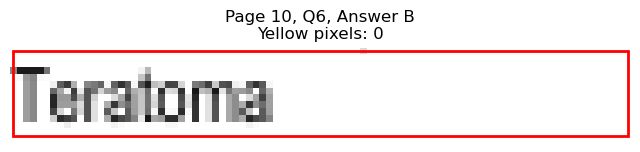

Page 10, Q6 - C: Detected box: x0=68.8, y0=493.4, x1=136.9, y1=506.0
Page 10, Q6, C: Yellow pixels: 0
Page 10, Q6, C: Total non-white pixels: 326
Page 10, Q6, C: Yellow percentage: 0.0%


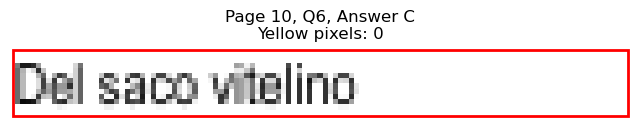

Page 10, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=373.1, y1=480.7
Page 10, Q6, D: Yellow pixels: 1084
Page 10, Q6, D: Total non-white pixels: 1261
Page 10, Q6, D: Yellow percentage: 86.0%


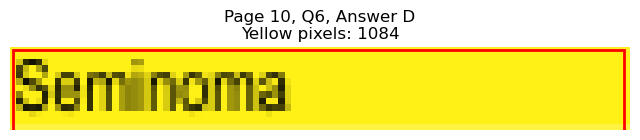

Page 10, Q6 - E: Detected box: x0=327.0, y0=480.8, x1=423.3, y1=493.4
Page 10, Q6, E: Yellow pixels: 147
Page 10, Q6, E: Total non-white pixels: 632
Page 10, Q6, E: Yellow percentage: 23.3%


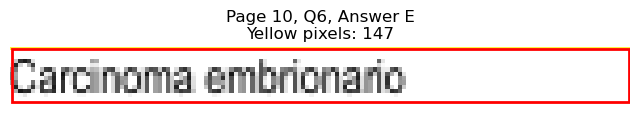


Page 10, Q6 - Selected Answer: D (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=158.1, y1=543.8
Page 10, Q7, A: Yellow pixels: 0
Page 10, Q7, A: Total non-white pixels: 455
Page 10, Q7, A: Yellow percentage: 0.0%


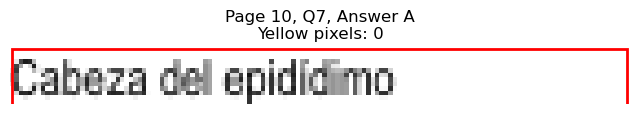

Page 10, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=113.4, y1=556.4
Page 10, Q7, B: Yellow pixels: 0
Page 10, Q7, B: Total non-white pixels: 244
Page 10, Q7, B: Yellow percentage: 0.0%


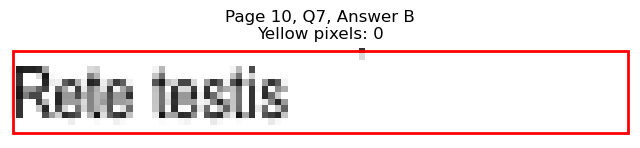

Page 10, Q7 - C: Detected box: x0=68.8, y0=556.5, x1=146.1, y1=569.2
Page 10, Q7, C: Yellow pixels: 1361
Page 10, Q7, C: Total non-white pixels: 1806
Page 10, Q7, C: Yellow percentage: 75.4%


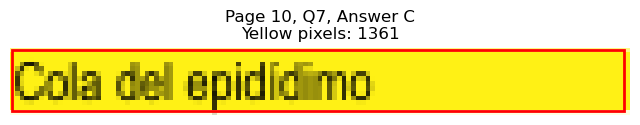

Page 10, Q7 - D: Detected box: x0=327.5, y0=531.2, x1=398.2, y1=543.8
Page 10, Q7, D: Yellow pixels: 0
Page 10, Q7, D: Total non-white pixels: 367
Page 10, Q7, D: Yellow percentage: 0.0%


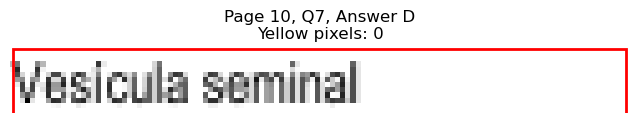

Page 10, Q7 - E: Detected box: x0=327.0, y0=543.8, x1=421.4, y1=556.4
Page 10, Q7, E: Yellow pixels: 0
Page 10, Q7, E: Total non-white pixels: 497
Page 10, Q7, E: Yellow percentage: 0.0%


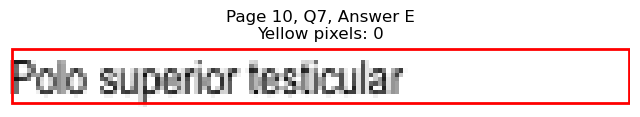


Page 10, Q7 - Selected Answer: C (based on yellow pixel count)




Page 10, Q8 - A: Detected box: x0=68.3, y0=594.3, x1=154.1, y1=607.0
Page 10, Q8, A: Yellow pixels: 0
Page 10, Q8, A: Total non-white pixels: 447
Page 10, Q8, A: Yellow percentage: 0.0%


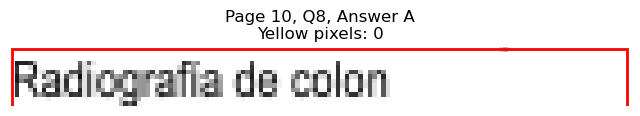

Page 10, Q8 - B: Detected box: x0=68.3, y0=606.9, x1=116.9, y1=619.6
Page 10, Q8, B: Yellow pixels: 0
Page 10, Q8, B: Total non-white pixels: 245
Page 10, Q8, B: Yellow percentage: 0.0%


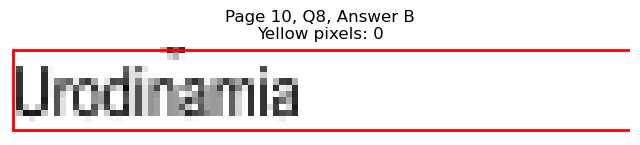

Page 10, Q8 - C: Detected box: x0=68.8, y0=619.6, x1=178.6, y1=632.3
Page 10, Q8, C: Yellow pixels: 1468
Page 10, Q8, C: Total non-white pixels: 2254
Page 10, Q8, C: Yellow percentage: 65.1%


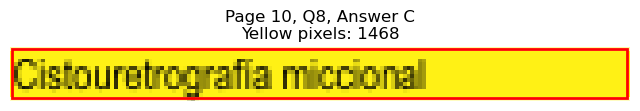

Page 10, Q8 - D: Detected box: x0=327.5, y0=594.3, x1=398.8, y1=607.0
Page 10, Q8, D: Yellow pixels: 0
Page 10, Q8, D: Total non-white pixels: 372
Page 10, Q8, D: Yellow percentage: 0.0%


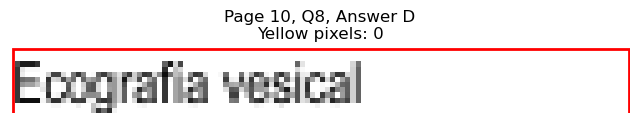

Page 10, Q8 - E: Detected box: x0=327.0, y0=606.9, x1=412.9, y1=619.6
Page 10, Q8, E: Yellow pixels: 0
Page 10, Q8, E: Total non-white pixels: 456
Page 10, Q8, E: Yellow percentage: 0.0%


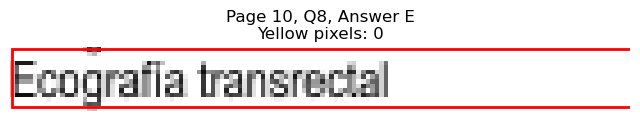


Page 10, Q8 - Selected Answer: C (based on yellow pixel count)




Page 10, Q9 - A: Detected box: x0=68.3, y0=657.5, x1=140.1, y1=670.1
Page 10, Q9, A: Yellow pixels: 0
Page 10, Q9, A: Total non-white pixels: 361
Page 10, Q9, A: Yellow percentage: 0.0%


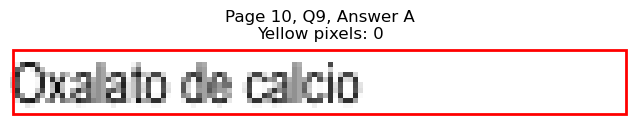

Page 10, Q9 - B: Detected box: x0=68.3, y0=670.1, x1=139.0, y1=682.7
Page 10, Q9, B: Yellow pixels: 0
Page 10, Q9, B: Total non-white pixels: 346
Page 10, Q9, B: Yellow percentage: 0.0%


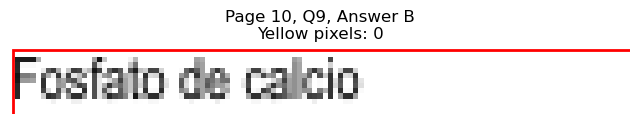

Page 10, Q9 - C: Detected box: x0=68.8, y0=682.7, x1=115.9, y1=695.3
Page 10, Q9, C: Yellow pixels: 0
Page 10, Q9, C: Total non-white pixels: 238
Page 10, Q9, C: Yellow percentage: 0.0%


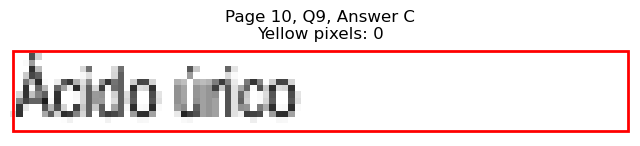

Page 10, Q9 - D: Detected box: x0=327.5, y0=657.5, x1=365.1, y1=670.1
Page 10, Q9, D: Yellow pixels: 1019
Page 10, Q9, D: Total non-white pixels: 1246
Page 10, Q9, D: Yellow percentage: 81.8%


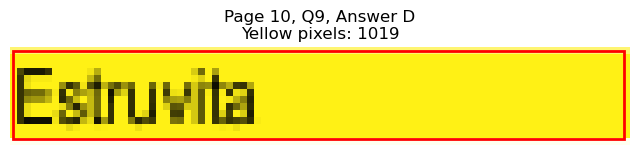

Page 10, Q9 - E: Detected box: x0=327.0, y0=670.1, x1=357.2, y1=682.7
Page 10, Q9, E: Yellow pixels: 0
Page 10, Q9, E: Total non-white pixels: 235
Page 10, Q9, E: Yellow percentage: 0.0%


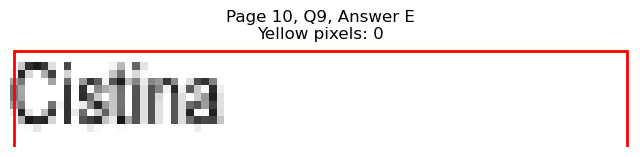


Page 10, Q9 - Selected Answer: D (based on yellow pixel count)




Page 10, Q10 - A: Detected box: x0=68.3, y0=720.6, x1=100.9, y1=733.2
Page 10, Q10, A: Yellow pixels: 0
Page 10, Q10, A: Total non-white pixels: 159
Page 10, Q10, A: Yellow percentage: 0.0%


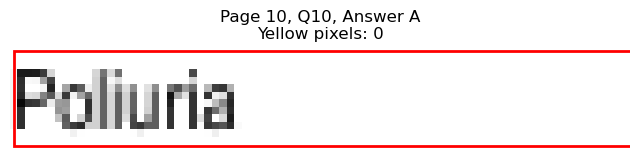

Page 10, Q10 - B: Detected box: x0=68.3, y0=733.2, x1=125.4, y1=745.8
Page 10, Q10, B: Yellow pixels: 0
Page 10, Q10, B: Total non-white pixels: 309
Page 10, Q10, B: Yellow percentage: 0.0%


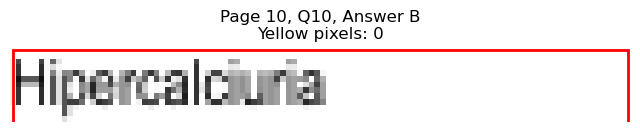

Page 10, Q10 - C: Detected box: x0=68.8, y0=745.8, x1=124.5, y1=758.4
Page 10, Q10, C: Yellow pixels: 0
Page 10, Q10, C: Total non-white pixels: 304
Page 10, Q10, C: Yellow percentage: 0.0%


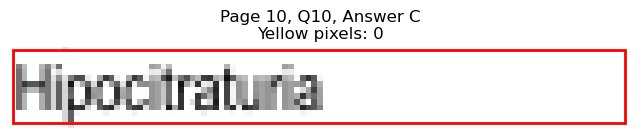

Page 10, Q10 - D: Detected box: x0=327.5, y0=720.6, x1=393.8, y1=733.2
Page 10, Q10, D: Yellow pixels: 1286
Page 10, Q10, D: Total non-white pixels: 1638
Page 10, Q10, D: Yellow percentage: 78.5%


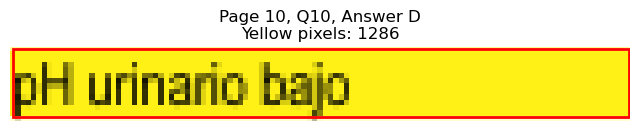

Page 10, Q10 - E: Detected box: x0=327.0, y0=733.2, x1=397.3, y1=745.8
Page 10, Q10, E: Yellow pixels: 0
Page 10, Q10, E: Total non-white pixels: 497
Page 10, Q10, E: Yellow percentage: 0.0%


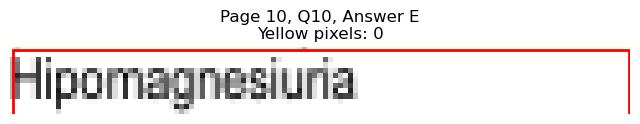


Page 10, Q10 - Selected Answer: D (based on yellow pixel count)





Page 11: Found 4 questions
Page 11, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=105.9, y1=114.7
Page 11, Q1, A: Yellow pixels: 0
Page 11, Q1, A: Total non-white pixels: 168
Page 11, Q1, A: Yellow percentage: 0.0%


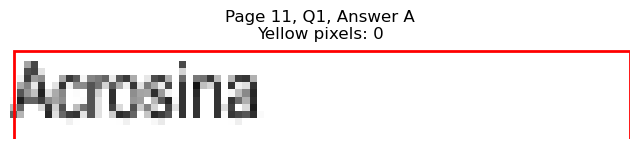

Page 11, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=105.9, y1=127.3
Page 11, Q1, B: Yellow pixels: 88
Page 11, Q1, B: Total non-white pixels: 266
Page 11, Q1, B: Yellow percentage: 33.1%


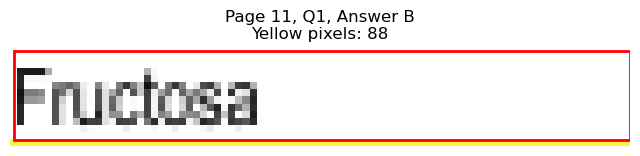

Page 11, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=88.3, y1=139.9
Page 11, Q1, C: Yellow pixels: 855
Page 11, Q1, C: Total non-white pixels: 923
Page 11, Q1, C: Yellow percentage: 92.6%


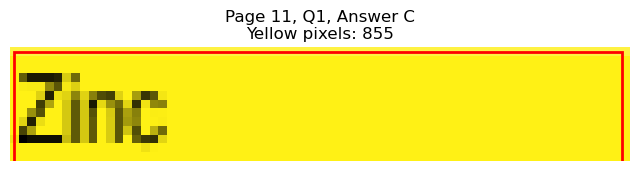

Page 11, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=372.2, y1=114.7
Page 11, Q1, D: Yellow pixels: 0
Page 11, Q1, D: Total non-white pixels: 207
Page 11, Q1, D: Yellow percentage: 0.0%


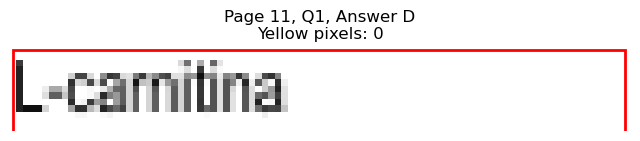

Page 11, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=354.2, y1=127.3
Page 11, Q1, E: Yellow pixels: 0
Page 11, Q1, E: Total non-white pixels: 125
Page 11, Q1, E: Yellow percentage: 0.0%


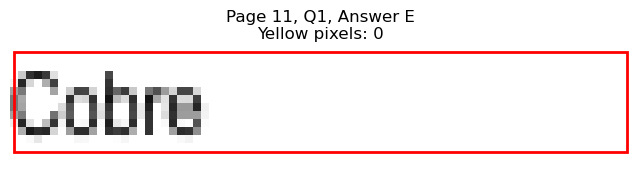


Page 11, Q1 - Selected Answer: C (based on yellow pixel count)




Page 11, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=129.5, y1=177.8
Page 11, Q2, A: Yellow pixels: 0
Page 11, Q2, A: Total non-white pixels: 320
Page 11, Q2, A: Yellow percentage: 0.0%


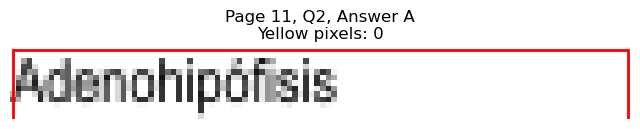

Page 11, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=118.0, y1=190.4
Page 11, Q2, B: Yellow pixels: 0
Page 11, Q2, B: Total non-white pixels: 236
Page 11, Q2, B: Yellow percentage: 0.0%


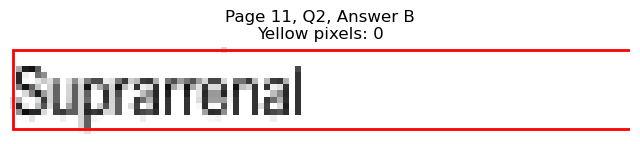

Page 11, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=112.5, y1=203.0
Page 11, Q2, C: Yellow pixels: 0
Page 11, Q2, C: Total non-white pixels: 209
Page 11, Q2, C: Yellow percentage: 0.0%


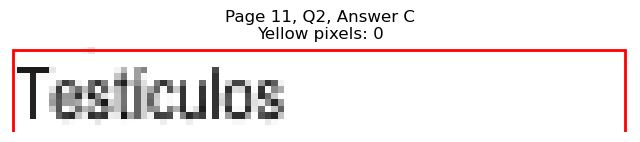

Page 11, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=359.1, y1=177.8
Page 11, Q2, D: Yellow pixels: 1
Page 11, Q2, D: Total non-white pixels: 240
Page 11, Q2, D: Yellow percentage: 0.4%


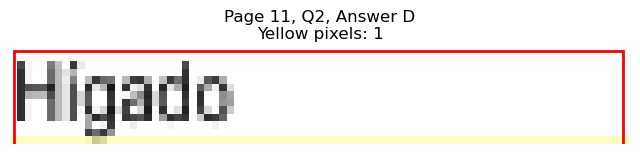

Page 11, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=363.2, y1=190.4
Page 11, Q2, E: Yellow pixels: 898
Page 11, Q2, E: Total non-white pixels: 1218
Page 11, Q2, E: Yellow percentage: 73.7%


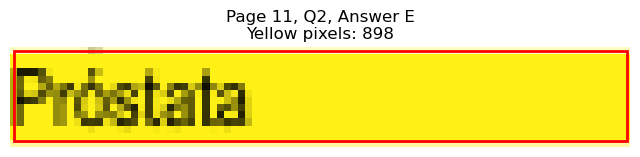


Page 11, Q2 - Selected Answer: E (based on yellow pixel count)




Page 11, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=141.5, y1=266.1
Page 11, Q3, A: Yellow pixels: 0
Page 11, Q3, A: Total non-white pixels: 374
Page 11, Q3, A: Yellow percentage: 0.0%


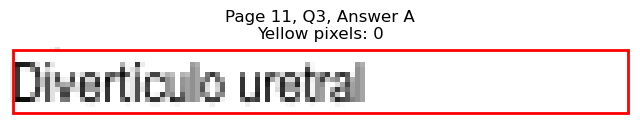

Page 11, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=140.1, y1=278.7
Page 11, Q3, B: Yellow pixels: 0
Page 11, Q3, B: Total non-white pixels: 334
Page 11, Q3, B: Yellow percentage: 0.0%


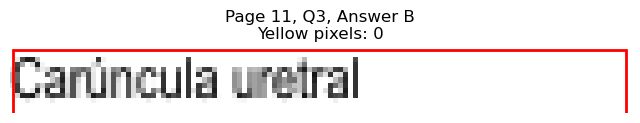

Page 11, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=155.1, y1=291.5
Page 11, Q3, C: Yellow pixels: 0
Page 11, Q3, C: Total non-white pixels: 412
Page 11, Q3, C: Yellow percentage: 0.0%


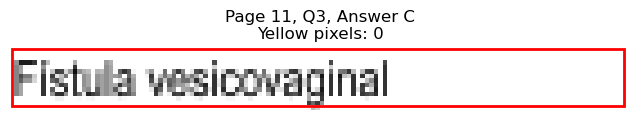

Page 11, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=417.8, y1=266.1
Page 11, Q3, D: Yellow pixels: 1436
Page 11, Q3, D: Total non-white pixels: 1974
Page 11, Q3, D: Yellow percentage: 72.7%


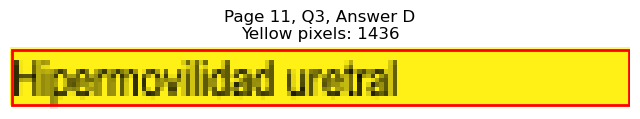

Page 11, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=402.3, y1=278.7
Page 11, Q3, E: Yellow pixels: 0
Page 11, Q3, E: Total non-white pixels: 502
Page 11, Q3, E: Yellow percentage: 0.0%


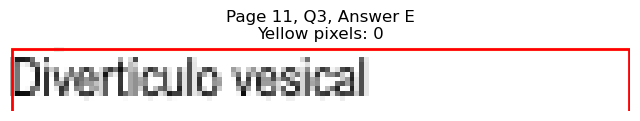


Page 11, Q3 - Selected Answer: D (based on yellow pixel count)




Page 11, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=153.0, y1=329.3
Page 11, Q4, A: Yellow pixels: 0
Page 11, Q4, A: Total non-white pixels: 403
Page 11, Q4, A: Yellow percentage: 0.0%


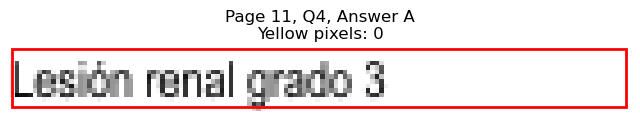

Page 11, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=179.7, y1=341.9
Page 11, Q4, B: Yellow pixels: 0
Page 11, Q4, B: Total non-white pixels: 564
Page 11, Q4, B: Yellow percentage: 0.0%


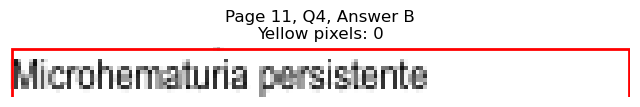

Page 11, Q4 - C: Detected box: x0=68.8, y0=341.9, x1=153.5, y1=354.6
Page 11, Q4, C: Yellow pixels: 0
Page 11, Q4, C: Total non-white pixels: 391
Page 11, Q4, C: Yellow percentage: 0.0%


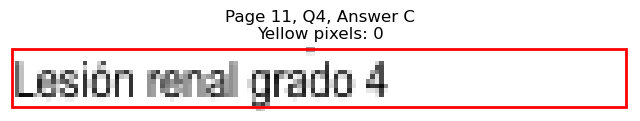

Page 11, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=435.4, y1=329.3
Page 11, Q4, D: Yellow pixels: 159
Page 11, Q4, D: Total non-white pixels: 739
Page 11, Q4, D: Yellow percentage: 21.5%


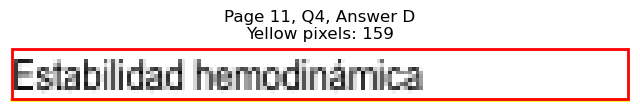

Page 11, Q4 - E: Detected box: x0=327.0, y0=329.2, x1=475.0, y1=341.9
Page 11, Q4, E: Yellow pixels: 1981
Page 11, Q4, E: Total non-white pixels: 2574
Page 11, Q4, E: Yellow percentage: 77.0%


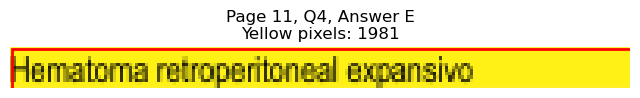


Page 11, Q4 - Selected Answer: E (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,¿Qué anticolinérgico solo actúa en los recepto...
1,Lactante varón de 8 meses con poca ganancia po...
2,¿Qué caracteriza a las infecciones urinarias p...
3,"En el riñón, las arterias interlobulares se ra..."
4,Se define hiperactividad vesical cuando la con...
...,...
95,¿Cuál es un determinante principal en la forma...
96,¿Cuál sustancia es necesaria para la desconden...
97,¿Cuál es el sitio de acción del finasteride?
98,Mujer de 70 años con escape de orina al esfuer...


In [8]:
answers_df

,option_A,option_B,option_C,option_D,option_E
0,Oxibutinina,Solifenacina,Darifenacina,Flavoxato,Tolterodina
1,Otitis media,Apendicitis,Neumonía,Urolitiasis,Infección urinaria
2,No evolucionan a un proceso de nefroesclerosis,Son más frecuentes durante el primer año de vida,La incidencia es 10 veces mayor en los lactantes,Hay una asociación precisa entre síntomas y lo...,Las pilosidades o las fimbrias bacterianas dis...
3,interlobulillares.,segmentarias.,aferentes.,eferentes.,arcuatas.
4,15 / inferior a 300 ml.,15 / superior a 500 ml.,10 / inferior a 100 ml.,15 / superior a 300 ml.,10 / superior a 100 ml.
...,...,...,...,...,...
95,Poliuria,Hipercalciuria,Hipocitraturia,pH urinario bajo,Hipomagnesiuria
96,Acrosina,Fructosa,Zinc,L-carnitina,Cobre
97,Adenohipófisis,Suprarrenal,Testículos,Hígado,Próstata
98,Divertículo uretral,Carúncula uretral,Fístula vesicovaginal,Hipermovilidad uretral,Divertículo vesical


In [9]:
correct_answers_df

,correct_answer
0,C
1,E
2,B
3,E
4,A
...,...
95,D
96,C
97,E
98,D


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "option_E", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,option_E,correct_answer
0,¿Qué anticolinérgico solo actúa en los recepto...,Oxibutinina,Solifenacina,Darifenacina,Flavoxato,Tolterodina,C
1,Lactante varón de 8 meses con poca ganancia po...,Otitis media,Apendicitis,Neumonía,Urolitiasis,Infección urinaria,E
2,¿Qué caracteriza a las infecciones urinarias p...,No evolucionan a un proceso de nefroesclerosis,Son más frecuentes durante el primer año de vida,La incidencia es 10 veces mayor en los lactantes,Hay una asociación precisa entre síntomas y lo...,Las pilosidades o las fimbrias bacterianas dis...,B
3,"En el riñón, las arterias interlobulares se ra...",interlobulillares.,segmentarias.,aferentes.,eferentes.,arcuatas.,E
4,Se define hiperactividad vesical cuando la con...,15 / inferior a 300 ml.,15 / superior a 500 ml.,10 / inferior a 100 ml.,15 / superior a 300 ml.,10 / superior a 100 ml.,A
...,...,...,...,...,...,...,...
95,¿Cuál es un determinante principal en la forma...,Poliuria,Hipercalciuria,Hipocitraturia,pH urinario bajo,Hipomagnesiuria,D
96,¿Cuál sustancia es necesaria para la desconden...,Acrosina,Fructosa,Zinc,L-carnitina,Cobre,C
97,¿Cuál es el sitio de acción del finasteride?,Adenohipófisis,Suprarrenal,Testículos,Hígado,Próstata,E
98,Mujer de 70 años con escape de orina al esfuer...,Divertículo uretral,Carúncula uretral,Fístula vesicovaginal,Hipermovilidad uretral,Divertículo vesical,D


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Urología.csv
